#Uploading the dataset

In [132]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import re

# Upload the existing CADEC ZIP file
from google.colab import files

uploaded = files.upload()

# Get the uploaded file's name
ZIP_PATH = Path(next(iter(uploaded)))

print("Uploaded file:", ZIP_PATH.name)

Saving CADEC.v2.zip to CADEC.v2 (1).zip
Uploaded file: CADEC.v2 (1).zip


#Check the dataset

In [133]:
# Check that the uploaded file exists
if not ZIP_PATH.exists():
    raise FileNotFoundError(f"File not found: {ZIP_PATH}")

# Inspect the existing dataset without modifying it
with ZipFile(ZIP_PATH, "r") as dataset:
    files = dataset.namelist()

    print("Dataset accessed successfully!")
    print("Total entries:", len(files))
    print("\nExample text files:")

    text_files = [
        file for file in files
        if file.endswith(".txt")
    ]

    for file in text_files[:5]:
        print(file)

    print("\nTotal patient text files:", len(text_files))

Dataset accessed successfully!
Total entries: 5005

Example text files:
cadec/text/ARTHROTEC.1.txt
cadec/text/ARTHROTEC.10.txt
cadec/text/ARTHROTEC.100.txt
cadec/text/ARTHROTEC.101.txt
cadec/text/ARTHROTEC.102.txt

Total patient text files: 1250


In [134]:
with ZipFile(ZIP_PATH, "r") as dataset:

    all_files = dataset.namelist()

    folders = {
        "Patient text files": "cadec/text/",
        "Original annotations": "cadec/original/",
        "MedDRA mappings": "cadec/meddra/",
        "SNOMED CT mappings": "cadec/sct/"
    }

    for name, folder in folders.items():

        if folder.endswith("text/"):
            extension = ".txt"
        else:
            extension = ".ann"

        matching_files = [
            f for f in all_files
            if f.startswith(folder) and f.endswith(extension)
        ]

        print(f"{name}: {len(matching_files)}")

Patient text files: 1250
Original annotations: 1250
MedDRA mappings: 1250
SNOMED CT mappings: 1250


#Inspecting one example

In [135]:
# Choose one patient post to inspect
sample_id = "ARTHROTEC.8"

# Corresponding files in the existing dataset
sample_files = {
    "Patient's original text": f"cadec/text/{sample_id}.txt",
    "Original medical annotations": f"cadec/original/{sample_id}.ann",
    "MedDRA mappings": f"cadec/meddra/{sample_id}.ann",
    "SNOMED CT mappings": f"cadec/sct/{sample_id}.ann"
}

with ZipFile(ZIP_PATH, "r") as dataset:

    for title, file_path in sample_files.items():
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)

        content = dataset.read(file_path).decode(
            "utf-8", errors="replace"
        )

        print(content if content.strip() else "[No annotations]")


Patient's original text
No side effect to begin, but now starting to upset my stomach even while taking with food and plenty of water.
Didn't work for me.
Still can't sleep, can't work without pain.
Didn't see any positive change.


Original medical annotations
T1	ADR 33 61	starting to upset my stomach
T2	Symptom 169 173	pain
T3	Symptom 137 148	can't sleep


MedDRA mappings
TT1	10042076 33 61	starting to upset my stomach


SNOMED CT mappings
TT1	271681002 | Stomach ache | 33 61	starting to upset my stomach
TT3	193462001 | Insomnia | 137 148	can't sleep
TT2	22253000 | Pain | 169 173	pain



#Load the existing data into tables

In [136]:
# Step 4: Load CADEC data with robust annotation parsing

from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import re


def split_ann_line(line):
    """Read annotation rows with tabs or multiple-space separators."""
    raw = line.rstrip("\r\n")

    if "\t" in raw:
        parts = raw.split("\t", 2)

        if len(parts) == 3:
            return (
                parts[0].strip(),
                parts[1].strip(),
                parts[2].strip()
            )

        if len(parts) == 2:
            left, mention = parts
            fields = left.strip().split(maxsplit=1)

            if len(fields) == 2:
                return fields[0], fields[1].strip(), mention.strip()

    # Some annotation rows use multiple spaces instead of tabs
    parts = re.split(r"\s{2,}", raw.strip(), maxsplit=2)

    if len(parts) == 3:
        return tuple(part.strip() for part in parts)

    return None


def parse_offsets(offset_text):
    """Preserve continuous and discontinuous character spans."""
    offset_text = offset_text.strip()

    pattern = r"\d+\s+\d+(?:;\s*\d+\s+\d+)*"

    if not re.fullmatch(pattern, offset_text):
        return None

    spans = [
        (int(start), int(end))
        for start, end in re.findall(
            r"(\d+)\s+(\d+)", offset_text
        )
    ]

    # Sort segments by their position in the original text
    return sorted(spans, key=lambda span: span[0])


def parse_span_suffix(details):
    """Separate concept information from the trailing character offsets."""
    match = re.fullmatch(
        r"(.*?)\s+(\d+\s+\d+(?:;\s*\d+\s+\d+)*)",
        details.strip()
    )

    if not match:
        return None

    prefix = match.group(1).strip()
    spans = parse_offsets(match.group(2))

    if spans is None:
        return None

    return prefix, spans


def span_metadata(spans):
    """Create a consistent key for matching annotation mappings."""
    return {
        "spans": tuple(spans),
        "span_key": ";".join(
            f"{start}:{end}" for start, end in spans
        ),
        "start": spans[0][0],
        "end": spans[-1][1],
        "is_discontinuous": len(spans) > 1
    }


documents = []
original_annotations = []
meddra_mappings = []
snomed_mappings = []

with ZipFile(ZIP_PATH, "r") as dataset:

    all_files = set(dataset.namelist())

    text_files = sorted(
        f for f in all_files
        if f.startswith("cadec/text/")
        and f.endswith(".txt")
    )

    for text_path in text_files:

        doc_id = Path(text_path).stem

        # Load the original patient post
        text = dataset.read(text_path).decode(
            "utf-8", errors="replace"
        )

        documents.append({
            "doc_id": doc_id,
            "text": text
        })

        # Load each existing annotation file
        for category in ["original", "meddra", "sct"]:

            ann_path = f"cadec/{category}/{doc_id}.ann"

            if ann_path not in all_files:
                continue

            content = dataset.read(ann_path).decode(
                "utf-8", errors="replace"
            )

            for line in content.splitlines():

                if not line.strip() or line.lstrip().startswith("#"):
                    continue

                parsed = split_ann_line(line)

                if parsed is None:
                    continue

                annotation_id, details, mention = parsed

                # Original entity labels
                if category == "original":

                    match = re.fullmatch(
                        r"(\S+)\s+(\d+\s+\d+(?:;\s*\d+\s+\d+)*)",
                        details.strip()
                    )

                    if not match:
                        continue

                    entity_type, offset_text = match.groups()
                    spans = parse_offsets(offset_text)

                    if spans is None:
                        continue

                    record = {
                        "doc_id": doc_id,
                        "entity_id": annotation_id,
                        "entity_type": entity_type,
                        "mention": mention
                    }

                    record.update(span_metadata(spans))
                    original_annotations.append(record)

                # MedDRA mappings
                elif category == "meddra":

                    parsed_mapping = parse_span_suffix(details)

                    if parsed_mapping is None:
                        continue

                    concept_id, spans = parsed_mapping

                    record = {
                        "doc_id": doc_id,
                        "meddra_id": concept_id,
                        "mention": mention
                    }

                    record.update(span_metadata(spans))
                    meddra_mappings.append(record)

                # SNOMED CT mappings
                elif category == "sct":

                    parsed_mapping = parse_span_suffix(details)

                    if parsed_mapping is None:
                        continue

                    concept_info, spans = parsed_mapping

                    if "|" in concept_info:
                        concept_id, concept_name = (
                            concept_info.split("|", 1)
                        )

                        concept_id = concept_id.strip()
                        concept_name = (
                            concept_name.strip().strip("|").strip()
                            or None
                        )
                    else:
                        # Some entries have no standardized concept
                        concept_id = concept_info.strip()
                        concept_name = None

                    record = {
                        "doc_id": doc_id,
                        "snomed_id": concept_id,
                        "snomed_name": concept_name,
                        "mention": mention
                    }

                    record.update(span_metadata(spans))
                    snomed_mappings.append(record)


# Create structured tables
documents_df = pd.DataFrame(documents)
entities_df = pd.DataFrame(original_annotations)
meddra_df = pd.DataFrame(meddra_mappings)
snomed_df = pd.DataFrame(snomed_mappings)


# Link mappings to original annotations using document ID and spans
annotated_df = entities_df.merge(
    meddra_df[["doc_id", "span_key", "meddra_id"]],
    on=["doc_id", "span_key"],
    how="left",
    validate="one_to_one"
)

annotated_df = annotated_df.merge(
    snomed_df[["doc_id", "span_key", "snomed_id", "snomed_name"]],
    on=["doc_id", "span_key"],
    how="left",
    validate="one_to_one"
)

# Include the original patient text
annotated_df = annotated_df.merge(
    documents_df,
    on="doc_id",
    how="left",
    validate="many_to_one"
)


# Report the results
print("DATA LOADED AND MATCHED")
print("-" * 45)

print("Patient posts:", len(documents_df))
print("Original annotations:", len(entities_df))
print("MedDRA mapping entries:", len(meddra_df))
print("SNOMED CT mapping entries:", len(snomed_df))
print(
    "Discontinuous original annotations:",
    int(entities_df["is_discontinuous"].sum())
)

print("\nOriginal annotation label counts:")
print(entities_df["entity_type"].value_counts())

print("\nExample combined annotations:")
display(
    annotated_df[
        [
            "doc_id",
            "entity_type",
            "mention",
            "meddra_id",
            "snomed_id",
            "snomed_name"
        ]
    ].head(10)
)

DATA LOADED AND MATCHED
---------------------------------------------
Patient posts: 1250
Original annotations: 9111
MedDRA mapping entries: 6318
SNOMED CT mapping entries: 9111
Discontinuous original annotations: 1066

Original annotation label counts:
entity_type
ADR        6318
Drug       1800
Finding     435
Disease     283
Symptom     275
Name: count, dtype: int64

Example combined annotations:


,doc_id,entity_type,mention,meddra_id,snomed_id,snomed_name
0,ARTHROTEC.1,ADR,bit drowsy,10013649,271782001,Drowsy
1,ARTHROTEC.1,ADR,little blurred vision,10005886,246636008,Blurred vision - hazy
2,ARTHROTEC.1,Drug,Arthrotec,NaN,3384011000036100,Arthrotec
3,ARTHROTEC.1,Disease,arthritis,NaN,3723001,Arthritis
4,ARTHROTEC.1,Symptom,agony,NaN,102498003,Agony | or 76948002|Severe pain
5,ARTHROTEC.1,ADR,gastric problems,10056819,162076009,Excessive upper gastrointestinal gas
6,ARTHROTEC.1,Symptom,pains,NaN,22253000,Pain
7,ARTHROTEC.1,ADR,feel a bit weird,10025482,367391008,Malaise
8,ARTHROTEC.10,Symptom,hip pain,NaN,49218002,Hip pain
9,ARTHROTEC.10,Symptom,walk up & down steps sideways,NaN,CONCEPT_LESS,None


#Check that the annotations match the original text

In [137]:
# Step 5: Validate annotation spans against the original text

import re
import pandas as pd

# Make patient posts easy to look up
text_lookup = documents_df.set_index("doc_id")["text"].to_dict()


def normalize_for_comparison(text):
    """Ignore differences in capitalization and whitespace."""
    return re.sub(r"\s+", " ", str(text)).strip().casefold()


validation_results = []

for row in entities_df.itertuples(index=False):

    original_text = text_lookup[row.doc_id]

    # Retrieve each annotated segment from the original post
    segments = [
        original_text[start:end]
        for start, end in row.spans
    ]

    # Join segments for comparison, including discontinuous mentions
    reconstructed = " ".join(segments)

    matches = (
        normalize_for_comparison(reconstructed)
        == normalize_for_comparison(row.mention)
    )

    validation_results.append({
        "doc_id": row.doc_id,
        "entity_type": row.entity_type,
        "mention": row.mention,
        "reconstructed": reconstructed,
        "is_discontinuous": row.is_discontinuous,
        "matches": matches
    })


validation_df = pd.DataFrame(validation_results)

print("ANNOTATION VALIDATION")
print("-" * 45)

print("Total annotations checked:", len(validation_df))
print(
    "Exact text reconstructions:",
    int(validation_df["matches"].sum())
)
print(
    "Reconstruction match rate:",
    f"{validation_df['matches'].mean() * 100:.2f}%"
)

print("\nResults by annotation type:")
display(
    validation_df.groupby("is_discontinuous")["matches"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Annotations",
        "sum": "Matches",
        "mean": "Match rate"
    })
)

# Inspect mismatches rather than silently ignoring them
mismatches = validation_df[~validation_df["matches"]]

print("\nNumber of mismatches:", len(mismatches))

if not mismatches.empty:
    display(mismatches.head(10))

ANNOTATION VALIDATION
---------------------------------------------
Total annotations checked: 9111
Exact text reconstructions: 9064
Reconstruction match rate: 99.48%

Results by annotation type:


,Annotations,Matches,Match rate
is_discontinuous,,,
False,8045,8044,0.999876
True,1066,1020,0.956848



Number of mismatches: 47


,doc_id,entity_type,mention,reconstructed,is_discontinuous,matches
525,ARTHROTEC.35,ADR,bleeding several times a month menstrual cycle...,menstrual cycle is completely out of whack ble...,True,False
932,ARTHROTEC.95,ADR,swelling feet,feet swelling,True,False
1083,DICLOFENAC-SODIUM.7,ADR,renal failure,rena failure,True,False
1084,DICLOFENAC-SODIUM.7,ADR,renal and respiratory failure,respiratory failure,False,False
1817,LIPITOR.18,ADR,Severe pain shoulder,Severe shoulder pain,True,False
1946,LIPITOR.189,ADR,feet numbing,numbing feet,True,False
2620,LIPITOR.264,ADR,in both legs pain,pain in both legs,True,False
2621,LIPITOR.264,ADR,in both legs weakness,weakness in both legs,True,False
2732,LIPITOR.273,ADR,pain muscle,muscle pain,True,False
2735,LIPITOR.273,ADR,legs tingling in,tingling in legs,True,False


#Inspecting the mismatches

In [138]:
# Step 6: Investigate annotation mismatches

# Inspect up to 15 mismatches
mismatch_indices = mismatches.index[:15]

with ZipFile(ZIP_PATH, "r") as dataset:

    for idx in mismatch_indices:

        # Retrieve the corresponding annotation
        row = entities_df.iloc[idx]
        validation_row = validation_df.loc[idx]

        print("\n" + "=" * 70)
        print(f"Document: {row.doc_id}")
        print(f"Entity ID: {row.entity_id}")
        print(f"Label: {row.entity_type}")
        print(f"Discontinuous: {row.is_discontinuous}")

        # Original annotation as recorded in CADEC
        ann_path = f"cadec/original/{row.doc_id}.ann"
        annotation_file = dataset.read(ann_path).decode(
            "utf-8", errors="replace"
        )

        for line in annotation_file.splitlines():
            if line.startswith(row.entity_id + "\t"):
                print("Original annotation line:", line)
                break

        print("Annotated phrase:", repr(row.mention))

        # Show what each character span retrieves from the post
        original_text = text_lookup[row.doc_id]

        print("Extracted text segments:")
        for start, end in row.spans:
            print(
                f"  Characters {start}:{end} -> "
                f"{repr(original_text[start:end])}"
            )

        print(
            "Reconstructed phrase:",
            repr(validation_row["reconstructed"])
        )


Document: ARTHROTEC.35
Entity ID: T8
Label: ADR
Discontinuous: True
Original annotation line: T8	ADR 135 165;87 129	bleeding several times a month menstrual cycle is completely out of whack
Annotated phrase: 'bleeding several times a month menstrual cycle is completely out of whack'
Extracted text segments:
  Characters 87:129 -> 'menstrual cycle is completely out of whack'
  Characters 135:165 -> 'bleeding several times a month'
Reconstructed phrase: 'menstrual cycle is completely out of whack bleeding several times a month'

Document: ARTHROTEC.95
Entity ID: T2
Label: ADR
Discontinuous: True
Original annotation line: T2	ADR 115 123;91 95	swelling feet
Annotated phrase: 'swelling feet'
Extracted text segments:
  Characters 91:95 -> 'feet'
  Characters 115:123 -> 'swelling'
Reconstructed phrase: 'feet swelling'

Document: DICLOFENAC-SODIUM.7
Entity ID: T7
Label: ADR
Discontinuous: True
Original annotation line: T7	ADR 411 415;432 440	renal failure
Annotated phrase: 'renal failure'
Ext

#Separate word-order differences from possible errors

In [139]:
from collections import Counter
import re

# Tokenize phrases while preserving contractions
def get_tokens(text):
    return re.findall(
        r"\b[\w]+(?:['’][\w]+)*\b",
        str(text).casefold()
    )


# Compare the words, ignoring their order
validation_df["same_words"] = validation_df.apply(
    lambda row: Counter(get_tokens(row["mention"]))
    == Counter(get_tokens(row["reconstructed"])),
    axis=1
)

print("WORD-LEVEL VALIDATION")
print("-" * 45)

print("Total annotations:", len(validation_df))
print(
    "Annotations containing the same words:",
    int(validation_df["same_words"].sum())
)
print(
    "Word-level agreement:",
    f"{validation_df['same_words'].mean() * 100:.2f}%"
)

print("\nResults by annotation type:")
display(
    validation_df.groupby("is_discontinuous")["same_words"]
    .agg(["count", "sum", "mean"])
)

# Inspect cases where even the words do not match
possible_errors = validation_df[~validation_df["same_words"]]

print(
    "\nAnnotations needing further inspection:",
    len(possible_errors)
)

display(
    possible_errors[
        [
            "doc_id",
            "entity_type",
            "mention",
            "reconstructed",
            "is_discontinuous"
        ]
    ].head(20)
)

WORD-LEVEL VALIDATION
---------------------------------------------
Total annotations: 9111
Annotations containing the same words: 9107
Word-level agreement: 99.96%

Results by annotation type:


,count,sum,mean
is_discontinuous,,,
False,8045,8044,0.999876
True,1066,1063,0.997186



Annotations needing further inspection: 4


,doc_id,entity_type,mention,reconstructed,is_discontinuous
1083,DICLOFENAC-SODIUM.7,ADR,renal failure,rena failure,True
1084,DICLOFENAC-SODIUM.7,ADR,renal and respiratory failure,respiratory failure,False
8285,LIPITOR.944,ADR,eyes microabrasions,eyes microabrasion,True
8968,VOLTAREN.34,ADR,pain in stomach,pain i stomach,True


#Inspect the four remaining cases

In [140]:
# Step 8: Inspect the four remaining annotation discrepancies

with ZipFile(ZIP_PATH, "r") as dataset:

    for idx in possible_errors.index:

        row = entities_df.iloc[idx]
        original_text = text_lookup[row.doc_id]

        start = min(s for s, e in row.spans)
        end = max(e for s, e in row.spans)

        print("\n" + "=" * 70)
        print("Document:", row.doc_id)
        print("Entity ID:", row.entity_id)
        print("Label:", row.entity_type)
        print("Annotated phrase:", repr(row.mention))

        print("\nPatient text around the annotation:")
        print(repr(original_text[max(0, start - 60):min(len(original_text), end + 60)]))

        print("\nIndividual character spans:")
        for s, e in row.spans:
            print(f"{s}:{e} -> {repr(original_text[s:e])}")

        print("\nOriginal annotation record:")
        ann_path = f"cadec/original/{row.doc_id}.ann"
        annotation_text = dataset.read(ann_path).decode(
            "utf-8", errors="replace"
        )

        for line in annotation_text.splitlines():
            if line.startswith(row.entity_id + "\t"):
                print(line)
                break


Document: DICLOFENAC-SODIUM.7
Entity ID: T7
Label: ADR
Annotated phrase: 'renal failure'

Patient text around the annotation:
't operatively I suffered bleeding, peritonitis, septicaemia,renal and respiratory failure.\nI was sent home wearing 2 stoma bags and 3 wound dressings'

Individual character spans:
411:415 -> 'rena'
432:440 -> ' failure'

Original annotation record:
T7	ADR 411 415;432 440	renal failure

Document: DICLOFENAC-SODIUM.7
Entity ID: T8
Label: ADR
Annotated phrase: 'renal and respiratory failure'

Patient text around the annotation:
'ely I suffered bleeding, peritonitis, septicaemia,renal and respiratory failure.\nI was sent home wearing 2 stoma bags and 3 wound dressings'

Individual character spans:
421:440 -> 'respiratory failure'

Original annotation record:
T8	ADR 421 440	renal and respiratory failure

Document: LIPITOR.944
Entity ID: T5
Label: ADR
Annotated phrase: 'eyes microabrasions'

Patient text around the annotation:
' and noticed extreme dehydration and 

#Correct the four confirmed offset issues

In [141]:
# Step 9: Correct confirmed character offsets in a working copy

working_entities_df = entities_df.copy(deep=True)

# Corrected spans, verified against the original patient text
corrections = {
    ("DICLOFENAC-SODIUM.7", "T7"): [
        (411, 416), (432, 440)
    ],
    ("DICLOFENAC-SODIUM.7", "T8"): [
        (411, 440)
    ],
    ("LIPITOR.944", "T5"): [
        (86, 90), (159, 173)
    ],
    ("VOLTAREN.34", "T5"): [
        (215, 222), (249, 256)
    ]
}

# Apply corrections only to the working copy
for (doc_id, entity_id), spans in corrections.items():

    mask = (
        (working_entities_df["doc_id"] == doc_id)
        & (working_entities_df["entity_id"] == entity_id)
    )

    if mask.sum() != 1:
        raise ValueError(
            f"Expected exactly one annotation for {doc_id}, {entity_id}"
        )

    row_index = working_entities_df.index[mask][0]

    # Update spans and their derived metadata
    for column, value in span_metadata(spans).items():
        working_entities_df.at[row_index, column] = value

print("Confirmed offset corrections applied:", len(corrections))
print("Original annotations preserved:", len(entities_df))
print("Working annotations:", len(working_entities_df))

Confirmed offset corrections applied: 4
Original annotations preserved: 9111
Working annotations: 9111


In [142]:
# Revalidate all corrected annotations

corrected_results = []

for row in working_entities_df.itertuples(index=False):

    text = text_lookup[row.doc_id]

    extracted_segments = [
        text[start:end]
        for start, end in row.spans
    ]

    reconstructed = " ".join(extracted_segments)

    exact_match = (
        normalize_for_comparison(reconstructed)
        == normalize_for_comparison(row.mention)
    )

    same_words = (
        Counter(get_tokens(reconstructed))
        == Counter(get_tokens(row.mention))
    )

    corrected_results.append({
        "doc_id": row.doc_id,
        "entity_id": row.entity_id,
        "mention": row.mention,
        "reconstructed": reconstructed,
        "exact_match": exact_match,
        "same_words": same_words
    })

corrected_validation_df = pd.DataFrame(corrected_results)

print("ANNOTATION VALIDATION AFTER CORRECTIONS")
print("-" * 45)
print("Total annotations:", len(corrected_validation_df))
print(
    "Exact reconstructions:",
    int(corrected_validation_df["exact_match"].sum())
)
print(
    "Exact reconstruction rate:",
    f"{corrected_validation_df['exact_match'].mean() * 100:.2f}%"
)
print(
    "Word-level matches:",
    int(corrected_validation_df["same_words"].sum())
)
print(
    "Word-level agreement:",
    f"{corrected_validation_df['same_words'].mean() * 100:.2f}%"
)

print("\nRemaining word-level mismatches:")
display(
    corrected_validation_df[
        ~corrected_validation_df["same_words"]
    ]
)

ANNOTATION VALIDATION AFTER CORRECTIONS
---------------------------------------------
Total annotations: 9111
Exact reconstructions: 9068
Exact reconstruction rate: 99.53%
Word-level matches: 9111
Word-level agreement: 100.00%

Remaining word-level mismatches:


,doc_id,entity_id,mention,reconstructed,exact_match,same_words


#Exploratory data analysis

In [143]:
# Step 10: Exploratory Data Analysis

# 1. Explore the length of patient posts
documents_df["word_count"] = documents_df["text"].apply(
    lambda text: len(text.split())
)

print("1. PATIENT POST STATISTICS")
print("-" * 45)
print("Total posts:", len(documents_df))
print("Average words per post:", round(documents_df["word_count"].mean(), 2))
print("Median words per post:", documents_df["word_count"].median())
print("Shortest post:", documents_df["word_count"].min(), "words")
print("Longest post:", documents_df["word_count"].max(), "words")


# 2. Explore the existing medical labels
print("\n2. MEDICAL ENTITY DISTRIBUTION")
print("-" * 45)

entity_counts = (
    working_entities_df["entity_type"]
    .value_counts()
    .rename_axis("Entity type")
    .reset_index(name="Count")
)

entity_counts["Percentage"] = (
    entity_counts["Count"]
    / len(working_entities_df)
    * 100
).round(2)

display(entity_counts)


# 3. Examine the existing SNOMED CT mappings
print("\n3. SNOMED CT MAPPING STATISTICS")
print("-" * 45)

snomed_valid = snomed_df.copy()

# Exclude missing concepts and unassigned concept labels
snomed_valid = snomed_valid[
    snomed_valid["snomed_id"].notna()
    & (snomed_valid["snomed_id"].astype(str).str.upper()
       != "CONCEPT_LESS")
    & snomed_valid["snomed_name"].notna()
].copy()

snomed_valid["normalized_mention"] = (
    snomed_valid["mention"]
    .map(normalize_for_comparison)
)

print("Total SNOMED mapping entries:", len(snomed_df))
print("Entries with assigned concept names:", len(snomed_valid))
print("Unique assigned concept IDs:", snomed_valid["snomed_id"].nunique())


# 4. Find concepts associated with different patient expressions
concept_diversity = (
    snomed_valid.groupby("snomed_id")
    .agg(
        concept_name=("snomed_name", "first"),
        mapped_mentions=("mention", "size"),
        distinct_patient_phrases=("normalized_mention", "nunique"),
        example_phrases=(
            "mention",
            lambda phrases: list(pd.unique(phrases))[:5]
        )
    )
    .reset_index()
    .sort_values(
        ["distinct_patient_phrases", "mapped_mentions"],
        ascending=False
    )
)

multiple_expression_concepts = concept_diversity[
    concept_diversity["distinct_patient_phrases"] > 1
]

print("\n4. PATIENT LANGUAGE VARIATION")
print("-" * 45)

print(
    "Concepts with multiple distinct patient expressions:",
    len(multiple_expression_concepts)
)

print("\nConcepts with the most distinct expressions:")
display(
    multiple_expression_concepts[
        [
            "snomed_id",
            "concept_name",
            "mapped_mentions",
            "distinct_patient_phrases",
            "example_phrases"
        ]
    ].head(15)
)

1. PATIENT POST STATISTICS
---------------------------------------------
Total posts: 1250
Average words per post: 83.12
Median words per post: 67.0
Shortest post: 0 words
Longest post: 694 words

2. MEDICAL ENTITY DISTRIBUTION
---------------------------------------------


,Entity type,Count,Percentage
0,ADR,6318,69.34
1,Drug,1800,19.76
2,Finding,435,4.77
3,Disease,283,3.11
4,Symptom,275,3.02



3. SNOMED CT MAPPING STATISTICS
---------------------------------------------
Total SNOMED mapping entries: 9111
Entries with assigned concept names: 8665
Unique assigned concept IDs: 1037

4. PATIENT LANGUAGE VARIATION
---------------------------------------------
Concepts with multiple distinct patient expressions: 523

Concepts with the most distinct expressions:


,snomed_id,concept_name,mapped_mentions,distinct_patient_phrases,example_phrases
945,76948002,Severe pain |+ 21522001 | Abdominal pain,195,141,"[horrible stomach pain, extreme pain, gut wren..."
906,68962001,Myalgia,265,78,"[muscular pains, muscle pain, Muscle pain, Mus..."
96,162076009,Excessive upper gastrointestinal gas,118,55,"[gastric problems, Alot of gas, gassy, gas, ga..."
882,62507009,Pins and needles,73,44,"[finger tingling, tingling, Pins and needles, ..."
226,228158008,Walking disability,64,40,"[the heel I couldn't walk on very well, could ..."
839,55300003,Muscle cramp,139,39,"[cramping, mild cramps, cramps, major cramps, ..."
810,49218002,Hip pain,70,38,"[hip pain, Spine & hip pain, pain in my hips, ..."
552,309774006,Weakness of limb,53,37,"[weakness in my legs, weaknesses in my legs, w..."
855,57676002,Arthralgia,136,36,"[arthritis pain, arthritic pain, athritic pain..."
23,10601006,Pain in lower limb,84,36,"[Developed sore legs, leg soreness, LEG PAIN, ..."


# Inspect empty posts and compound SNOMED mappings


In [144]:
# Step 11: Inspect empty posts and compound SNOMED mappings

# 1. Find empty patient posts
empty_posts = documents_df[
    documents_df["text"].fillna("").str.strip().eq("")
]

print("1. EMPTY PATIENT POSTS")
print("-" * 45)
print("Number of empty posts:", len(empty_posts))

if not empty_posts.empty:
    display(empty_posts[["doc_id", "text"]])


# 2. Inspect SNOMED entries containing multiple concepts
compound_rows = []

with ZipFile(ZIP_PATH, "r") as dataset:
    for file_path in dataset.namelist():

        if not (
            file_path.startswith("cadec/sct/")
            and file_path.endswith(".ann")
        ):
            continue

        content = dataset.read(file_path).decode(
            "utf-8", errors="replace"
        )

        for line in content.splitlines():
            if "|+" in line:
                compound_rows.append({
                    "file": file_path,
                    "raw_annotation": line
                })

compound_df = pd.DataFrame(compound_rows)

print("\n2. POSSIBLE COMPOUND SNOMED MAPPINGS")
print("-" * 45)
print("Rows containing '|+':", len(compound_df))

if not compound_df.empty:
    display(compound_df.head(10))

1. EMPTY PATIENT POSTS
---------------------------------------------
Number of empty posts: 2


,doc_id,text
505,LIPITOR.40,
1198,VOLTAREN-XR.9,



2. POSSIBLE COMPOUND SNOMED MAPPINGS
---------------------------------------------
Rows containing '|+': 78


,file,raw_annotation
0,cadec/sct/ARTHROTEC.112.ann,TT1\t76948002 | Severe pain |+ 21522001 | Abdo...
1,cadec/sct/ARTHROTEC.137.ann,TT6\t225014007 | Feeling empty |+ 271681002 | ...
2,cadec/sct/ARTHROTEC.137.ann,TT11\t162059005 | Upset stomach |+ 271681002 |...
3,cadec/sct/ARTHROTEC.65.ann,TT1\t76948002 | Severe pain |+ 21522001 | Abdo...
4,cadec/sct/ARTHROTEC.68.ann,TT2\t8708008 | Sharp pain |+ 271681002|Stomach...
5,cadec/sct/ARTHROTEC.76.ann,TT4\t16386004 | Dry skin |+ 418363000 | Itchin...
6,cadec/sct/ARTHROTEC.94.ann,TT3\t67849003 | Excruciating pain |+ 21522001 ...
7,cadec/sct/LIPITOR.114.ann,TT9\t271870002 | Low blood pressure reading |+...
8,cadec/sct/LIPITOR.114.ann,TT18\t271870002 | Low blood pressure reading |...
9,cadec/sct/LIPITOR.117.ann,TT7\t47933007 | Foot pain |+247373008 | Ankle ...


#Inspect the original mapping formats

In [145]:
# Step 12: Inspect compound SNOMED mappings and empty documents

from collections import Counter
import re

empty_ids = set(empty_posts["doc_id"])

with ZipFile(ZIP_PATH, "r") as dataset:
    files = dataset.namelist()

    # Part 1: Check whether the empty posts have annotations
    print("1. EMPTY DOCUMENT AUDIT")
    print("=" * 60)

    for doc_id in sorted(empty_ids):
        print(f"\nDocument: {doc_id}")

        for category in ["original", "meddra", "sct"]:
            path = f"cadec/{category}/{doc_id}.ann"

            if path in files:
                content = dataset.read(path).decode(
                    "utf-8", errors="replace"
                ).strip()

                print(f"{category}:")
                print(content if content else "[Empty annotation file]")
            else:
                print(f"{category}: [File not found]")

    # Part 2: Inspect the different compound-mapping formats
    print("\n\n2. SNOMED MAPPING FORMATS")
    print("=" * 60)

    counts = Counter()
    examples = {
        "plus": [],
        "or": [],
        "other": []
    }

    for path in files:
        if not (
            path.startswith("cadec/sct/")
            and path.endswith(".ann")
        ):
            continue

        content = dataset.read(path).decode(
            "utf-8", errors="replace"
        )

        for line in content.splitlines():
            has_plus = "|+" in line
            has_or = bool(
                re.search(r"\|\s*or\s+\d+\s*\|", line, re.I)
            )

            if has_plus:
                counts["Contains |+"] += 1
                if len(examples["plus"]) < 8:
                    examples["plus"].append((path, line))

            if has_or:
                counts["Contains | or concept"] += 1
                if len(examples["or"]) < 8:
                    examples["or"].append((path, line))

            if has_plus and has_or:
                counts["Contains both formats"] += 1

    print("Mapping-format counts:")
    for label, count in counts.items():
        print(f"{label}: {count}")

    for label, rows in examples.items():
        if rows:
            print(f"\nExamples: {label.upper()}")

            for path, line in rows:
                print(f"\nFile: {path}")
                print(line)

1. EMPTY DOCUMENT AUDIT

Document: LIPITOR.40
original:
[Empty annotation file]
meddra:
[Empty annotation file]
sct:
[Empty annotation file]

Document: VOLTAREN-XR.9
original:
[Empty annotation file]
meddra:
[Empty annotation file]
sct:
[Empty annotation file]


2. SNOMED MAPPING FORMATS
Mapping-format counts:
Contains | or concept: 3
Contains |+: 78

Examples: PLUS

File: cadec/sct/ARTHROTEC.112.ann
TT1	76948002 | Severe pain |+ 21522001 | Abdominal pain | 21 42	horrible stomach pain

File: cadec/sct/ARTHROTEC.137.ann
TT6	225014007 | Feeling empty |+ 271681002 | Stomch ache |  249 275	stomach emptiness and pain

File: cadec/sct/ARTHROTEC.137.ann
TT11	162059005 | Upset stomach |+ 271681002 | Stomach ache | 602 634	stomach stayed upset and painful

File: cadec/sct/ARTHROTEC.65.ann
TT1	76948002 | Severe pain |+ 21522001 | Abdominal pain | 8 35	gut-renching abdominal pain

File: cadec/sct/ARTHROTEC.68.ann
TT2	8708008 | Sharp pain |+ 271681002|Stomach ache| 229 253	sharp pain in my stomach

#Fix the SNOMED CT parser

In [146]:
# Step 13: Parse all SNOMED CT concepts, including alternatives

snomed_concept_records = []
unparsed_snomed_lines = []
mapping_line_count = 0

with ZipFile(ZIP_PATH, "r") as dataset:

    for path in dataset.namelist():

        if not (
            path.startswith("cadec/sct/")
            and path.endswith(".ann")
        ):
            continue

        doc_id = Path(path).stem

        content = dataset.read(path).decode(
            "utf-8", errors="replace"
        )

        for line in content.splitlines():

            if not line.strip():
                continue

            parts = split_ann_line(line)

            if parts is None:
                unparsed_snomed_lines.append((path, line))
                continue

            annotation_id, details, mention = parts

            parsed = parse_span_suffix(details)

            if parsed is None:
                unparsed_snomed_lines.append((path, line))
                continue

            concept_block, spans = parsed
            mapping_line_count += 1

            # Identify whether concepts are joined by "+" or "or"
            if re.search(r"\|\s*\+", concept_block):
                relation = "plus"
            elif re.search(r"\|\s*or\s+", concept_block, re.I):
                relation = "or"
            else:
                relation = "single"

            # Split the line into its individual concept expressions
            concept_parts = re.split(
                r"\s*\|\s*\+\s*|\s*\|\s*or\s+",
                concept_block,
                flags=re.IGNORECASE
            )

            extracted = []

            for concept_part in concept_parts:

                match = re.match(
                    r"^\s*(\d+)\s*\|\s*(.*?)\s*$",
                    concept_part
                )

                if match:
                    concept_id = match.group(1).strip()
                    concept_name = (
                        match.group(2).strip().strip("|").strip()
                        or None
                    )

                    extracted.append(
                        (concept_id, concept_name)
                    )

            # Preserve annotations that explicitly have no concept
            if not extracted and "CONCEPT_LESS" in concept_block.upper():
                extracted.append(("CONCEPT_LESS", None))

            # Record any format we have not handled
            if not extracted:
                unparsed_snomed_lines.append((path, line))
                continue

            span_info = span_metadata(spans)

            for concept_index, (concept_id, concept_name) in enumerate(
                extracted, start=1
            ):
                record = {
                    "doc_id": doc_id,
                    "annotation_id": annotation_id,
                    "mention": mention,
                    "snomed_id": concept_id,
                    "snomed_name": concept_name,
                    "mapping_relation": relation,
                    "concept_index": concept_index,
                    "raw_line": line
                }

                record.update(span_info)
                snomed_concept_records.append(record)


# One row per individual SNOMED concept assignment
snomed_concepts_df = pd.DataFrame(snomed_concept_records)

print("SNOMED PARSING RESULTS")
print("-" * 50)

print("Original mapping lines parsed:", mapping_line_count)
print("Individual concept assignments:", len(snomed_concepts_df))
print(
    "Unparsed lines requiring inspection:",
    len(unparsed_snomed_lines)
)

print("\nMapping relationships:")
print(snomed_concepts_df["mapping_relation"].value_counts())

print("\nExamples with multiple concepts:")
display(
    snomed_concepts_df[
        snomed_concepts_df["mapping_relation"].isin(["plus", "or"])
    ][
        [
            "doc_id",
            "mention",
            "snomed_id",
            "snomed_name",
            "mapping_relation"
        ]
    ].head(15)
)

if unparsed_snomed_lines:
    print("\nFirst 10 unparsed lines:")
    for path, line in unparsed_snomed_lines[:10]:
        print(path, ":", line)

SNOMED PARSING RESULTS
--------------------------------------------------
Original mapping lines parsed: 9111
Individual concept assignments: 9372
Unparsed lines requiring inspection: 1

Mapping relationships:
mapping_relation
single    8855
plus       511
or           6
Name: count, dtype: int64

Examples with multiple concepts:


,doc_id,mention,snomed_id,snomed_name,mapping_relation
5,ARTHROTEC.1,agony,102498003,Agony,or
6,ARTHROTEC.1,agony,76948002,Severe pain,or
27,ARTHROTEC.103,feel weak and almost fainted,271795006,Malaise and fatigue,plus
28,ARTHROTEC.103,feel weak and almost fainted,248223005,Feeling faint,plus
42,ARTHROTEC.105,forgetfulnes and confussion,55533009,Forgetful,plus
43,ARTHROTEC.105,forgetfulnes and confussion,40917007,Confusion,plus
79,ARTHROTEC.112,horrible stomach pain,76948002,Severe pain,plus
80,ARTHROTEC.112,horrible stomach pain,21522001,Abdominal pain,plus
98,ARTHROTEC.113,uterus pain and cramping,289669005,Pain of uterus,plus
99,ARTHROTEC.113,uterus pain and cramping,29542008,Uterine spasm,plus



First 10 unparsed lines:
cadec/sct/ARTHROTEC.91.ann : TT2	31460011000036109  (substance) 34 46	acidophilous


#Handle the remaining SNOMED format and audit the mappings

In [147]:
# Step 15: Recover the remaining SNOMED record and audit mappings

recovered_records = []
still_unparsed = []

for path, line in unparsed_snomed_lines:

    parts = split_ann_line(line)

    if parts is None:
        still_unparsed.append((path, line))
        continue

    annotation_id, details, mention = parts

    # Handle: concept_id (semantic_tag) start end
    match = re.fullmatch(
        r"\s*(\d+)\s+\(([^)]+)\)\s+"
        r"(\d+\s+\d+(?:;\s*\d+\s+\d+)*)\s*",
        details.strip()
    )

    if not match:
        still_unparsed.append((path, line))
        continue

    concept_id, semantic_tag, offset_text = match.groups()
    spans = parse_offsets(offset_text)

    if not spans:
        still_unparsed.append((path, line))
        continue

    record = {
        "doc_id": Path(path).stem,
        "annotation_id": annotation_id,
        "mention": mention,
        "snomed_id": concept_id,
        "snomed_name": None,
        "semantic_tag": semantic_tag,
        "mapping_relation": "single",
        "concept_index": 1,
        "raw_line": line
    }

    record.update(span_metadata(spans))
    recovered_records.append(record)


# Add the recovered records without changing the original ZIP
if recovered_records:
    snomed_concepts_df = pd.concat(
        [snomed_concepts_df, pd.DataFrame(recovered_records)],
        ignore_index=True
    )

print("RECOVERY RESULTS")
print("-" * 45)
print("Records recovered:", len(recovered_records))
print("Records still unparsed:", len(still_unparsed))

if recovered_records:
    display(pd.DataFrame(recovered_records))


# Audit one source annotation at a time
source_audit = (
    snomed_concepts_df
    .groupby(["doc_id", "annotation_id"], as_index=False)
    .agg(
        mention=("mention", "first"),
        mapping_relation=("mapping_relation", "first"),
        concept_count=("snomed_id", "nunique")
    )
)

print("\nMAPPING AUDIT")
print("-" * 45)
print("Individual concept assignments:", len(snomed_concepts_df))
print("Unique source annotations:", len(source_audit))

print("\nSource annotations by relationship:")
display(
    source_audit["mapping_relation"]
    .value_counts()
    .rename_axis("Relationship")
    .reset_index(name="Source annotations")
)

print("\nNumber of concepts per source annotation:")
display(
    source_audit.groupby("mapping_relation")["concept_count"]
    .describe()
    .round(2)
)

print("\nExamples with multiple concepts:")
display(
    source_audit[source_audit["concept_count"] > 1].head(10)
)

RECOVERY RESULTS
---------------------------------------------
Records recovered: 1
Records still unparsed: 0


,doc_id,annotation_id,mention,snomed_id,snomed_name,semantic_tag,mapping_relation,concept_index,raw_line,spans,span_key,start,end,is_discontinuous
0,ARTHROTEC.91,TT2,acidophilous,31460011000036109,None,substance,single,1,TT2\t31460011000036109 (substance) 34 46\taci...,"((34, 46),)",34:46,34,46,False



MAPPING AUDIT
---------------------------------------------
Individual concept assignments: 9373
Unique source annotations: 9111

Source annotations by relationship:


,Relationship,Source annotations
0,single,8856
1,plus,252
2,or,3



Number of concepts per source annotation:


,count,mean,std,min,25%,50%,75%,max
mapping_relation,,,,,,,,
or,3.0,2.00,0.00,2.0,2.0,2.0,2.0,2.0
plus,252.0,2.02,0.23,1.0,2.0,2.0,2.0,4.0
single,8856.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0



Examples with multiple concepts:


,doc_id,annotation_id,mention,mapping_relation,concept_count
5,ARTHROTEC.1,TT6,agony,or,2
26,ARTHROTEC.103,TT5,feel weak and almost fainted,plus,2
37,ARTHROTEC.105,TT2,forgetfulnes and confussion,plus,2
76,ARTHROTEC.112,TT1,horrible stomach pain,plus,2
93,ARTHROTEC.113,TT7,uterus pain and cramping,plus,2
129,ARTHROTEC.120,TT5,"cold sweat, shaking uncontrollably",plus,2
243,ARTHROTEC.133,TT9,Spine & hip pain,plus,2
264,ARTHROTEC.137,TT11,stomach stayed upset and painful,plus,2
295,ARTHROTEC.137,TT6,stomach emptiness and pain,plus,2
307,ARTHROTEC.140,TT3,agony,or,2


#Finalize preliminary concept-diversity statistics

In [148]:
# Step 16: Finalize preliminary concept-diversity statistics

# Keep entries with an assigned concept ID and concept name
valid_concepts = snomed_concepts_df[
    snomed_concepts_df["snomed_id"].notna()
    & (snomed_concepts_df["snomed_id"] != "CONCEPT_LESS")
    & snomed_concepts_df["snomed_name"].notna()
].copy()

# Normalize only for comparing surface-form variations.
# Preserve the original phrases in the dataset.
valid_concepts["normalized_mention"] = (
    valid_concepts["mention"].map(normalize_for_comparison)
)

# Summarize the expressions associated with each concept
concept_diversity = (
    valid_concepts.groupby("snomed_id")
    .agg(
        concept_name=("snomed_name", "first"),
        mapped_mentions=("mention", "size"),
        distinct_patient_phrases=("normalized_mention", "nunique"),
        example_phrases=(
            "mention",
            lambda phrases: list(pd.unique(phrases))[:5]
        )
    )
    .reset_index()
    .sort_values(
        ["distinct_patient_phrases", "mapped_mentions"],
        ascending=False
    )
)

# Concepts associated with more than one distinct expression
multiple_expression_concepts = concept_diversity[
    concept_diversity["distinct_patient_phrases"] > 1
]

print("UPDATED CONCEPT-DIVERSITY ANALYSIS")
print("=" * 50)

print("Individual concept assignments:", len(snomed_concepts_df))
print("Assignments with named concepts:", len(valid_concepts))
print(
    "Unique concept IDs:",
    valid_concepts["snomed_id"].nunique()
)
print(
    "Concepts with multiple distinct patient expressions:",
    len(multiple_expression_concepts)
)

print("\nTop 15 concepts by expression diversity:")
display(
    multiple_expression_concepts[
        [
            "snomed_id",
            "concept_name",
            "mapped_mentions",
            "distinct_patient_phrases",
            "example_phrases"
        ]
    ].head(15)
)

UPDATED CONCEPT-DIVERSITY ANALYSIS
Individual concept assignments: 9373
Assignments with named concepts: 8927
Unique concept IDs: 1046
Concepts with multiple distinct patient expressions: 531

Top 15 concepts by expression diversity:


,snomed_id,concept_name,mapped_mentions,distinct_patient_phrases,example_phrases
954,76948002,Severe pain,199,143,"[agony, horrible stomach pain, extreme pain, g..."
915,68962001,Myalgia,288,88,"[muscular pains, muscle pain, Muscle pain, Mus..."
96,162076009,Excessive upper gastrointestinal gas,118,55,"[gastric problems, Alot of gas, gassy, gas, ga..."
23,10601006,Pain in lower limb,104,52,"[pain in feet and legs, Developed sore legs, l..."
796,45326000,Shoulder pain,82,50,"[shoulder pain, Shoulder pain, pain in shoulde..."
819,49218002,Hip pain,84,47,"[hip pain, Spine & hip pain, severe hip pain, ..."
891,62507009,Pins and needles,73,44,"[finger tingling, tingling, Pins and needles, ..."
810,47933007,Foot pain,67,44,"[pain in foot, foot pain, foot was hurting, pa..."
560,30989003,Knee pain,76,42,"[knee pain, sore knee, chronic knee pain, KNEE..."
227,228158008,Walking disability,66,42,"[the heel I couldn't walk on very well, could ..."


#Check overlapping annotations before training

In [149]:
# Step 17: Audit overlapping entity spans

overlap_pairs = {}

for doc_id, group in working_entities_df.groupby("doc_id"):

    segments = []

    for row in group.itertuples(index=False):
        for start, end in row.spans:
            segments.append({
                "start": start,
                "end": end,
                "entity_id": row.entity_id,
                "entity_type": row.entity_type,
                "mention": row.mention
            })

    segments.sort(key=lambda x: (x["start"], x["end"]))

    active = []

    for current in segments:
        start = current["start"]
        end = current["end"]

        # Keep only segments that may still overlap
        active = [
            previous for previous in active
            if previous["end"] > start
        ]

        for previous in active:

            # Ignore segments belonging to the same annotation
            if previous["entity_id"] == current["entity_id"]:
                continue

            # Positive-length character overlap
            if max(previous["start"], start) < min(
                previous["end"], end
            ):

                key = (
                    doc_id,
                    *sorted([
                        previous["entity_id"],
                        current["entity_id"]
                    ])
                )

                overlap_pairs.setdefault(key, {
                    "doc_id": doc_id,
                    "entity_1": previous["entity_id"],
                    "label_1": previous["entity_type"],
                    "mention_1": previous["mention"],
                    "entity_2": current["entity_id"],
                    "label_2": current["entity_type"],
                    "mention_2": current["mention"]
                })

        active.append(current)


overlaps_df = pd.DataFrame(list(overlap_pairs.values()))

print("ANNOTATION STRUCTURE AUDIT")
print("-" * 50)

print("Total annotations:", len(working_entities_df))
print(
    "Discontinuous annotations:",
    int(working_entities_df["is_discontinuous"].sum())
)
print("Documents:", len(documents_df))
print("Overlapping annotation pairs:", len(overlaps_df))

if not overlaps_df.empty:
    print("\nExamples of overlapping annotations:")
    display(overlaps_df.head(15))

ANNOTATION STRUCTURE AUDIT
--------------------------------------------------
Total annotations: 9111
Discontinuous annotations: 1066
Documents: 1250
Overlapping annotation pairs: 851

Examples of overlapping annotations:


,doc_id,entity_1,label_1,mention_1,entity_2,label_2,mention_2
0,ARTHROTEC.104,T7,Disease,severe osteoarthritis in the hands,T5,Disease,severe osteoarthritis in the knees
1,ARTHROTEC.105,T1,ADR,body swelling,T8,ADR,swelling face
2,ARTHROTEC.105,T1,ADR,body swelling,T9,ADR,swelling wrists
3,ARTHROTEC.105,T8,ADR,swelling face,T9,ADR,swelling wrists
4,ARTHROTEC.105,T1,ADR,body swelling,T10,ADR,swelling abdomen
5,ARTHROTEC.105,T8,ADR,swelling face,T10,ADR,swelling abdomen
6,ARTHROTEC.105,T9,ADR,swelling wrists,T10,ADR,swelling abdomen
7,ARTHROTEC.105,T1,ADR,body swelling,T11,ADR,swelling thighs
8,ARTHROTEC.105,T8,ADR,swelling face,T11,ADR,swelling thighs
9,ARTHROTEC.105,T9,ADR,swelling wrists,T11,ADR,swelling thighs


#Measure how much overlap affects our ADR task

In [150]:
# Step 18: Analyze overlapping annotations by entity type

# Categorize each overlapping pair regardless of label order
overlaps_df["label_pair"] = overlaps_df.apply(
    lambda row: " + ".join(
        sorted([row["label_1"], row["label_2"]])
    ),
    axis=1
)

# Overall overlap statistics
print("OVERLAP ANALYSIS")
print("=" * 50)

print("Overlapping annotation pairs:", len(overlaps_df))
print("Documents affected:", overlaps_df["doc_id"].nunique())

print("\nOverlapping pairs by entity-label combination:")
display(
    overlaps_df["label_pair"]
    .value_counts()
    .rename_axis("Entity-label combination")
    .reset_index(name="Overlapping pairs")
)

# Pairs where both annotations are ADRs
adr_adr_overlaps = overlaps_df[
    (overlaps_df["label_1"] == "ADR")
    & (overlaps_df["label_2"] == "ADR")
]

# Pairs where at least one annotation is an ADR
adr_involved_overlaps = overlaps_df[
    (overlaps_df["label_1"] == "ADR")
    | (overlaps_df["label_2"] == "ADR")
]

print("\nADR-SPECIFIC STATISTICS")
print("-" * 50)

print("ADR–ADR overlapping pairs:", len(adr_adr_overlaps))
print(
    "Documents with ADR–ADR overlaps:",
    adr_adr_overlaps["doc_id"].nunique()
)
print(
    "Pairs involving at least one ADR:",
    len(adr_involved_overlaps)
)
print(
    "Documents with at least one ADR-related overlap:",
    adr_involved_overlaps["doc_id"].nunique()
)

print("\nExamples of ADR-related overlaps:")
display(
    adr_involved_overlaps[
        [
            "doc_id",
            "entity_1",
            "label_1",
            "mention_1",
            "entity_2",
            "label_2",
            "mention_2"
        ]
    ].head(15)
)

OVERLAP ANALYSIS
Overlapping annotation pairs: 851
Documents affected: 312

Overlapping pairs by entity-label combination:


,Entity-label combination,Overlapping pairs
0,ADR + ADR,809
1,Finding + Finding,32
2,Symptom + Symptom,8
3,Disease + Disease,1
4,Drug + Drug,1



ADR-SPECIFIC STATISTICS
--------------------------------------------------
ADR–ADR overlapping pairs: 809
Documents with ADR–ADR overlaps: 299
Pairs involving at least one ADR: 809
Documents with at least one ADR-related overlap: 299

Examples of ADR-related overlaps:


,doc_id,entity_1,label_1,mention_1,entity_2,label_2,mention_2
1,ARTHROTEC.105,T1,ADR,body swelling,T8,ADR,swelling face
2,ARTHROTEC.105,T1,ADR,body swelling,T9,ADR,swelling wrists
3,ARTHROTEC.105,T8,ADR,swelling face,T9,ADR,swelling wrists
4,ARTHROTEC.105,T1,ADR,body swelling,T10,ADR,swelling abdomen
5,ARTHROTEC.105,T8,ADR,swelling face,T10,ADR,swelling abdomen
6,ARTHROTEC.105,T9,ADR,swelling wrists,T10,ADR,swelling abdomen
7,ARTHROTEC.105,T1,ADR,body swelling,T11,ADR,swelling thighs
8,ARTHROTEC.105,T8,ADR,swelling face,T11,ADR,swelling thighs
9,ARTHROTEC.105,T9,ADR,swelling wrists,T11,ADR,swelling thighs
10,ARTHROTEC.105,T10,ADR,swelling abdomen,T11,ADR,swelling thighs


#Create our train, validation and test splits

In [151]:
# Step 19: Create reproducible document-level data splits

import numpy as np
import pandas as pd

# Exclude empty posts from model experiments
model_documents = documents_df[
    documents_df["text"].fillna("").str.strip().ne("")
].copy()

# Use a fixed seed so results can be reproduced
doc_ids = np.array(
    sorted(model_documents["doc_id"].unique())
)

rng = np.random.default_rng(42)
rng.shuffle(doc_ids)

# Create 70% / 15% / 15% splits
n_total = len(doc_ids)
n_train = round(0.70 * n_total)
n_val = round(0.15 * n_total)

train_doc_ids = set(doc_ids[:n_train])
val_doc_ids = set(doc_ids[n_train:n_train + n_val])
test_doc_ids = set(doc_ids[n_train + n_val:])

# Store the document split assignments
document_splits_df = pd.DataFrame({
    "doc_id": (
        list(train_doc_ids)
        + list(val_doc_ids)
        + list(test_doc_ids)
    ),
    "split": (
        ["train"] * len(train_doc_ids)
        + ["validation"] * len(val_doc_ids)
        + ["test"] * len(test_doc_ids)
    )
})

# Create document tables for each split
train_documents_df = documents_df[
    documents_df["doc_id"].isin(train_doc_ids)
].copy()

val_documents_df = documents_df[
    documents_df["doc_id"].isin(val_doc_ids)
].copy()

test_documents_df = documents_df[
    documents_df["doc_id"].isin(test_doc_ids)
].copy()

# Split the original entity annotations
train_entities_df = working_entities_df[
    working_entities_df["doc_id"].isin(train_doc_ids)
].copy()

val_entities_df = working_entities_df[
    working_entities_df["doc_id"].isin(val_doc_ids)
].copy()

test_entities_df = working_entities_df[
    working_entities_df["doc_id"].isin(test_doc_ids)
].copy()

# Split the SNOMED concept assignments
train_snomed_df = snomed_concepts_df[
    snomed_concepts_df["doc_id"].isin(train_doc_ids)
].copy()

val_snomed_df = snomed_concepts_df[
    snomed_concepts_df["doc_id"].isin(val_doc_ids)
].copy()

test_snomed_df = snomed_concepts_df[
    snomed_concepts_df["doc_id"].isin(test_doc_ids)
].copy()


# Report split sizes
print("DOCUMENT-LEVEL SPLITS")
print("=" * 50)

split_summary = pd.DataFrame([
    {
        "Split": "Train",
        "Documents": len(train_documents_df),
        "Entity annotations": len(train_entities_df),
        "SNOMED assignments": len(train_snomed_df)
    },
    {
        "Split": "Validation",
        "Documents": len(val_documents_df),
        "Entity annotations": len(val_entities_df),
        "SNOMED assignments": len(val_snomed_df)
    },
    {
        "Split": "Test",
        "Documents": len(test_documents_df),
        "Entity annotations": len(test_entities_df),
        "SNOMED assignments": len(test_snomed_df)
    }
])

display(split_summary)

# Verify that no document appears in multiple splits
assert train_doc_ids.isdisjoint(val_doc_ids)
assert train_doc_ids.isdisjoint(test_doc_ids)
assert val_doc_ids.isdisjoint(test_doc_ids)

# Verify that all annotations and mappings are accounted for
assert (
    len(train_entities_df)
    + len(val_entities_df)
    + len(test_entities_df)
    == len(working_entities_df)
)

assert (
    len(train_snomed_df)
    + len(val_snomed_df)
    + len(test_snomed_df)
    == len(snomed_concepts_df)
)

print("\nValidation passed!")
print("No document leakage between splits.")
print("All annotations and SNOMED assignments accounted for.")
print("Empty posts excluded from modelling:", 1250 - len(model_documents))

DOCUMENT-LEVEL SPLITS


,Split,Documents,Entity annotations,SNOMED assignments
0,Train,874,6365,6547
1,Validation,187,1283,1321
2,Test,187,1463,1505



Validation passed!
No document leakage between splits.
All annotations and SNOMED assignments accounted for.
Empty posts excluded from modelling: 2


#Check the split distribution

In [152]:
# Step 20: Check entity-label distribution across splits

split_frames = {
    "Train": train_entities_df,
    "Validation": val_entities_df,
    "Test": test_entities_df
}

label_counts = pd.DataFrame({
    split: frame["entity_type"].value_counts()
    for split, frame in split_frames.items()
}).fillna(0).astype(int)

# Calculate percentages within each split
label_percentages = (
    label_counts.div(label_counts.sum(axis=0), axis=1) * 100
).round(2)

print("ENTITY COUNTS BY SPLIT")
print("=" * 45)
display(label_counts)

print("\nENTITY PERCENTAGES BY SPLIT")
print("=" * 45)
display(label_percentages)

# Check concept coverage between training and test sets
train_concepts = set(
    train_snomed_df.loc[
        train_snomed_df["snomed_id"].notna()
        & (train_snomed_df["snomed_id"] != "CONCEPT_LESS"),
        "snomed_id"
    ].astype(str)
)

test_concepts = set(
    test_snomed_df.loc[
        test_snomed_df["snomed_id"].notna()
        & (test_snomed_df["snomed_id"] != "CONCEPT_LESS"),
        "snomed_id"
    ].astype(str)
)

unseen_test_concepts = test_concepts - train_concepts

print("\nSNOMED CONCEPT COVERAGE")
print("=" * 45)
print("Unique concepts in training:", len(train_concepts))
print("Unique concepts in test:", len(test_concepts))
print("Test concepts not represented in training:", len(unseen_test_concepts))

ENTITY COUNTS BY SPLIT


,Train,Validation,Test
entity_type,,,
ADR,4417,896,1005
Disease,200,41,42
Drug,1220,256,324
Finding,316,56,63
Symptom,212,34,29



ENTITY PERCENTAGES BY SPLIT


,Train,Validation,Test
entity_type,,,
ADR,69.40,69.84,68.69
Disease,3.14,3.20,2.87
Drug,19.17,19.95,22.15
Finding,4.96,4.36,4.31
Symptom,3.33,2.65,1.98



SNOMED CONCEPT COVERAGE
Unique concepts in training: 898
Unique concepts in test: 405
Test concepts not represented in training: 73


#Measure unseen patient expressions

In [153]:
# Step 21: Measure unseen expressions and unseen concepts

# Keep mappings with an assigned concept
train_norm = train_snomed_df[
    train_snomed_df["snomed_id"].notna()
    & (train_snomed_df["snomed_id"] != "CONCEPT_LESS")
].copy()

test_norm = test_snomed_df[
    test_snomed_df["snomed_id"].notna()
    & (test_snomed_df["snomed_id"] != "CONCEPT_LESS")
].copy()

# Normalize capitalization and whitespace only
train_norm["normalized_mention"] = (
    train_norm["mention"].map(normalize_for_comparison)
)

test_norm["normalized_mention"] = (
    test_norm["mention"].map(normalize_for_comparison)
)

# What concepts and surface phrases appear in training?
train_concepts = set(train_norm["snomed_id"].astype(str))

train_phrases = set(train_norm["normalized_mention"])

# Exact phrase + concept combinations seen during training
train_phrase_concept_pairs = set(
    zip(
        train_norm["normalized_mention"],
        train_norm["snomed_id"].astype(str)
    )
)

# Check the test annotations
test_norm["concept_seen_in_train"] = (
    test_norm["snomed_id"].astype(str).isin(train_concepts)
)

test_norm["phrase_seen_in_train"] = (
    test_norm["normalized_mention"].isin(train_phrases)
)

test_norm["phrase_concept_pair_seen"] = [
    (phrase, str(concept)) in train_phrase_concept_pairs
    for phrase, concept in zip(
        test_norm["normalized_mention"],
        test_norm["snomed_id"]
    )
]

# Assign an interpretable category to each test mapping
def classify_mapping(row):
    if not row["concept_seen_in_train"]:
        return "Concept unseen in training"

    if not row["phrase_seen_in_train"]:
        return "New phrase, known concept"

    if not row["phrase_concept_pair_seen"]:
        return "Known phrase, new concept mapping"

    return "Known phrase and concept mapping"


test_norm["novelty_category"] = test_norm.apply(
    classify_mapping,
    axis=1
)

print("TEST-SET NOVELTY ANALYSIS")
print("=" * 55)

display(
    test_norm["novelty_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Test concept assignments")
)

print("\nDistinct phrase statistics")
print("-" * 55)

print("Distinct test phrases:", test_norm["normalized_mention"].nunique())

print(
    "Test phrases absent from training:",
    len(
        set(test_norm["normalized_mention"])
        - train_phrases
    )
)

# Inspect examples from the key research category
unseen_phrase_known_concept = test_norm[
    (test_norm["novelty_category"] == "New phrase, known concept")
]

print("\nEXAMPLES: NEW PHRASE, KNOWN CONCEPT")
print("-" * 55)

display(
    unseen_phrase_known_concept[
        [
            "doc_id",
            "mention",
            "snomed_id",
            "snomed_name"
        ]
    ].drop_duplicates().head(20)
)

TEST-SET NOVELTY ANALYSIS


,Category,Test concept assignments
0,Known phrase and concept mapping,865
1,"New phrase, known concept",486
2,Concept unseen in training,83
3,"Known phrase, new concept mapping",6



Distinct phrase statistics
-------------------------------------------------------
Distinct test phrases: 820
Test phrases absent from training: 519

EXAMPLES: NEW PHRASE, KNOWN CONCEPT
-------------------------------------------------------


,doc_id,mention,snomed_id,snomed_name
25,ARTHROTEC.103,pain and stiffness,22253000,Pain
26,ARTHROTEC.103,so much pain,22253000,Pain
68,ARTHROTEC.110,uterine cramps,29542008,Uterine spasm
70,ARTHROTEC.110,Alot of gas,162076009,Excessive upper gastrointestinal gas
193,ARTHROTEC.128,mild cramps,55300003,Muscle cramp
203,ARTHROTEC.13,severe stomach upset,162059005,Upset stomach
206,ARTHROTEC.13,increased menstruation,386692008,Menorrhagia
207,ARTHROTEC.13,2-3 periods a month instead of once a month,266601003,Excessive and frequent menstruation
208,ARTHROTEC.13,menstrual cramps with vaginal bleeding,431416001,Menstrual cramp
209,ARTHROTEC.13,menstrual cramps without vaginal bleeding,431416001,Menstrual cramp


#Prepare clean medical concept normalization examples

In [154]:
# Step 22: Prepare clean medical concept normalization examples

# Start with mappings that have exactly one assigned concept
normalization_examples = snomed_concepts_df[
    (snomed_concepts_df["mapping_relation"] == "single")
    & snomed_concepts_df["snomed_id"].notna()
    & (snomed_concepts_df["snomed_id"] != "CONCEPT_LESS")
    & snomed_concepts_df["snomed_name"].notna()
    & snomed_concepts_df["mention"].notna()
].copy()

# Remove duplicate representations of the same source annotation
normalization_examples = normalization_examples.drop_duplicates(
    subset=["doc_id", "annotation_id", "span_key", "snomed_id"]
).copy()

# Use the document splits already established
doc_split = {
    **{doc_id: "train" for doc_id in train_doc_ids},
    **{doc_id: "validation" for doc_id in val_doc_ids},
    **{doc_id: "test" for doc_id in test_doc_ids}
}

normalization_examples["split"] = (
    normalization_examples["doc_id"].map(doc_split)
)

# Keep only rows belonging to our established experiment splits
normalization_examples = normalization_examples[
    normalization_examples["split"].notna()
].copy()

# Normalize case and whitespace for phrase comparisons only
normalization_examples["normalized_mention"] = (
    normalization_examples["mention"]
    .map(normalize_for_comparison)
)

train_norm_examples = normalization_examples[
    normalization_examples["split"] == "train"
].copy()

val_norm_examples = normalization_examples[
    normalization_examples["split"] == "validation"
].copy()

test_norm_examples = normalization_examples[
    normalization_examples["split"] == "test"
].copy()

# Determine which phrases and concepts the training set contains
train_phrases = set(
    train_norm_examples["normalized_mention"]
)

train_concepts = set(
    train_norm_examples["snomed_id"].astype(str)
)

# Measure novelty for each test example
test_norm_examples["phrase_seen_in_train"] = (
    test_norm_examples["normalized_mention"].isin(train_phrases)
)

test_norm_examples["concept_seen_in_train"] = (
    test_norm_examples["snomed_id"].astype(str).isin(train_concepts)
)


def classify_novelty(row):
    phrase_seen = row["phrase_seen_in_train"]
    concept_seen = row["concept_seen_in_train"]

    if phrase_seen and concept_seen:
        return "Known phrase + known concept"
    elif not phrase_seen and concept_seen:
        return "New phrase + known concept"
    elif phrase_seen and not concept_seen:
        return "Known phrase + unseen concept"
    else:
        return "New phrase + unseen concept"


test_norm_examples["novelty_category"] = (
    test_norm_examples.apply(classify_novelty, axis=1)
)

print("NORMALIZATION BENCHMARK")
print("=" * 50)

print("Training examples:", len(train_norm_examples))
print("Validation examples:", len(val_norm_examples))
print("Test examples:", len(test_norm_examples))

print("\nTest-set novelty categories:")
display(
    test_norm_examples["novelty_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Examples")
)

# Count unique unseen surface forms in the target category
new_phrase_known = test_norm_examples[
    test_norm_examples["novelty_category"]
    == "New phrase + known concept"
]

print(
    "\nNew phrases for known concepts:",
    len(new_phrase_known)
)

print(
    "Distinct new phrases for known concepts:",
    new_phrase_known["normalized_mention"].nunique()
)

print("\nExamples to examine:")
display(
    new_phrase_known[
        ["mention", "snomed_id", "snomed_name"]
    ].drop_duplicates().head(15)
)

NORMALIZATION BENCHMARK
Training examples: 5879
Validation examples: 1175
Test examples: 1356

Test-set novelty categories:


,Category,Examples
0,Known phrase + known concept,847
1,New phrase + known concept,428
2,New phrase + unseen concept,81



New phrases for known concepts: 428
Distinct new phrases for known concepts: 413

Examples to examine:


,mention,snomed_id,snomed_name
25,pain and stiffness,22253000,Pain
26,so much pain,22253000,Pain
68,uterine cramps,29542008,Uterine spasm
70,Alot of gas,162076009,Excessive upper gastrointestinal gas
193,mild cramps,55300003,Muscle cramp
203,severe stomach upset,162059005,Upset stomach
206,increased menstruation,386692008,Menorrhagia
207,2-3 periods a month instead of once a month,266601003,Excessive and frequent menstruation
208,menstrual cramps with vaginal bleeding,431416001,Menstrual cramp
209,menstrual cramps without vaginal bleeding,431416001,Menstrual cramp


#TF-IDF baseline for medical concept normalization


In [155]:
# Step 23: TF-IDF baseline for medical concept normalization

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

# --------------------------------------------------
# 1. Prepare the training and test phrases
# --------------------------------------------------

train_retrieval = (
    train_norm_examples[
        ["mention", "normalized_mention", "snomed_id", "snomed_name"]
    ]
    .drop_duplicates(
        subset=["normalized_mention", "snomed_id"]
    )
    .reset_index(drop=True)
)

evaluation_df = test_norm_examples.reset_index(drop=True).copy()

train_texts = train_retrieval["mention"].astype(str).tolist()
test_texts = evaluation_df["mention"].astype(str).tolist()

train_labels = train_retrieval["snomed_id"].astype(str).to_numpy()
test_labels = evaluation_df["snomed_id"].astype(str).to_numpy()

# Candidate concepts must occur in the training data
candidate_concepts = np.array(sorted(set(train_labels)))

print("TF-IDF NORMALIZATION BASELINE")
print("=" * 50)
print("Unique training phrase-concept pairs:", len(train_retrieval))
print("Candidate medical concepts:", len(candidate_concepts))
print("Test examples:", len(evaluation_df))


# --------------------------------------------------
# 2. Represent phrases using word-level TF-IDF
# --------------------------------------------------

word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    lowercase=True,
    strip_accents="unicode",
    sublinear_tf=True,
    dtype=np.float32
)

X_train_word = word_vectorizer.fit_transform(train_texts)
X_test_word = word_vectorizer.transform(test_texts)


# --------------------------------------------------
# 3. Represent phrases using character-level TF-IDF
# --------------------------------------------------

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    lowercase=True,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_char = char_vectorizer.fit_transform(train_texts)
X_test_char = char_vectorizer.transform(test_texts)


# --------------------------------------------------
# 4. Combine word and character similarity
# --------------------------------------------------

word_similarity = (
    X_test_word @ X_train_word.T
).toarray()

char_similarity = (
    X_test_char @ X_train_char.T
).toarray()

# Fixed, equal weights for the initial baseline
similarity = (
    0.5 * word_similarity
    + 0.5 * char_similarity
)

print("\nSimilarity matrices created successfully.")


# --------------------------------------------------
# 5. Rank concepts by their best-matching phrase
# --------------------------------------------------

concept_scores = np.zeros(
    (len(evaluation_df), len(candidate_concepts)),
    dtype=np.float32
)

for j, concept_id in enumerate(candidate_concepts):

    matching_rows = np.flatnonzero(
        train_labels == concept_id
    )

    concept_scores[:, j] = similarity[
        :, matching_rows
    ].max(axis=1)

# Highest-scoring concept first
ranked_indices = np.argsort(
    -concept_scores, axis=1
)

ranked_concepts = candidate_concepts[ranked_indices]

evaluation_df["predicted_snomed_id"] = ranked_concepts[:, 0]
evaluation_df["top1_similarity"] = concept_scores[
    np.arange(len(evaluation_df)),
    ranked_indices[:, 0]
]

print("Concept ranking completed.")


# --------------------------------------------------
# 6. Evaluate only concepts represented in training
# --------------------------------------------------

def calculate_metrics(row_indices):

    ranks = []

    for i in row_indices:

        target = test_labels[i]

        matching_positions = np.flatnonzero(
            ranked_concepts[i] == target
        )

        # A target absent from the candidate list cannot
        # receive a correct rank in this closed-set baseline.
        rank = (
            int(matching_positions[0]) + 1
            if len(matching_positions)
            else len(candidate_concepts) + 1
        )

        ranks.append(rank)

    ranks = np.asarray(ranks)

    return {
        "Examples": len(ranks),
        "Accuracy@1": round(float(np.mean(ranks == 1)), 4),
        "Recall@5": round(float(np.mean(ranks <= 5)), 4),
        "MRR": round(float(np.mean(1 / ranks)), 4)
    }


print("\nBASELINE RESULTS BY NOVELTY CATEGORY")
print("=" * 65)

results = []

categories_to_evaluate = [
    "Known phrase + known concept",
    "New phrase + known concept"
]

for category in categories_to_evaluate:

    indices = np.flatnonzero(
        evaluation_df["novelty_category"].to_numpy() == category
    )

    if len(indices) == 0:
        continue

    metrics = calculate_metrics(indices)
    metrics["Category"] = category
    results.append(metrics)

results_df = pd.DataFrame(results)

display(
    results_df[
        ["Category", "Examples", "Accuracy@1", "Recall@5", "MRR"]
    ]
)

# Concepts absent from training are outside the baseline's
# closed candidate vocabulary, so report them separately.
unseen_indices = np.flatnonzero(
    evaluation_df["novelty_category"].to_numpy()
    == "New phrase + unseen concept"
)

print(
    "\nTest examples with concepts unseen during training:",
    len(unseen_indices)
)


# --------------------------------------------------
# 7. Inspect predictions on unseen phrases
# --------------------------------------------------

new_phrase_mask = (
    evaluation_df["novelty_category"]
    == "New phrase + known concept"
)

example_columns = [
    "mention",
    "snomed_name",
    "snomed_id",
    "predicted_snomed_id",
    "top1_similarity"
]

print("\nEXAMPLE PREDICTIONS: NEW PHRASE, KNOWN CONCEPT")
display(
    evaluation_df.loc[
        new_phrase_mask, example_columns
    ].head(20)
)

TF-IDF NORMALIZATION BASELINE
Unique training phrase-concept pairs: 2678
Candidate medical concepts: 885
Test examples: 1356

Similarity matrices created successfully.
Concept ranking completed.

BASELINE RESULTS BY NOVELTY CATEGORY


,Category,Examples,Accuracy@1,Recall@5,MRR
0,Known phrase + known concept,847,0.9835,0.9988,0.9913
1,New phrase + known concept,428,0.4836,0.7874,0.6202



Test examples with concepts unseen during training: 81

EXAMPLE PREDICTIONS: NEW PHRASE, KNOWN CONCEPT


,mention,snomed_name,snomed_id,predicted_snomed_id,top1_similarity
2,pain and stiffness,Pain,22253000,271587009,0.690190
3,so much pain,Pain,22253000,10601006,0.360480
5,uterine cramps,Uterine spasm,29542008,29542008,0.514986
7,Alot of gas,Excessive upper gastrointestinal gas,162076009,77692006,0.514025
12,mild cramps,Muscle cramp,55300003,55300003,0.661040
16,severe stomach upset,Upset stomach,162059005,162059005,0.821050
18,increased menstruation,Menorrhagia,386692008,161722004,0.417803
19,2-3 periods a month instead of once a month,Excessive and frequent menstruation,266601003,80182007,0.310516
20,menstrual cramps with vaginal bleeding,Menstrual cramp,431416001,431416001,0.677342
21,menstrual cramps without vaginal bleeding,Menstrual cramp,431416001,431416001,0.636600


#SapBERT, our biomedical semantic model

#Install the required library

In [156]:
%pip -q install transformers

#Load SapBERT and prepare the candidate concepts

In [157]:
import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

MODEL_NAME = "cambridgeltl/SapBERT-from-PubMedBERT-fulltext"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# Load the pretrained biomedical model
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sapbert = AutoModel.from_pretrained(MODEL_NAME).to(device)
sapbert.eval()

print("SapBERT loaded successfully!")


# Build the candidate concept dictionary using training data only
def most_common_name(names):
    names = names.dropna().astype(str).str.strip()
    names = names[names.ne("")]

    if names.empty:
        return None

    return names.value_counts().index[0]


candidate_table = (
    train_norm_examples.groupby("snomed_id")
    .agg(concept_name=("snomed_name", most_common_name))
    .reset_index()
)

candidate_table = candidate_table[
    candidate_table["concept_name"].notna()
].copy()

candidate_table["snomed_id"] = (
    candidate_table["snomed_id"].astype(str)
)

candidate_table = candidate_table.reset_index(drop=True)

print("Candidate concepts:", len(candidate_table))
display(candidate_table.head())

Using device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

SapBERT loaded successfully!
Candidate concepts: 885


,snomed_id,concept_name
0,10001005,Bacterial sepsis
1,10085004,Metatarsalgia
2,101000119102,Numbness and tingling sensation of skin
3,102480002,Generalised acute body pains
4,102491009,Immobile


#Encode phrases and medical concepts

In [158]:
# Create SapBERT embeddings using the CLS representation

def embed_texts(texts, batch_size=32, max_length=64):
    embeddings = []

    for start in tqdm(range(0, len(texts), batch_size)):
        batch = [
            str(text) if pd.notna(text) else ""
            for text in texts[start:start + batch_size]
        ]

        tokens = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        tokens = {
            key: value.to(device)
            for key, value in tokens.items()
        }

        with torch.inference_mode():
            outputs = sapbert(**tokens)

            # SapBERT model card specifies the CLS representation
            batch_embeddings = outputs.last_hidden_state[:, 0, :]

            # Normalize so dot product equals cosine similarity
            batch_embeddings = torch.nn.functional.normalize(
                batch_embeddings, p=2, dim=1
            )

        embeddings.append(batch_embeddings.cpu().numpy())

    return np.concatenate(embeddings, axis=0)


# Encode the test patient phrases and the training-derived concept labels
sap_eval_df = test_norm_examples.reset_index(drop=True).copy()

test_embeddings = embed_texts(
    sap_eval_df["mention"].fillna("").tolist()
)

concept_embeddings = embed_texts(
    candidate_table["concept_name"].tolist()
)

print("Test embeddings:", test_embeddings.shape)
print("Concept embeddings:", concept_embeddings.shape)

  0%|          | 0/43 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

Test embeddings: (1356, 768)
Concept embeddings: (885, 768)


#Rank concepts and evaluate SapBERT

In [159]:
# Calculate cosine similarities between every test phrase and concept
similarities = test_embeddings @ concept_embeddings.T

candidate_ids = candidate_table["snomed_id"].to_numpy()
candidate_names = candidate_table["concept_name"].to_numpy()

ranked_positions = np.argsort(-similarities, axis=1)
ranked_candidate_ids = candidate_ids[ranked_positions]

sap_eval_df["predicted_snomed_id"] = ranked_candidate_ids[:, 0]
sap_eval_df["predicted_snomed_name"] = candidate_names[
    ranked_positions[:, 0]
]

sap_eval_df["top1_similarity"] = similarities[
    np.arange(len(sap_eval_df)),
    ranked_positions[:, 0]
]


def evaluate_sapbert(indices):
    ranks = []

    for i in indices:
        gold_id = str(sap_eval_df.iloc[i]["snomed_id"])

        matches = np.flatnonzero(ranked_candidate_ids[i] == gold_id)

        if len(matches):
            ranks.append(int(matches[0]) + 1)
        else:
            ranks.append(len(candidate_ids) + 1)

    ranks = np.asarray(ranks)

    return {
        "Examples": len(ranks),
        "Accuracy@1": round(float(np.mean(ranks == 1)), 4),
        "Recall@5": round(float(np.mean(ranks <= 5)), 4),
        "MRR": round(float(np.mean(1 / ranks)), 4)
    }


# Evaluate the same two groups as our TF-IDF baseline
sapbert_results = []

for category in [
    "Known phrase + known concept",
    "New phrase + known concept"
]:
    indices = np.flatnonzero(
        sap_eval_df["novelty_category"].to_numpy() == category
    )

    metrics = evaluate_sapbert(indices)
    metrics["Category"] = category
    sapbert_results.append(metrics)

sapbert_results_df = pd.DataFrame(sapbert_results)

print("SAPBERT RESULTS")
print("=" * 60)

display(
    sapbert_results_df[
        ["Category", "Examples", "Accuracy@1", "Recall@5", "MRR"]
    ]
)

print("\nExample predictions for new phrases:")
display(
    sap_eval_df[
        sap_eval_df["novelty_category"]
        == "New phrase + known concept"
    ][
        [
            "mention",
            "snomed_name",
            "predicted_snomed_name",
            "top1_similarity"
        ]
    ].head(20)
)

SAPBERT RESULTS


,Category,Examples,Accuracy@1,Recall@5,MRR
0,Known phrase + known concept,847,0.8512,0.9457,0.8935
1,New phrase + known concept,428,0.5327,0.7921,0.6485



Example predictions for new phrases:


,mention,snomed_name,predicted_snomed_name,top1_similarity
2,pain and stiffness,Pain,Joint stiffness,0.816684
3,so much pain,Pain,Severe pain,0.876837
5,uterine cramps,Uterine spasm,Uterine spasm,0.834981
7,Alot of gas,Excessive upper gastrointestinal gas,Excessive upper gastrointestinal gas,0.582230
12,mild cramps,Muscle cramp,Muscle cramp,0.747890
16,severe stomach upset,Upset stomach,Upset stomach,0.895832
18,increased menstruation,Menorrhagia,Excessive and frequent menstruation,0.918632
19,2-3 periods a month instead of once a month,Excessive and frequent menstruation,Prolonged periods,0.598827
20,menstrual cramps with vaginal bleeding,Menstrual cramp,Menstrual cramp,0.830217
21,menstrual cramps without vaginal bleeding,Menstrual cramp,Menstrual cramp,0.839662


#Compare SapBERT against TF-IDF

In [160]:
# Compare the two models on the same evaluation groups

tfidf_comparison = results_df[
    ["Category", "Accuracy@1", "Recall@5", "MRR"]
].copy()

tfidf_comparison = tfidf_comparison.rename(columns={
    "Accuracy@1": "TF-IDF Accuracy@1",
    "Recall@5": "TF-IDF Recall@5",
    "MRR": "TF-IDF MRR"
})

sapbert_comparison = sapbert_results_df[
    ["Category", "Accuracy@1", "Recall@5", "MRR"]
].rename(columns={
    "Accuracy@1": "SapBERT Accuracy@1",
    "Recall@5": "SapBERT Recall@5",
    "MRR": "SapBERT MRR"
})

comparison_df = tfidf_comparison.merge(
    sapbert_comparison,
    on="Category",
    how="inner"
)

display(comparison_df)

,Category,TF-IDF Accuracy@1,TF-IDF Recall@5,TF-IDF MRR,SapBERT Accuracy@1,SapBERT Recall@5,SapBERT MRR
0,Known phrase + known concept,0.9835,0.9988,0.9913,0.8512,0.9457,0.8935
1,New phrase + known concept,0.4836,0.7874,0.6202,0.5327,0.7921,0.6485


#Create a fairer TF-IDF comparison

In [161]:
# Step 26: TF-IDF concept-name retrieval baseline
# Uses the same candidate concepts as SapBERT.

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Same candidate concepts and names used by SapBERT
candidate_ids = candidate_table["snomed_id"].astype(str).to_numpy()
candidate_names = candidate_table["concept_name"].astype(str).tolist()

query_texts = evaluation_df["mention"].fillna("").astype(str).tolist()
gold_ids = evaluation_df["snomed_id"].astype(str).to_numpy()
categories = evaluation_df["novelty_category"].to_numpy()


# Word-based TF-IDF: fit on candidate concept names
word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    lowercase=True,
    strip_accents="unicode",
    sublinear_tf=True
)

concept_word = word_vectorizer.fit_transform(candidate_names)
query_word = word_vectorizer.transform(query_texts)

word_scores = (query_word @ concept_word.T).toarray()


# Character-based TF-IDF: fit on the same candidate names
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    lowercase=True,
    sublinear_tf=True
)

concept_char = char_vectorizer.fit_transform(candidate_names)
query_char = char_vectorizer.transform(query_texts)

char_scores = (query_char @ concept_char.T).toarray()


# Combine word and character similarity
concept_name_scores = 0.5 * word_scores + 0.5 * char_scores

# Rank the same candidate IDs for each query
tfidf_concept_positions = np.argsort(
    -concept_name_scores, axis=1
)

tfidf_concept_ranked_ids = candidate_ids[
    tfidf_concept_positions
]


# Evaluate the two known-concept categories
def evaluate_rankings(ranked_ids, gold, mask):
    indices = np.flatnonzero(mask)
    ranks = []

    for i in indices:
        matches = np.flatnonzero(ranked_ids[i] == gold[i])

        rank = (
            int(matches[0]) + 1
            if len(matches)
            else len(candidate_ids) + 1
        )

        ranks.append(rank)

    ranks = np.asarray(ranks)

    return {
        "Examples": len(ranks),
        "Accuracy@1": round(float(np.mean(ranks == 1)), 4),
        "Recall@5": round(float(np.mean(ranks <= 5)), 4),
        "MRR": round(float(np.mean(1 / ranks)), 4)
    }


matched_results = []

for category in [
    "Known phrase + known concept",
    "New phrase + known concept"
]:

    mask = categories == category

    # Matched TF-IDF concept-name baseline
    tfidf_metrics = evaluate_rankings(
        tfidf_concept_ranked_ids, gold_ids, mask
    )

    # SapBERT on exactly the same examples and candidate list
    sapbert_metrics = evaluate_rankings(
        ranked_candidate_ids, gold_ids, mask
    )

    matched_results.append({
        "Category": category,
        "Examples": tfidf_metrics["Examples"],
        "TF-IDF Accuracy@1": tfidf_metrics["Accuracy@1"],
        "SapBERT Accuracy@1": sapbert_metrics["Accuracy@1"],
        "TF-IDF Recall@5": tfidf_metrics["Recall@5"],
        "SapBERT Recall@5": sapbert_metrics["Recall@5"],
        "TF-IDF MRR": tfidf_metrics["MRR"],
        "SapBERT MRR": sapbert_metrics["MRR"]
    })

matched_comparison_df = pd.DataFrame(matched_results)

print("MATCHED CANDIDATE-SET COMPARISON")
print("=" * 65)
display(matched_comparison_df)

MATCHED CANDIDATE-SET COMPARISON


,Category,Examples,TF-IDF Accuracy@1,SapBERT Accuracy@1,TF-IDF Recall@5,SapBERT Recall@5,TF-IDF MRR,SapBERT MRR
0,Known phrase + known concept,847,0.7166,0.8512,0.7816,0.9457,0.7464,0.8935
1,New phrase + known concept,428,0.3294,0.5327,0.5584,0.7921,0.4347,0.6485


#Check whether the improvement is reliable

In [162]:
# Step 27: Document-level bootstrap confidence intervals

import numpy as np
import pandas as pd

# Focus on our main research group
eligible_mask = (
    evaluation_df["novelty_category"].to_numpy()
    == "New phrase + known concept"
)

eligible_indices = np.flatnonzero(eligible_mask)

subset_df = (
    evaluation_df.iloc[eligible_indices]
    .reset_index(drop=True)
)

gold = gold_ids[eligible_indices]

tfidf_ranked = tfidf_concept_ranked_ids[eligible_indices]
sapbert_ranked = ranked_candidate_ids[eligible_indices]


def get_gold_ranks(ranked_ids, gold_ids):
    ranks = []

    for i, target in enumerate(gold_ids):
        positions = np.flatnonzero(ranked_ids[i] == target)

        rank = (
            int(positions[0]) + 1
            if len(positions)
            else ranked_ids.shape[1] + 1
        )

        ranks.append(rank)

    return np.asarray(ranks)


tfidf_ranks = get_gold_ranks(tfidf_ranked, gold)
sapbert_ranks = get_gold_ranks(sapbert_ranked, gold)


def metrics_from_ranks(ranks):
    return np.array([
        np.mean(ranks == 1),       # Accuracy@1
        np.mean(ranks <= 5),       # Recall@5
        np.mean(1 / ranks)         # MRR
    ])


# Observed differences: SapBERT minus TF-IDF
observed_delta = (
    metrics_from_ranks(sapbert_ranks)
    - metrics_from_ranks(tfidf_ranks)
)

# Group rows by document to account for within-document dependence
doc_ids = subset_df["doc_id"].to_numpy()
unique_docs = np.unique(doc_ids)

rows_by_doc = {
    doc: np.flatnonzero(doc_ids == doc)
    for doc in unique_docs
}

# Bootstrap whole documents with replacement
rng = np.random.default_rng(42)
n_bootstrap = 2000
bootstrap_deltas = []

for _ in range(n_bootstrap):

    sampled_docs = rng.choice(
        unique_docs,
        size=len(unique_docs),
        replace=True
    )

    sampled_rows = np.concatenate([
        rows_by_doc[doc] for doc in sampled_docs
    ])

    delta = (
        metrics_from_ranks(sapbert_ranks[sampled_rows])
        - metrics_from_ranks(tfidf_ranks[sampled_rows])
    )

    bootstrap_deltas.append(delta)

bootstrap_deltas = np.asarray(bootstrap_deltas)

# Percentile confidence intervals
lower = np.percentile(bootstrap_deltas, 2.5, axis=0)
upper = np.percentile(bootstrap_deltas, 97.5, axis=0)

metric_names = ["Accuracy@1", "Recall@5", "MRR"]

bootstrap_results = pd.DataFrame({
    "Metric": metric_names,
    "Observed improvement": observed_delta,
    "95% CI lower": lower,
    "95% CI upper": upper
})

print("DOCUMENT-LEVEL BOOTSTRAP")
print("=" * 55)
print("Test examples:", len(subset_df))
print("Distinct documents:", len(unique_docs))
print("Bootstrap repetitions:", n_bootstrap)

display(bootstrap_results.round(4))

DOCUMENT-LEVEL BOOTSTRAP
Test examples: 428
Distinct documents: 145
Bootstrap repetitions: 2000


,Metric,Observed improvement,95% CI lower,95% CI upper
0,Accuracy@1,0.2033,0.1432,0.2608
1,Recall@5,0.2336,0.1752,0.2911
2,MRR,0.2138,0.1630,0.2623


#Investigate where SapBERT wins and loses

In [163]:
# Step 28: Compare TF-IDF and SapBERT predictions

import numpy as np
import pandas as pd

# The target group for our main research question
new_phrase_mask = (
    evaluation_df["novelty_category"].to_numpy()
    == "New phrase + known concept"
)

indices = np.flatnonzero(new_phrase_mask)

# Gold labels and top-ranked predictions
gold_ids = evaluation_df["snomed_id"].astype(str).to_numpy()

tfidf_predictions = tfidf_concept_ranked_ids[:, 0].astype(str)
sapbert_predictions = ranked_candidate_ids[:, 0].astype(str)

# Candidate ID -> standardized concept name
concept_name_lookup = dict(
    zip(
        candidate_table["snomed_id"].astype(str),
        candidate_table["concept_name"].astype(str)
    )
)

# Build a comparison table
error_analysis_df = evaluation_df[
    ["doc_id", "mention", "snomed_id", "snomed_name"]
].copy()

error_analysis_df["gold_id"] = gold_ids
error_analysis_df["tfidf_prediction_id"] = tfidf_predictions
error_analysis_df["sapbert_prediction_id"] = sapbert_predictions

error_analysis_df["tfidf_prediction"] = (
    error_analysis_df["tfidf_prediction_id"]
    .map(concept_name_lookup)
)

error_analysis_df["sapbert_prediction"] = (
    error_analysis_df["sapbert_prediction_id"]
    .map(concept_name_lookup)
)

error_analysis_df["tfidf_correct"] = (
    error_analysis_df["tfidf_prediction_id"]
    == error_analysis_df["gold_id"]
)

error_analysis_df["sapbert_correct"] = (
    error_analysis_df["sapbert_prediction_id"]
    == error_analysis_df["gold_id"]
)

error_analysis_df["comparison"] = np.select(
    [
        error_analysis_df["tfidf_correct"]
        & error_analysis_df["sapbert_correct"],

        ~error_analysis_df["tfidf_correct"]
        & error_analysis_df["sapbert_correct"],

        error_analysis_df["tfidf_correct"]
        & ~error_analysis_df["sapbert_correct"]
    ],
    [
        "Both correct",
        "SapBERT only correct",
        "TF-IDF only correct"
    ],
    default="Both wrong"
)

# Focus only on new phrases linked to known concepts
new_phrase_results = error_analysis_df.loc[indices].copy()

print("ERROR ANALYSIS: NEW PHRASES, KNOWN CONCEPTS")
print("=" * 60)

display(
    new_phrase_results["comparison"]
    .value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Examples")
)

columns_to_show = [
    "mention",
    "snomed_name",
    "tfidf_prediction",
    "sapbert_prediction"
]

print("\nCases where SapBERT succeeds and TF-IDF fails:")
display(
    new_phrase_results[
        new_phrase_results["comparison"]
        == "SapBERT only correct"
    ][columns_to_show].head(15)
)

print("\nCases where TF-IDF succeeds and SapBERT fails:")
display(
    new_phrase_results[
        new_phrase_results["comparison"]
        == "TF-IDF only correct"
    ][columns_to_show].head(15)
)

print("\nCases where both models fail:")
display(
    new_phrase_results[
        new_phrase_results["comparison"] == "Both wrong"
    ][columns_to_show].head(15)
)

ERROR ANALYSIS: NEW PHRASES, KNOWN CONCEPTS


,Outcome,Examples
0,Both wrong,167
1,SapBERT only correct,120
2,Both correct,108
3,TF-IDF only correct,33



Cases where SapBERT succeeds and TF-IDF fails:


,mention,snomed_name,tfidf_prediction,sapbert_prediction
5,uterine cramps,Uterine spasm,Hand cramps,Uterine spasm
12,mild cramps,Muscle cramp,Hand cramps,Muscle cramp
20,menstrual cramps with vaginal bleeding,Menstrual cramp,Vaginal bleeding,Menstrual cramp
21,menstrual cramps without vaginal bleeding,Menstrual cramp,Vaginal bleeding,Menstrual cramp
22,menopausal phase,Menopause present,Postmenopausal bleeding,Menopause present
47,"""back labor"" pains",Backache,Low back pain,Backache
49,increase in cramping,Muscle cramp,Cramp in limb,Muscle cramp
78,so much pain,Severe pain,Pain,Severe pain
89,stomach gas,Excessive upper gastrointestinal gas,Stomach ache,Excessive upper gastrointestinal gas
90,feel like a bubble of air is stuck in my chest,Tight chest,Chest pain,Tight chest



Cases where TF-IDF succeeds and SapBERT fails:


,mention,snomed_name,tfidf_prediction,sapbert_prediction
3,so much pain,Pain,Pain,Severe pain
113,rash on my wrist,Rash,Rash,Pain in wrist
165,tummy bloating,Abdominal bloating,Abdominal bloating,Bloating symptom
256,blured vision,Blurred vision - hazy,Blurred vision - hazy,Blurring of visual image
436,burning sensations in calves,Burning sensation,Burning sensation,Pain in calf
462,could barely walk up stairs,Difficulty walking up stairs,Difficulty walking up stairs,Unable to climb stairs
512,high liver enzyme,Liver enzymes abnormal,Liver enzymes abnormal,Increased liver function
534,arthrites,Arthritis,Arthritis,Arthritis/arthrosis
605,memory lapses,Memory impairment,Memory impairment,Transient memory loss
638,Blured vision,Blurred vision - hazy,Blurred vision - hazy,Blurring of visual image



Cases where both models fail:


,mention,snomed_name,tfidf_prediction,sapbert_prediction
2,pain and stiffness,Pain,Stiffness,Joint stiffness
18,increased menstruation,Menorrhagia,Irregular menstruation,Excessive and frequent menstruation
19,2-3 periods a month instead of once a month,Excessive and frequent menstruation,Prolonged periods,Prolonged periods
28,blood in my stools,Haematochezia,Dark stools,Dark stools
29,major cramps,Muscle cramp,Hand cramps,Cramp in limb
33,diahorea,Diarrhoea,Pain in forearm,Avandia
34,passing blood and clots with stoals,Haematochezia,Blood clot in eye,Syncope
45,pain in the pit of my stomach,Stomach ache,Pain in the coccyx,Stomach cramps
46,deep ache from my waist down to the heels of m...,Generalised aches and pains,Unable to lie down,Heel pain
56,excessive mestrual bleeding,Menorrhagia,Bleeding,Excessive and frequent menstruation


#Test a hybrid model

In [164]:
# Step 29: Tune a hybrid retrieval model on validation data

import numpy as np
import pandas as pd

# Candidate IDs and names established from training data
candidate_ids = candidate_table["snomed_id"].astype(str).to_numpy()
candidate_names = candidate_table["concept_name"].astype(str).tolist()

train_phrases = set(train_norm_examples["normalized_mention"])
train_concepts = set(train_norm_examples["snomed_id"].astype(str))


# 1. Prepare validation examples
val_eval_df = val_norm_examples.reset_index(drop=True).copy()

val_eval_df["concept_seen_in_train"] = (
    val_eval_df["snomed_id"].astype(str).isin(train_concepts)
)

val_eval_df["phrase_seen_in_train"] = (
    val_eval_df["normalized_mention"].isin(train_phrases)
)

val_eval_df["novelty_category"] = np.select(
    [
        val_eval_df["concept_seen_in_train"]
        & val_eval_df["phrase_seen_in_train"],

        val_eval_df["concept_seen_in_train"]
        & ~val_eval_df["phrase_seen_in_train"]
    ],
    [
        "Known phrase + known concept",
        "New phrase + known concept"
    ],
    default="Concept unseen in training"
)

val_texts = val_eval_df["mention"].fillna("").astype(str).tolist()


# 2. Create TF-IDF rankings using the same concept-name vocabulary

val_word = word_vectorizer.transform(val_texts)
val_char = char_vectorizer.transform(val_texts)

val_tfidf_scores = (
    0.5 * (val_word @ concept_word.T).toarray()
    + 0.5 * (val_char @ concept_char.T).toarray()
)

val_tfidf_positions = np.argsort(-val_tfidf_scores, axis=1)


# 3. Create SapBERT rankings over the same concepts

val_embeddings = embed_texts(val_texts)

val_sapbert_scores = val_embeddings @ concept_embeddings.T

val_sapbert_positions = np.argsort(
    -val_sapbert_scores, axis=1
)


# 4. Convert rankings into reciprocal-rank-fusion scores

def rrf_scores(rank_positions, k=60):
    n_rows, n_candidates = rank_positions.shape

    scores = np.zeros(
        (n_rows, n_candidates),
        dtype=np.float32
    )

    rank_values = np.arange(1, n_candidates + 1)

    scores[
        np.arange(n_rows)[:, None],
        rank_positions
    ] = 1.0 / (k + rank_values[None, :])

    return scores


val_tfidf_rrf = rrf_scores(val_tfidf_positions)
val_sapbert_rrf = rrf_scores(val_sapbert_positions)


# 5. Evaluate rankings consistently

def evaluate_rankings(rank_positions, gold_ids, mask):
    indices = np.flatnonzero(mask)
    ranks = []

    for i in indices:
        target_positions = np.flatnonzero(
            candidate_ids == str(gold_ids[i])
        )

        if len(target_positions) == 0:
            ranks.append(len(candidate_ids) + 1)
            continue

        target_position = target_positions[0]

        rank = np.flatnonzero(
            rank_positions[i] == target_position
        )[0] + 1

        ranks.append(int(rank))

    ranks = np.asarray(ranks)

    if len(ranks) == 0:
        return {
            "Examples": 0,
            "Accuracy@1": np.nan,
            "Recall@5": np.nan,
            "MRR": np.nan
        }

    return {
        "Examples": len(ranks),
        "Accuracy@1": float(np.mean(ranks == 1)),
        "Recall@5": float(np.mean(ranks <= 5)),
        "MRR": float(np.mean(1.0 / ranks))
    }


gold_val = val_eval_df["snomed_id"].astype(str).to_numpy()

new_phrase_mask = (
    val_eval_df["novelty_category"].to_numpy()
    == "New phrase + known concept"
)


# 6. Select the weight using validation Accuracy@1
# Higher weight means greater emphasis on SapBERT.

weights = [0.0, 0.25, 0.5, 0.75, 1.0]
validation_results = []

for weight in weights:

    hybrid_scores = (
        weight * val_sapbert_rrf
        + (1 - weight) * val_tfidf_rrf
    )

    hybrid_positions = np.argsort(
        -hybrid_scores, axis=1
    )

    metrics = evaluate_rankings(
        hybrid_positions,
        gold_val,
        new_phrase_mask
    )

    validation_results.append({
        "SapBERT weight": weight,
        **metrics
    })

validation_results_df = pd.DataFrame(validation_results)

print("VALIDATION RESULTS: NEW PHRASES, KNOWN CONCEPTS")
display(validation_results_df.round(4))

# Select the weight with best validation Accuracy@1,
# using MRR as the tie-breaker.
best_row = validation_results_df.sort_values(
    ["Accuracy@1", "MRR"],
    ascending=False
).iloc[0]

best_weight = float(best_row["SapBERT weight"])

print("\nSelected SapBERT weight:", best_weight)
print("Selection uses validation data only.")

  0%|          | 0/37 [00:00<?, ?it/s]

VALIDATION RESULTS: NEW PHRASES, KNOWN CONCEPTS


,SapBERT weight,Examples,Accuracy@1,Recall@5,MRR
0,0.00,325,0.3200,0.5354,0.4224
1,0.25,325,0.3723,0.5938,0.4801
2,0.50,325,0.4492,0.6708,0.5547
3,0.75,325,0.4923,0.7385,0.6070
4,1.00,325,0.5323,0.8246,0.6594



Selected SapBERT weight: 1.0
Selection uses validation data only.


#Evaluate the selected hybrid on the test set

In [165]:
# Step 30: Final hybrid test evaluation

# These rankings use the test examples and candidate names
# already prepared in the earlier experiment.
test_tfidf_rrf = rrf_scores(tfidf_concept_positions)
test_sapbert_rrf = rrf_scores(ranked_positions)

test_eval_df = evaluation_df.reset_index(drop=True).copy()

gold_test = test_eval_df["snomed_id"].astype(str).to_numpy()

test_new_phrase_mask = (
    test_eval_df["novelty_category"].to_numpy()
    == "New phrase + known concept"
)

test_known_phrase_mask = (
    test_eval_df["novelty_category"].to_numpy()
    == "Known phrase + known concept"
)

hybrid_test_scores = (
    best_weight * test_sapbert_rrf
    + (1 - best_weight) * test_tfidf_rrf
)

hybrid_test_positions = np.argsort(
    -hybrid_test_scores, axis=1
)

final_results = []

for category, mask in [
    ("Known phrase + known concept", test_known_phrase_mask),
    ("New phrase + known concept", test_new_phrase_mask)
]:

    # TF-IDF and SapBERT rankings
    tfidf_metrics = evaluate_rankings(
        tfidf_concept_positions, gold_test, mask
    )

    sapbert_metrics = evaluate_rankings(
        ranked_positions, gold_test, mask
    )

    hybrid_metrics = evaluate_rankings(
        hybrid_test_positions, gold_test, mask
    )

    final_results.append({
        "Category": category,
        "Examples": hybrid_metrics["Examples"],
        "TF-IDF Accuracy@1": tfidf_metrics["Accuracy@1"],
        "SapBERT Accuracy@1": sapbert_metrics["Accuracy@1"],
        "Hybrid Accuracy@1": hybrid_metrics["Accuracy@1"],
        "TF-IDF MRR": tfidf_metrics["MRR"],
        "SapBERT MRR": sapbert_metrics["MRR"],
        "Hybrid MRR": hybrid_metrics["MRR"]
    })

final_comparison_df = pd.DataFrame(final_results)

print("FINAL TEST COMPARISON")
display(final_comparison_df.round(4))

FINAL TEST COMPARISON


,Category,Examples,TF-IDF Accuracy@1,SapBERT Accuracy@1,Hybrid Accuracy@1,TF-IDF MRR,SapBERT MRR,Hybrid MRR
0,Known phrase + known concept,847,0.7166,0.8512,0.8512,0.7464,0.8935,0.8935
1,New phrase + known concept,428,0.3294,0.5327,0.5327,0.4347,0.6485,0.6485


In [166]:
print("Selected SapBERT weight:", best_weight)

Selected SapBERT weight: 1.0


#Prepare for adverse-reaction extraction

In [167]:
# Step 31: Audit ADR spans for the extraction task

adr_annotations = working_entities_df[
    working_entities_df["entity_type"] == "ADR"
].copy()

adr_continuous = adr_annotations[
    ~adr_annotations["is_discontinuous"]
].copy()

adr_discontinuous = adr_annotations[
    adr_annotations["is_discontinuous"]
].copy()

print("ADR EXTRACTION DATA AUDIT")
print("=" * 50)

print("Total ADR annotations:", len(adr_annotations))
print("Continuous ADR spans:", len(adr_continuous))
print("Discontinuous ADR annotations:", len(adr_discontinuous))

print("\nBy document split:")

for split_name, doc_ids in [
    ("Train", train_doc_ids),
    ("Validation", val_doc_ids),
    ("Test", test_doc_ids)
]:
    split_adr = adr_annotations[
        adr_annotations["doc_id"].isin(doc_ids)
    ]

    print(
        f"{split_name}: {len(split_adr)} total ADR annotations; "
        f"{(~split_adr['is_discontinuous']).sum()} continuous; "
        f"{split_adr['is_discontinuous'].sum()} discontinuous"
    )

# Inspect actual continuous spans in their original context
sample_rows = []

for row in adr_continuous.head(10).itertuples(index=False):
    original_text = text_lookup[row.doc_id]
    start, end = row.spans[0]

    sample_rows.append({
        "doc_id": row.doc_id,
        "label": row.entity_type,
        "annotated_phrase": row.mention,
        "text_at_offsets": original_text[start:end]
    })

print("\nExample continuous ADR spans:")
display(pd.DataFrame(sample_rows))

ADR EXTRACTION DATA AUDIT
Total ADR annotations: 6318
Continuous ADR spans: 5316
Discontinuous ADR annotations: 1002

By document split:
Train: 4417 total ADR annotations; 3713 continuous; 704 discontinuous
Validation: 896 total ADR annotations; 767 continuous; 129 discontinuous
Test: 1005 total ADR annotations; 836 continuous; 169 discontinuous

Example continuous ADR spans:


,doc_id,label,annotated_phrase,text_at_offsets
0,ARTHROTEC.1,ADR,bit drowsy,bit drowsy
1,ARTHROTEC.1,ADR,little blurred vision,little blurred vision
2,ARTHROTEC.1,ADR,gastric problems,gastric problems
3,ARTHROTEC.1,ADR,feel a bit weird,feel a bit weird
4,ARTHROTEC.10,ADR,Hunger pangs,Hunger pangs
5,ARTHROTEC.100,ADR,vaginal bleeding,vaginal bleeding
6,ARTHROTEC.100,ADR,stomach pain,stomach pain
7,ARTHROTEC.100,ADR,canker sores,canker sores
8,ARTHROTEC.100,ADR,headache,headache
9,ARTHROTEC.101,ADR,shortness of breath,shortness of breath


#Check overlapping continuous ADR spans

In [168]:
# Step 32: Find overlaps between continuous ADR annotations

continuous_segments = []

for row in adr_continuous.itertuples(index=False):
    start, end = row.spans[0]

    continuous_segments.append({
        "doc_id": row.doc_id,
        "entity_id": row.entity_id,
        "start": start,
        "end": end,
        "mention": row.mention
    })

segments_df = pd.DataFrame(continuous_segments)

overlap_records = []
affected_annotations = set()

for doc_id, group in segments_df.groupby("doc_id"):

    rows = group.sort_values(
        ["start", "end"]
    ).to_dict("records")

    active = []

    for current in rows:
        start = current["start"]
        end = current["end"]

        # Retain spans that may overlap the current span
        active = [
            previous for previous in active
            if previous["end"] > start
        ]

        for previous in active:
            if max(previous["start"], start) < min(
                previous["end"], end
            ):
                overlap_records.append({
                    "doc_id": doc_id,
                    "entity_1": previous["entity_id"],
                    "mention_1": previous["mention"],
                    "entity_2": current["entity_id"],
                    "mention_2": current["mention"]
                })

                affected_annotations.add(
                    (doc_id, previous["entity_id"])
                )
                affected_annotations.add(
                    (doc_id, current["entity_id"])
                )

        active.append(current)


continuous_overlap_df = pd.DataFrame(overlap_records)

print("CONTINUOUS ADR OVERLAP AUDIT")
print("=" * 50)
print("Continuous ADR annotations:", len(adr_continuous))
print("Overlapping pairs:", len(continuous_overlap_df))
print(
    "Distinct annotations involved in overlaps:",
    len(affected_annotations)
)

if not continuous_overlap_df.empty:
    print(
        "Documents affected:",
        continuous_overlap_df["doc_id"].nunique()
    )

    print("\nExample overlapping spans:")
    display(continuous_overlap_df.head(15))

CONTINUOUS ADR OVERLAP AUDIT
Continuous ADR annotations: 5316
Overlapping pairs: 0
Distinct annotations involved in overlaps: 0


#Check one final overlap case

In [169]:
# Step 33: Check continuous ADRs against discontinuous ADR segments

adr_annotations = working_entities_df[
    working_entities_df["entity_type"] == "ADR"
].copy()

continuous_adrs = adr_annotations[
    ~adr_annotations["is_discontinuous"]
]

discontinuous_adrs = adr_annotations[
    adr_annotations["is_discontinuous"]
]

cross_overlap_records = []

for doc_id in continuous_adrs["doc_id"].unique():

    continuous_group = continuous_adrs[
        continuous_adrs["doc_id"] == doc_id
    ]

    discontinuous_group = discontinuous_adrs[
        discontinuous_adrs["doc_id"] == doc_id
    ]

    for continuous_row in continuous_group.itertuples(index=False):

        c_start, c_end = continuous_row.spans[0]

        for discontinuous_row in discontinuous_group.itertuples(index=False):

            for d_start, d_end in discontinuous_row.spans:

                if max(c_start, d_start) < min(c_end, d_end):

                    cross_overlap_records.append({
                        "doc_id": doc_id,
                        "continuous_entity": continuous_row.entity_id,
                        "continuous_mention": continuous_row.mention,
                        "discontinuous_entity": discontinuous_row.entity_id,
                        "discontinuous_mention": discontinuous_row.mention,
                        "overlapping_text": text_lookup[doc_id][
                            max(c_start, d_start):min(c_end, d_end)
                        ]
                    })


cross_overlap_df = pd.DataFrame(cross_overlap_records)

print("CONTINUOUS / DISCONTINUOUS ADR OVERLAP")
print("=" * 50)
print("Continuous ADR annotations:", len(continuous_adrs))
print("Discontinuous ADR annotations:", len(discontinuous_adrs))
print("Cross-type overlapping span pairs:", len(cross_overlap_df))

if not cross_overlap_df.empty:
    display(cross_overlap_df.head(15))

CONTINUOUS / DISCONTINUOUS ADR OVERLAP
Continuous ADR annotations: 5316
Discontinuous ADR annotations: 1002
Cross-type overlapping span pairs: 5


,doc_id,continuous_entity,continuous_mention,discontinuous_entity,discontinuous_mention,overlapping_text
0,DICLOFENAC-SODIUM.7,T8,renal and respiratory failure,T7,renal failure,renal
1,DICLOFENAC-SODIUM.7,T8,renal and respiratory failure,T7,renal failure,failure
2,LIPITOR.620,T4,back of neck,T12,Tingling in back of neck,back of neck
3,LIPITOR.620,T4,back of neck,T6,burning in back of neck,back of neck
4,VOLTAREN.34,T4,pain in my kidney area,T5,pain in stomach,pain in


#Prepare the BioBERT extraction data

In [170]:
# Step 34: Prepare continuous ADR extraction data for BioBERT

import numpy as np
import pandas as pd
from transformers import AutoTokenizer

MODEL_NAME = "dmis-lab/biobert-base-cased-v1.2"

# BIO label IDs
LABEL2ID = {
    "O": 0,
    "B-ADR": 1,
    "I-ADR": 2
}

ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# 1. Exclude documents containing continuous/discontinuous ADR overlap
conflict_docs = set(cross_overlap_df["doc_id"])

valid_documents = model_documents[
    ~model_documents["doc_id"].isin(conflict_docs)
].copy()

split_sets = {
    "train": set(train_doc_ids) - conflict_docs,
    "validation": set(val_doc_ids) - conflict_docs,
    "test": set(test_doc_ids) - conflict_docs
}

valid_doc_ids = set(valid_documents["doc_id"])

assert set.union(*split_sets.values()) == valid_doc_ids
assert not (
    split_sets["train"] & split_sets["validation"]
)
assert not (
    split_sets["train"] & split_sets["test"]
)
assert not (
    split_sets["validation"] & split_sets["test"]
)

# 2. Collect continuous ADR spans
continuous_spans_by_doc = {}

for row in adr_continuous.itertuples(index=False):
    if row.doc_id in valid_doc_ids:
        continuous_spans_by_doc.setdefault(
            row.doc_id, []
        ).append(row.spans[0])

# 3. Collect segments that belong to discontinuous ADR annotations.
# These regions will be masked from the training loss.
ignored_spans_by_doc = {}

for row in adr_discontinuous.itertuples(index=False):
    if row.doc_id in valid_doc_ids:
        ignored_spans_by_doc.setdefault(
            row.doc_id, []
        ).extend(row.spans)

# 4. Load a fast tokenizer so character offsets are available
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

assert tokenizer.is_fast, "A fast tokenizer is required."

MAX_LENGTH = 512
STRIDE = 128

# Keep every document's split assignment alongside its text
doc_records = []

for row in valid_documents.itertuples(index=False):
    if row.doc_id in split_sets["train"]:
        split = "train"
    elif row.doc_id in split_sets["validation"]:
        split = "validation"
    elif row.doc_id in split_sets["test"]:
        split = "test"
    else:
        continue

    doc_records.append({
        "doc_id": row.doc_id,
        "text": row.text,
        "split": split
    })

# 5. Tokenize long posts into overlapping windows
encoded = tokenizer(
    [row["text"] for row in doc_records],
    max_length=MAX_LENGTH,
    truncation=True,
    stride=STRIDE,
    return_overflowing_tokens=True,
    return_offsets_mapping=True,
    padding="max_length"
)

# Each window points back to its source document
window_to_document = encoded["overflow_to_sample_mapping"]
offset_mappings = encoded["offset_mapping"]

prepared_chunks = {
    "train": [],
    "validation": [],
    "test": []
}

chunk_metadata = {
    "train": [],
    "validation": [],
    "test": []
}

covered_spans = set()

# 6. Align BIO labels using the original character offsets
for window_idx, document_idx in enumerate(window_to_document):

    doc = doc_records[int(document_idx)]
    doc_id = doc["doc_id"]
    split = doc["split"]

    offsets = [
        tuple(map(int, pair))
        for pair in offset_mappings[window_idx]
    ]

    # Ignore special and padding tokens with zero-length offsets
    real_offsets = [
        (start, end)
        for start, end in offsets
        if end > start
    ]

    if not real_offsets:
        continue

    chunk_start = min(start for start, end in real_offsets)
    chunk_end = max(end for start, end in real_offsets)

    labels = [
        -100 if end <= start else LABEL2ID["O"]
        for start, end in offsets
    ]

    gold_spans = continuous_spans_by_doc.get(doc_id, [])
    ignored_spans = ignored_spans_by_doc.get(doc_id, [])

    # A target span must be fully contained in a window before
    # we assign its BIO labels. Partially truncated target spans
    # will instead be ignored in that window.
    contained_spans = []
    partial_spans = []

    for entity_start, entity_end in gold_spans:

        overlaps_window = (
            max(entity_start, chunk_start)
            < min(entity_end, chunk_end)
        )

        if (
            entity_start >= chunk_start
            and entity_end <= chunk_end
        ):
            contained_spans.append(
                (entity_start, entity_end)
            )
        elif overlaps_window:
            partial_spans.append(
                (entity_start, entity_end)
            )

    # Ignore tokens belonging to a discontinuous ADR segment
    # or to an entity that is truncated by this particular window.
    for token_idx, (token_start, token_end) in enumerate(offsets):

        if token_end <= token_start:
            labels[token_idx] = -100
            continue

        overlaps_ignored = any(
            max(token_start, seg_start)
            < min(token_end, seg_end)
            for seg_start, seg_end in ignored_spans
        )

        overlaps_partial = any(
            max(token_start, entity_start)
            < min(token_end, entity_end)
            for entity_start, entity_end in partial_spans
        )

        if overlaps_ignored or overlaps_partial:
            labels[token_idx] = -100

    # Label the continuous ADR spans
    for entity_start, entity_end in contained_spans:

        token_indices = [
            idx
            for idx, (token_start, token_end) in enumerate(offsets)
            if (
                token_end > token_start
                and max(token_start, entity_start)
                < min(token_end, entity_end)
            )
        ]

        if not token_indices:
            continue

        # First subword token = B-ADR; remaining tokens = I-ADR
        labels[token_indices[0]] = LABEL2ID["B-ADR"]

        for token_idx in token_indices[1:]:
            labels[token_idx] = LABEL2ID["I-ADR"]

        covered_spans.add(
            (doc_id, entity_start, entity_end)
        )

    # Store model inputs. Keep character offsets separately for evaluation.
    feature = {
        "input_ids": encoded["input_ids"][window_idx],
        "attention_mask": encoded["attention_mask"][window_idx],
        "labels": labels
    }

    if "token_type_ids" in encoded:
        feature["token_type_ids"] = (
            encoded["token_type_ids"][window_idx]
        )

    prepared_chunks[split].append(feature)

    chunk_metadata[split].append({
        "doc_id": doc_id,
        "offsets": offsets
    })


# 7. Check the output
print("BIO EXTRACTION DATA PREPARATION")
print("=" * 55)

for split in ["train", "validation", "test"]:

    rows = prepared_chunks[split]

    n_b = sum(
        label == LABEL2ID["B-ADR"]
        for row in rows
        for label in row["labels"]
    )

    n_i = sum(
        label == LABEL2ID["I-ADR"]
        for row in rows
        for label in row["labels"]
    )

    n_masked = sum(
        label == -100
        for row in rows
        for label in row["labels"]
    )

    print(f"\n{split.upper()}")
    print("Documents:", len(split_sets[split]))
    print("Token windows:", len(rows))
    print("B-ADR tokens:", n_b)
    print("I-ADR tokens:", n_i)
    print("Ignored tokens:", n_masked)

total_expected_spans = sum(
    len(continuous_spans_by_doc.get(doc_id, []))
    for doc_id in valid_doc_ids
)

print("\nSPAN-COVERAGE CHECK")
print("Continuous ADR spans in eligible documents:",
      total_expected_spans)
print("Spans represented in at least one window:",
      len(covered_spans))
print("Spans not yet represented:",
      total_expected_spans - len(covered_spans))

print("\nExcluded conflict documents:", sorted(conflict_docs))
print("Preparation complete.")

BIO EXTRACTION DATA PREPARATION

TRAIN
Documents: 872
Token windows: 875
B-ADR tokens: 3709
I-ADR tokens: 8555
Ignored tokens: 354174

VALIDATION
Documents: 187
Token windows: 188
B-ADR tokens: 768
I-ADR tokens: 1770
Ignored tokens: 76474

TEST
Documents: 186
Token windows: 187
B-ADR tokens: 832
I-ADR tokens: 1929
Ignored tokens: 73985

SPAN-COVERAGE CHECK
Continuous ADR spans in eligible documents: 5300
Spans represented in at least one window: 5300
Spans not yet represented: 0

Excluded conflict documents: ['DICLOFENAC-SODIUM.7', 'LIPITOR.620', 'VOLTAREN.34']
Preparation complete.


#Verify the six-span difference

In [171]:
# Step 35: Check unique span boundaries and actual coverage

# List every expected continuous ADR span in eligible documents
expected_span_records = [
    (doc_id, start, end)
    for doc_id in valid_doc_ids
    for start, end in continuous_spans_by_doc.get(doc_id, [])
]

# Count unique document + character-span combinations
expected_unique_spans = set(expected_span_records)

# The coverage set already records spans represented in token windows
missing_unique_spans = expected_unique_spans - covered_spans

print("FINAL SPAN-COVERAGE CHECK")
print("=" * 55)

print("Expected annotation occurrences:", len(expected_span_records))
print("Unique span boundaries:", len(expected_unique_spans))
print(
    "Repeated boundary occurrences:",
    len(expected_span_records) - len(expected_unique_spans)
)
print("Unique spans represented:", len(expected_unique_spans & covered_spans))
print("Unique spans not represented:", len(missing_unique_spans))

# Show any genuinely unrepresented spans
if missing_unique_spans:
    print("\nSpans requiring investigation:")

    missing_rows = []

    for doc_id, start, end in sorted(missing_unique_spans):
        text = text_lookup[doc_id]

        missing_rows.append({
            "doc_id": doc_id,
            "start": start,
            "end": end,
            "span_length": end - start,
            "annotated_text": text[start:end]
        })

    display(pd.DataFrame(missing_rows))
else:
    print("\nAll unique continuous ADR spans are represented!")

FINAL SPAN-COVERAGE CHECK
Expected annotation occurrences: 5300
Unique span boundaries: 5300
Repeated boundary occurrences: 0
Unique spans represented: 5300
Unique spans not represented: 0

All unique continuous ADR spans are represented!


#Rebuild the token windows correctly

In [172]:
# ============================================================
# STEP 36: Rebuild BioBERT extraction data correctly
# ============================================================

import numpy as np
import pandas as pd
from transformers import AutoTokenizer

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_NAME = "dmis-lab/biobert-base-cased-v1.2"

MAX_LENGTH = 512
STRIDE = 128

LABEL2ID = {
    "O": 0,
    "B-ADR": 1,
    "I-ADR": 2
}

ID2LABEL = {value: key for key, value in LABEL2ID.items()}

# Load the fast tokenizer so we can obtain character offsets.
# Hugging Face will use the cached files if already downloaded.
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

assert tokenizer.is_fast, (
    "Please use a fast BioBERT tokenizer for offset mapping."
)

assert tokenizer.cls_token_id is not None
assert tokenizer.sep_token_id is not None
assert tokenizer.pad_token_id is not None


# ------------------------------------------------------------
# 2. Prepare the eligible documents and splits
# ------------------------------------------------------------

# Remove the two empty posts from modelling.
model_documents = documents_df[
    documents_df["text"].fillna("").str.strip().ne("")
].copy()

# Exclude the three documents containing ADR overlap conflicts.
conflict_docs = set(cross_overlap_df["doc_id"])

valid_documents = model_documents[
    ~model_documents["doc_id"].isin(conflict_docs)
].copy()

train_doc_ids_clean = set(train_doc_ids) - conflict_docs
val_doc_ids_clean = set(val_doc_ids) - conflict_docs
test_doc_ids_clean = set(test_doc_ids) - conflict_docs

split_sets = {
    "train": train_doc_ids_clean,
    "validation": val_doc_ids_clean,
    "test": test_doc_ids_clean
}

# Confirm that splits remain separate.
assert train_doc_ids_clean.isdisjoint(val_doc_ids_clean)
assert train_doc_ids_clean.isdisjoint(test_doc_ids_clean)
assert val_doc_ids_clean.isdisjoint(test_doc_ids_clean)

document_split_lookup = {}

for split_name, document_ids in split_sets.items():
    for doc_id in document_ids:
        document_split_lookup[doc_id] = split_name

valid_doc_ids = set(valid_documents["doc_id"])

assert valid_doc_ids == set(document_split_lookup.keys()), (
    "The eligible documents do not match the document split assignments."
)

text_lookup = documents_df.set_index("doc_id")["text"].to_dict()

# Re-create document records in a stable order.
doc_records = []

for row in valid_documents.sort_values("doc_id").itertuples(index=False):

    doc_id = row.doc_id

    doc_records.append({
        "doc_id": doc_id,
        "text": str(row.text),
        "split": document_split_lookup[doc_id]
    })


# ------------------------------------------------------------
# 3. Collect continuous and discontinuous ADR spans
# ------------------------------------------------------------

adr_annotations = working_entities_df[
    working_entities_df["entity_type"] == "ADR"
].copy()

adr_continuous = adr_annotations[
    ~adr_annotations["is_discontinuous"]
].copy()

adr_discontinuous = adr_annotations[
    adr_annotations["is_discontinuous"]
].copy()

continuous_spans_by_doc = {}
ignored_spans_by_doc = {}

for row in adr_continuous.itertuples(index=False):

    if row.doc_id not in valid_doc_ids:
        continue

    continuous_spans_by_doc.setdefault(
        row.doc_id, []
    ).extend(row.spans)


for row in adr_discontinuous.itertuples(index=False):

    if row.doc_id not in valid_doc_ids:
        continue

    # Each discontinuous annotation can contain multiple segments.
    ignored_spans_by_doc.setdefault(
        row.doc_id, []
    ).extend(row.spans)


# Confirm there are no continuous/discontinuous ADR overlaps
# in the documents retained for this benchmark.
remaining_cross_overlaps = cross_overlap_df[
    cross_overlap_df["doc_id"].isin(valid_doc_ids)
]

assert remaining_cross_overlaps.empty, (
    "Overlapping ADR annotations remain in eligible documents."
)


# ------------------------------------------------------------
# 4. Create the output containers
# ------------------------------------------------------------

prepared_chunks = {
    "train": [],
    "validation": [],
    "test": []
}

chunk_metadata = {
    "train": [],
    "validation": [],
    "test": []
}

# Store each document + character-span combination represented
# in at least one complete token window.
covered_spans = set()

special_token_count = tokenizer.num_special_tokens_to_add(
    pair=False
)

payload_size = MAX_LENGTH - special_token_count
step_size = payload_size - STRIDE

assert step_size > 0, "Stride must be smaller than the payload size."


# ------------------------------------------------------------
# 5. Tokenize complete documents and create windows
# ------------------------------------------------------------

for doc in doc_records:

    doc_id = doc["doc_id"]
    split = doc["split"]
    text = doc["text"]

    # Tokenize the whole document without truncation.
    # These offsets refer to the original patient text.
    document_encoding = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False,
        return_offsets_mapping=True
    )

    all_ids = document_encoding["input_ids"]

    all_offsets = [
        (int(start), int(end))
        for start, end in document_encoding["offset_mapping"]
    ]

    if not all_ids:
        continue

    gold_spans = continuous_spans_by_doc.get(doc_id, [])
    ignored_spans = ignored_spans_by_doc.get(doc_id, [])

    # Build overlapping windows while guaranteeing the final
    # tokens of every document are processed.
    window_start = 0

    while window_start < len(all_ids):

        window_end = min(
            window_start + payload_size,
            len(all_ids)
        )

        sub_ids = all_ids[window_start:window_end]

        sub_offsets = all_offsets[
            window_start:window_end
        ]

        # Manually add BERT special tokens.
        # This avoids tokenizer.prepare_for_model().
        input_ids = (
            [tokenizer.cls_token_id]
            + list(sub_ids)
            + [tokenizer.sep_token_id]
        )

        offsets = (
            [(0, 0)]
            + list(sub_offsets)
            + [(0, 0)]
        )

        attention_mask = [1] * len(input_ids)
        token_type_ids = [0] * len(input_ids)

        # Pad every sequence to MAX_LENGTH.
        padding_length = MAX_LENGTH - len(input_ids)

        if padding_length < 0:
            raise ValueError(
                f"Window in {doc_id} exceeds MAX_LENGTH."
            )

        input_ids += [
            tokenizer.pad_token_id
        ] * padding_length

        attention_mask += [0] * padding_length
        token_type_ids += [0] * padding_length

        offsets += [(0, 0)] * padding_length

        assert len(input_ids) == MAX_LENGTH
        assert len(attention_mask) == MAX_LENGTH
        assert len(token_type_ids) == MAX_LENGTH
        assert len(offsets) == MAX_LENGTH

        # Determine the actual character boundaries covered by
        # this window, ignoring special tokens and padding.
        real_offsets = [
            (start, end)
            for start, end in offsets
            if end > start
        ]

        if not real_offsets:
            break

        chunk_start = min(
            start for start, end in real_offsets
        )

        chunk_end = max(
            end for start, end in real_offsets
        )

        # -100 tells the training loss to ignore special tokens,
        # padding and intentionally masked regions.
        labels = [
            -100 if end <= start else LABEL2ID["O"]
            for start, end in offsets
        ]

        contained_spans = []
        partial_spans = []

        # A target span must be fully inside a window for its
        # complete BIO sequence to be supervised there.
        for entity_start, entity_end in gold_spans:

            overlaps_window = (
                max(entity_start, chunk_start)
                < min(entity_end, chunk_end)
            )

            if (
                entity_start >= chunk_start
                and entity_end <= chunk_end
            ):
                contained_spans.append(
                    (entity_start, entity_end)
                )

            elif overlaps_window:
                partial_spans.append(
                    (entity_start, entity_end)
                )

        # Mask discontinuous ADR segments so they are not
        # incorrectly treated as confirmed negative tokens.
        # Also mask fragments of entities cut by a window.
        for token_idx, (token_start, token_end) in enumerate(offsets):

            if token_end <= token_start:
                labels[token_idx] = -100
                continue

            overlaps_discontinuous = any(
                max(token_start, seg_start)
                < min(token_end, seg_end)
                for seg_start, seg_end in ignored_spans
            )

            overlaps_partial = any(
                max(token_start, entity_start)
                < min(token_end, entity_end)
                for entity_start, entity_end in partial_spans
            )

            if overlaps_discontinuous or overlaps_partial:
                labels[token_idx] = -100

        # Assign BIO labels to every fully contained continuous ADR.
        for entity_start, entity_end in contained_spans:

            token_indices = [
                idx
                for idx, (token_start, token_end) in enumerate(offsets)
                if (
                    token_end > token_start
                    and max(token_start, entity_start)
                    < min(token_end, entity_end)
                )
            ]

            if not token_indices:
                continue

            # First token is B-ADR; remaining tokens are I-ADR.
            labels[token_indices[0]] = LABEL2ID["B-ADR"]

            for token_idx in token_indices[1:]:
                labels[token_idx] = LABEL2ID["I-ADR"]

            covered_spans.add(
                (doc_id, entity_start, entity_end)
            )

        # Store only the inputs needed by BioBERT.
        feature = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "token_type_ids": token_type_ids,
            "labels": labels
        }

        prepared_chunks[split].append(feature)

        # Store offsets separately for span-level evaluation later.
        chunk_metadata[split].append({
            "doc_id": doc_id,
            "offsets": offsets
        })

        # Exit when the final token has been included.
        if window_end == len(all_ids):
            break

        window_start += step_size


# ------------------------------------------------------------
# 6. Validate span coverage
# ------------------------------------------------------------

expected_spans = {
    (doc_id, start, end)
    for doc_id in valid_doc_ids
    for start, end in continuous_spans_by_doc.get(doc_id, [])
}

missing_spans = expected_spans - covered_spans

print("BIO EXTRACTION DATA PREPARATION")
print("=" * 55)

print("Excluded conflict documents:", sorted(conflict_docs))
print("Eligible documents:", len(valid_doc_ids))

for split in ["train", "validation", "test"]:

    windows = prepared_chunks[split]

    b_count = sum(
        label == LABEL2ID["B-ADR"]
        for feature in windows
        for label in feature["labels"]
    )

    i_count = sum(
        label == LABEL2ID["I-ADR"]
        for feature in windows
        for label in feature["labels"]
    )

    ignored_count = sum(
        label == -100
        for feature in windows
        for label in feature["labels"]
    )

    print(f"\n{split.upper()}")
    print("Documents:", len(split_sets[split]))
    print("Token windows:", len(windows))
    print("B-ADR tokens:", b_count)
    print("I-ADR tokens:", i_count)
    print("Ignored tokens:", ignored_count)


print("\nSPAN-COVERAGE VALIDATION")
print("-" * 55)

print("Expected unique ADR spans:", len(expected_spans))
print("Spans represented in windows:", len(expected_spans & covered_spans))
print("Missing spans:", len(missing_spans))

if missing_spans:

    print("\nSpans requiring investigation:")

    missing_rows = []

    for doc_id, start, end in sorted(missing_spans):

        missing_rows.append({
            "doc_id": doc_id,
            "start": start,
            "end": end,
            "span_length": end - start,
            "annotated_text": text_lookup[doc_id][start:end]
        })

    display(pd.DataFrame(missing_rows))

else:
    print("All eligible continuous ADR spans are represented!")


# ------------------------------------------------------------
# 7. Final structural checks
# ------------------------------------------------------------

for split in ["train", "validation", "test"]:
    for feature in prepared_chunks[split]:

        assert len(feature["input_ids"]) == MAX_LENGTH
        assert len(feature["attention_mask"]) == MAX_LENGTH
        assert len(feature["token_type_ids"]) == MAX_LENGTH
        assert len(feature["labels"]) == MAX_LENGTH

print("\nAll structural checks completed.")

BIO EXTRACTION DATA PREPARATION
Excluded conflict documents: ['DICLOFENAC-SODIUM.7', 'LIPITOR.620', 'VOLTAREN.34']
Eligible documents: 1245

TRAIN
Documents: 872
Token windows: 875
B-ADR tokens: 3709
I-ADR tokens: 8555
Ignored tokens: 354174

VALIDATION
Documents: 187
Token windows: 188
B-ADR tokens: 768
I-ADR tokens: 1770
Ignored tokens: 76474

TEST
Documents: 186
Token windows: 187
B-ADR tokens: 832
I-ADR tokens: 1929
Ignored tokens: 73985

SPAN-COVERAGE VALIDATION
-------------------------------------------------------
Expected unique ADR spans: 5300
Spans represented in windows: 5300
Missing spans: 0
All eligible continuous ADR spans are represented!

All structural checks completed.


#Fine-tune BioBERT

#Install the training dependencies

In [173]:
%pip -q install accelerate seqeval

In [174]:
%pip install -q seqeval accelerate

In [175]:
import sys
import subprocess

print("Python version:", sys.version)
print("Python executable:", sys.executable)

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install", "seqeval", "accelerate"
    ],
    capture_output=True,
    text=True
)

print("\nInstallation exit code:", result.returncode)

print("\n--- INSTALLATION OUTPUT ---")
print(result.stdout[-5000:] or "No standard output.")

print("\n--- ERROR DETAILS ---")
print(result.stderr[-5000:] or "No error text captured.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python executable: /usr/bin/python3

Installation exit code: 0

--- INSTALLATION OUTPUT ---
ackages (from torch>=2.0.0->accelerate) (80.10.2)


--- ERROR DETAILS ---
No error text captured.


In [176]:
%pip install -q --upgrade accelerate

In [177]:
import accelerate

print("Accelerate version:", accelerate.__version__)
print("Accelerate is ready!")

Accelerate version: 1.15.0
Accelerate is ready!


#Train BioBERT

In [178]:
# ============================================================
# STEP 37: Fine-tune BioBERT for ADR extraction
# ============================================================

import inspect
import numpy as np
import torch
import accelerate

from torch.utils.data import Dataset
from transformers import (
    AutoConfig,
    AutoModelForTokenClassification,
    Trainer,
    TrainingArguments
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

MODEL_NAME = "dmis-lab/biobert-base-cased-v1.2"

LABEL2ID = {
    "O": 0,
    "B-ADR": 1,
    "I-ADR": 2
}

ID2LABEL = {
    0: "O",
    1: "B-ADR",
    2: "I-ADR"
}

device = "cuda" if torch.cuda.is_available() else "cpu"

print("=" * 60)
print("BIOBERT ADR EXTRACTION")
print("=" * 60)
print("Device:", device)
print("PyTorch version:", torch.__version__)
print("Accelerate version:", accelerate.__version__)

if device == "cpu":
    print(
        "\nNOTE: Training on CPU can be slow. "
        "Please allow time for all four epochs."
    )

# Check the prepared data from Step 36.
for split in ["train", "validation", "test"]:
    if split not in prepared_chunks:
        raise ValueError(
            f"Missing {split} data. Please rerun Step 36."
        )

if len(prepared_chunks["train"]) == 0:
    raise ValueError("Training data is empty.")

if len(prepared_chunks["validation"]) == 0:
    raise ValueError("Validation data is empty.")

print("\nTraining windows:", len(prepared_chunks["train"]))
print("Validation windows:", len(prepared_chunks["validation"]))
print("Test windows:", len(prepared_chunks["test"]))


# ------------------------------------------------------------
# 2. CREATE PYTORCH DATASETS
# ------------------------------------------------------------

class ADRTokenDataset(Dataset):

    def __init__(self, features):
        self.features = features

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        feature = self.features[index]

        return {
            key: torch.tensor(feature[key], dtype=torch.long)
            for key in [
                "input_ids",
                "attention_mask",
                "token_type_ids",
                "labels"
            ]
        }


train_dataset = ADRTokenDataset(
    prepared_chunks["train"]
)

val_dataset = ADRTokenDataset(
    prepared_chunks["validation"]
)

print("\nPyTorch datasets created successfully.")


# ------------------------------------------------------------
# 3. LOAD BIOBERT WITH EXACTLY THREE LABELS
# ------------------------------------------------------------

config = AutoConfig.from_pretrained(MODEL_NAME)

# Set the number of labels and explicitly overwrite the
# pretrained configuration's original label mapping.
config.num_labels = 3
config.id2label = ID2LABEL.copy()
config.label2id = LABEL2ID.copy()

assert config.num_labels == 3
assert len(config.id2label) == 3
assert len(config.label2id) == 3

model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    config=config,
    ignore_mismatched_sizes=True
)

print("\nBioBERT token-classification model loaded.")
print("Number of labels:", model.config.num_labels)
print("Label mapping:", model.config.id2label)


# ------------------------------------------------------------
# 4. CALCULATE TOKEN-LEVEL PRECISION, RECALL AND F1
# ------------------------------------------------------------

def compute_metrics(eval_prediction):
    """
    Calculate token-level ADR precision, recall and F1.

    Tokens with gold label -100 are ignored.
    An ADR token has either B-ADR or I-ADR as its label.
    """

    logits = eval_prediction.predictions
    gold_labels = eval_prediction.label_ids

    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)

    # Ignore special tokens, padding and deliberately masked tokens.
    valid_mask = gold_labels != -100

    gold_is_adr = (
        (gold_labels == LABEL2ID["B-ADR"])
        | (gold_labels == LABEL2ID["I-ADR"])
    )

    predicted_is_adr = (
        (predictions == LABEL2ID["B-ADR"])
        | (predictions == LABEL2ID["I-ADR"])
    )

    true_positive = int(np.sum(
        valid_mask & gold_is_adr & predicted_is_adr
    ))

    false_positive = int(np.sum(
        valid_mask & ~gold_is_adr & predicted_is_adr
    ))

    false_negative = int(np.sum(
        valid_mask & gold_is_adr & ~predicted_is_adr
    ))

    precision = (
        true_positive / (true_positive + false_positive)
        if true_positive + false_positive > 0
        else 0.0
    )

    recall = (
        true_positive / (true_positive + false_negative)
        if true_positive + false_negative > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    return {
        "token_precision": precision,
        "token_recall": recall,
        "token_f1": f1
    }


# ------------------------------------------------------------
# 5. CONFIGURE TRAINING
# ------------------------------------------------------------

training_kwargs = {
    "output_dir": "./cadec_biobert_adr",
    "num_train_epochs": 4,
    "per_device_train_batch_size": 4,
    "per_device_eval_batch_size": 4,
    "gradient_accumulation_steps": 2,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "max_grad_norm": 1.0,
    "save_strategy": "epoch",
    "load_best_model_at_end": True,
    "metric_for_best_model": "eval_loss",
    "greater_is_better": False,
    "save_total_limit": 2,
    "seed": 42,
    "data_seed": 42,
    "fp16": torch.cuda.is_available(),
    "report_to": "none",
    "logging_steps": 25
}

# Support different versions of Transformers.
argument_names = inspect.signature(
    TrainingArguments.__init__
).parameters

if "eval_strategy" in argument_names:
    training_kwargs["eval_strategy"] = "epoch"
elif "evaluation_strategy" in argument_names:
    training_kwargs["evaluation_strategy"] = "epoch"
else:
    raise RuntimeError(
        "Could not find a supported evaluation-strategy argument "
        "in TrainingArguments. Please send me the error."
    )

# Remove unsupported arguments instead of allowing them to
# cause another unexpected-keyword error.
unsupported_arguments = [
    key for key in training_kwargs
    if key not in argument_names
]

if unsupported_arguments:
    print(
        "\nSkipping unsupported TrainingArguments:",
        unsupported_arguments
    )

training_kwargs = {
    key: value
    for key, value in training_kwargs.items()
    if key in argument_names
}

training_args = TrainingArguments(**training_kwargs)

print("\nTraining configuration created successfully.")


# ------------------------------------------------------------
# 6. INITIALIZE THE TRAINER
# ------------------------------------------------------------

trainer_kwargs = {
    "model": model,
    "args": training_args,
    "train_dataset": train_dataset,
    "eval_dataset": val_dataset,
    "compute_metrics": compute_metrics
}

trainer_parameters = inspect.signature(
    Trainer.__init__
).parameters

# Handle tokenizer argument changes between Transformers versions.
if "processing_class" in trainer_parameters:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in trainer_parameters:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = Trainer(**trainer_kwargs)

print("Trainer initialized successfully.")


# ------------------------------------------------------------
# 7. TRAIN BIOBERT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STARTING BIOBERT TRAINING")
print("=" * 60)

train_output = trainer.train()

print("\nTraining completed!")

print("\nTraining summary:")
for metric_name, metric_value in train_output.metrics.items():
    print(f"{metric_name}: {metric_value}")


# ------------------------------------------------------------
# 8. EVALUATE THE SELECTED CHECKPOINT ON VALIDATION DATA
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("BEST CHECKPOINT")
print("=" * 60)

print(
    "Selected checkpoint:",
    trainer.state.best_model_checkpoint
)

validation_metrics = trainer.evaluate(
    eval_dataset=val_dataset
)

print("\nValidation metrics:")

for metric_name, metric_value in validation_metrics.items():
    if isinstance(metric_value, (int, float)):
        print(f"{metric_name}: {metric_value:.4f}")
    else:
        print(f"{metric_name}: {metric_value}")


# ------------------------------------------------------------
# 9. SAVE THE BEST MODEL
# ------------------------------------------------------------

BEST_MODEL_DIR = "./cadec_biobert_adr/best_model"

trainer.save_model(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)

print("\n" + "=" * 60)
print("MODEL SAVED SUCCESSFULLY")
print("=" * 60)
print("Saved model directory:", BEST_MODEL_DIR)
print("Best checkpoint:", trainer.state.best_model_checkpoint)

BIOBERT ADR EXTRACTION
Device: cuda
PyTorch version: 2.11.0+cu130
Accelerate version: 1.15.0

Training windows: 875
Validation windows: 188
Test windows: 187

PyTorch datasets created successfully.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	


BioBERT token-classification model loaded.
Number of labels: 3
Label mapping: {0: 'O', 1: 'B-ADR', 2: 'I-ADR'}

Training configuration created successfully.
Trainer initialized successfully.

STARTING BIOBERT TRAINING


Epoch,Training Loss,Validation Loss,Token Precision,Token Recall,Token F1
1,0.323738,0.130474,0.824033,0.797084,0.810334
2,0.224713,0.130218,0.784342,0.852640,0.817066
3,0.169015,0.134576,0.814007,0.838061,0.825859
4,0.143830,0.147698,0.814575,0.841214,0.827680


...


Training completed!

Training summary:
train_runtime: 221.4039
train_samples_per_second: 15.808
train_steps_per_second: 1.987
total_flos: 914546916864000.0
train_loss: 0.26502625644207
epoch: 4.0

BEST CHECKPOINT
Selected checkpoint: ./cadec_biobert_adr/checkpoint-220


Training Loss,Validation Loss,Epoch,Token Precision,Token Recall,Token F1
0.143830,0.130218,4,0.784342,0.852640,0.817066



Validation metrics:
eval_loss: 0.1302
eval_token_precision: 0.7843
eval_token_recall: 0.8526
eval_token_f1: 0.8171


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


MODEL SAVED SUCCESSFULLY
Saved model directory: ./cadec_biobert_adr/best_model
Best checkpoint: ./cadec_biobert_adr/checkpoint-220


#Select BioBERT using validation F1

In [179]:
# Step 38: Retrain BioBERT and select by validation token F1

from transformers import (
    AutoConfig,
    AutoModelForTokenClassification,
    Trainer,
    TrainingArguments
)
import inspect

# Use a separate output directory to preserve the first run.
f1_training_kwargs = training_kwargs.copy()

f1_training_kwargs["output_dir"] = (
    "./cadec_biobert_adr_f1select"
)

# Select the checkpoint using our extraction metric.
f1_training_kwargs["metric_for_best_model"] = "eval_token_f1"
f1_training_kwargs["greater_is_better"] = True

# Reload the pretrained model with the correct labels.
f1_config = AutoConfig.from_pretrained(MODEL_NAME)

f1_config.num_labels = 3
f1_config.id2label = ID2LABEL.copy()
f1_config.label2id = LABEL2ID.copy()

f1_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    config=f1_config,
    ignore_mismatched_sizes=True
)

# Initialize the training arguments.
f1_training_args = TrainingArguments(
    **f1_training_kwargs
)

# Set up the trainer.
f1_trainer_kwargs = {
    "model": f1_model,
    "args": f1_training_args,
    "train_dataset": train_dataset,
    "eval_dataset": val_dataset,
    "compute_metrics": compute_metrics
}

trainer_parameters = inspect.signature(
    Trainer.__init__
).parameters

if "processing_class" in trainer_parameters:
    f1_trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in trainer_parameters:
    f1_trainer_kwargs["tokenizer"] = tokenizer

trainer_f1 = Trainer(**f1_trainer_kwargs)

# Fine-tune and select the checkpoint with the best validation F1.
print("Starting BioBERT training with F1-based checkpoint selection...")

f1_train_output = trainer_f1.train()

print("\nTraining completed!")
print("Best checkpoint:", trainer_f1.state.best_model_checkpoint)

print("\nValidation results for the selected checkpoint:")
f1_validation_metrics = trainer_f1.evaluate()

for name, value in f1_validation_metrics.items():
    if isinstance(value, (int, float)):
        print(f"{name}: {value:.4f}")

# Save the selected model.
BEST_MODEL_DIR_F1 = "./cadec_biobert_adr_f1select/best_model"

trainer_f1.save_model(BEST_MODEL_DIR_F1)
tokenizer.save_pretrained(BEST_MODEL_DIR_F1)

print("\nSelected model saved to:", BEST_MODEL_DIR_F1)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	

Starting BioBERT training with F1-based checkpoint selection...


Epoch,Training Loss,Validation Loss,Token Precision,Token Recall,Token F1
1,0.316766,0.126027,0.839109,0.801418,0.819831
2,0.221685,0.125189,0.803900,0.844760,0.823823
3,0.165115,0.130755,0.831956,0.832939,0.832447
4,0.144591,0.144859,0.819823,0.840820,0.830189


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...


Training completed!
Best checkpoint: ./cadec_biobert_adr_f1select/checkpoint-330

Validation results for the selected checkpoint:


Training Loss,Validation Loss,Epoch,Token Precision,Token Recall,Token F1
0.144591,0.130755,4,0.831956,0.832939,0.832447


eval_loss: 0.1308
eval_token_precision: 0.8320
eval_token_recall: 0.8329
eval_token_f1: 0.8324


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Selected model saved to: ./cadec_biobert_adr_f1select/best_model


#Evaluate BioBERT on the held-out test set

In [180]:
# ============================================================
# STEP 39: Exact character-span evaluation on the test set
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Run inference on the held-out test windows
# ------------------------------------------------------------

test_dataset = ADRTokenDataset(
    prepared_chunks["test"]
)

print("Running BioBERT on test windows...")

test_output = trainer_f1.predict(test_dataset)

test_logits = test_output.predictions

if isinstance(test_logits, tuple):
    test_logits = test_logits[0]

test_predicted_ids = np.argmax(test_logits, axis=-1)

print("Test predictions generated:", len(test_predicted_ids))


# ------------------------------------------------------------
# 2. Define the gold-standard continuous ADR spans
# ------------------------------------------------------------

# Only score spans belonging to the held-out test documents.
test_gold_spans = {
    (doc_id, start, end)
    for doc_id in split_sets["test"]
    for start, end in continuous_spans_by_doc.get(doc_id, [])
}

print("Gold continuous ADR spans:", len(test_gold_spans))


# ------------------------------------------------------------
# 3. Convert predicted BIO tags back to character spans
# ------------------------------------------------------------

def extract_window_spans(
    predicted_ids,
    gold_labels,
    offsets,
    doc_id,
    document_text
):
    """
    Convert predicted token labels into character spans.

    Special tokens, padding and masked regions are ignored.
    Predictions truncated by a non-final window boundary
    are omitted to avoid counting incomplete edge fragments.
    """

    content_indices = [
        i for i, (start, end) in enumerate(offsets)
        if end > start
    ]

    if not content_indices:
        return set()

    first_content_idx = content_indices[0]
    last_content_idx = content_indices[-1]

    window_start_char = min(
        offsets[i][0] for i in content_indices
    )

    window_end_char = max(
        offsets[i][1] for i in content_indices
    )

    # Use the last non-whitespace character as the end of
    # the document to avoid problems with trailing whitespace.
    document_end_char = len(document_text.rstrip())

    spans = set()
    active_start_idx = None
    active_end_idx = None

    def finish_active_span():
        nonlocal active_start_idx, active_end_idx

        if active_start_idx is None:
            return

        start_char = offsets[active_start_idx][0]
        end_char = offsets[active_end_idx][1]

        # Skip an apparent entity fragment touching a window
        # boundary when more document text exists beyond it.
        truncated_at_left = (
            active_start_idx == first_content_idx
            and window_start_char > 0
        )

        truncated_at_right = (
            active_end_idx == last_content_idx
            and window_end_char < document_end_char
        )

        if (
            end_char > start_char
            and not truncated_at_left
            and not truncated_at_right
        ):
            spans.add((doc_id, start_char, end_char))

        active_start_idx = None
        active_end_idx = None

    for i, (start, end) in enumerate(offsets):

        # Ignore special tokens, padding and masked regions.
        # Masked regions break a predicted span.
        if end <= start or gold_labels[i] == -100:
            finish_active_span()
            continue

        tag = ID2LABEL[int(predicted_ids[i])]

        if tag == "B-ADR":
            finish_active_span()
            active_start_idx = i
            active_end_idx = i

        elif tag == "I-ADR":
            if active_start_idx is None:
                # Recover a malformed BIO sequence.
                active_start_idx = i

            active_end_idx = i

        else:
            finish_active_span()

    finish_active_span()

    return spans


# ------------------------------------------------------------
# 4. Aggregate predictions across windows
# ------------------------------------------------------------

test_predicted_spans = set()

for window_idx, predicted_ids in enumerate(test_predicted_ids):

    metadata = chunk_metadata["test"][window_idx]
    feature = prepared_chunks["test"][window_idx]

    doc_id = metadata["doc_id"]
    offsets = metadata["offsets"]
    gold_labels = feature["labels"]
    document_text = text_lookup[doc_id]

    window_spans = extract_window_spans(
        predicted_ids=predicted_ids,
        gold_labels=gold_labels,
        offsets=offsets,
        doc_id=doc_id,
        document_text=document_text
    )

    # A set removes identical predictions from overlapping windows.
    test_predicted_spans.update(window_spans)


# ------------------------------------------------------------
# 5. Calculate exact character-span precision, recall and F1
# ------------------------------------------------------------

true_positive_spans = (
    test_predicted_spans & test_gold_spans
)

false_positive_spans = (
    test_predicted_spans - test_gold_spans
)

false_negative_spans = (
    test_gold_spans - test_predicted_spans
)

tp = len(true_positive_spans)
fp = len(false_positive_spans)
fn = len(false_negative_spans)

precision = (
    tp / (tp + fp)
    if tp + fp > 0
    else 0.0
)

recall = (
    tp / (tp + fn)
    if tp + fn > 0
    else 0.0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0
    else 0.0
)

print("\n" + "=" * 60)
print("BIOBERT — EXACT CHARACTER-SPAN TEST RESULTS")
print("=" * 60)

print("Test documents:", len(split_sets["test"]))
print("Gold ADR spans:", len(test_gold_spans))
print("Predicted ADR spans:", len(test_predicted_spans))
print("Exact true positives:", tp)
print("False positives:", fp)
print("False negatives:", fn)

print(f"\nExact-span precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Exact-span recall:    {recall:.4f} ({recall * 100:.2f}%)")
print(f"Exact-span F1:        {f1:.4f} ({f1 * 100:.2f}%)")


# ------------------------------------------------------------
# 6. Inspect example predictions
# ------------------------------------------------------------

def span_to_text(span):
    doc_id, start, end = span
    return text_lookup[doc_id][start:end]


print("\nEXACT MATCH EXAMPLES")
print("-" * 60)

for span in sorted(true_positive_spans)[:15]:
    print(
        f"{span[0]} | Gold/prediction: "
        f"{span_to_text(span)!r}"
    )


print("\nFALSE POSITIVE EXAMPLES")
print("-" * 60)

for span in sorted(false_positive_spans)[:15]:
    print(
        f"{span[0]} | Predicted: {span_to_text(span)!r}"
    )


print("\nFALSE NEGATIVE EXAMPLES")
print("-" * 60)

for span in sorted(false_negative_spans)[:15]:
    print(
        f"{span[0]} | Missed gold ADR: {span_to_text(span)!r}"
    )


# ------------------------------------------------------------
# 7. Save the test results
# ------------------------------------------------------------

exact_span_results = pd.DataFrame([
    {
        "Metric": "Exact-span precision",
        "Value": precision
    },
    {
        "Metric": "Exact-span recall",
        "Value": recall
    },
    {
        "Metric": "Exact-span F1",
        "Value": f1
    },
    {
        "Metric": "Gold ADR spans",
        "Value": len(test_gold_spans)
    },
    {
        "Metric": "Predicted ADR spans",
        "Value": len(test_predicted_spans)
    }
])

display(exact_span_results)

Running BioBERT on test windows...


Test predictions generated: 187
Gold continuous ADR spans: 831

BIOBERT — EXACT CHARACTER-SPAN TEST RESULTS
Test documents: 186
Gold ADR spans: 831
Predicted ADR spans: 1007
Exact true positives: 619
False positives: 388
False negatives: 212

Exact-span precision: 0.6147 (61.47%)
Exact-span recall:    0.7449 (74.49%)
Exact-span F1:        0.6736 (67.36%)

EXACT MATCH EXAMPLES
------------------------------------------------------------
ARTHROTEC.103 | Gold/prediction: 'bleeding'
ARTHROTEC.110 | Gold/prediction: 'diarrhea'
ARTHROTEC.110 | Gold/prediction: 'heavy menstrual bleeding'
ARTHROTEC.110 | Gold/prediction: 'Alot of gas'
ARTHROTEC.110 | Gold/prediction: 'nausea'
ARTHROTEC.128 | Gold/prediction: 'mild cramps'
ARTHROTEC.128 | Gold/prediction: 'bloating'
ARTHROTEC.13 | Gold/prediction: 'severe stomach upset'
ARTHROTEC.13 | Gold/prediction: 'false full feeling'
ARTHROTEC.13 | Gold/prediction: 'very poor appetite'
ARTHROTEC.13 | Gold/prediction: 'increased menstruation'
ARTHROTEC.132 

,Metric,Value
0,Exact-span precision,0.614697
1,Exact-span recall,0.744886
2,Exact-span F1,0.673558
3,Gold ADR spans,831.000000
4,Predicted ADR spans,1007.000000


#Find potential boundary errors

In [181]:
# Step 40A: Analyze partial matches and boundary errors

def spans_overlap(span_a, span_b):
    """Return True if two character spans overlap in the same document."""
    doc_a, start_a, end_a = span_a
    doc_b, start_b, end_b = span_b

    return (
        doc_a == doc_b
        and max(start_a, start_b) < min(end_a, end_b)
    )


# False-positive predictions that overlap a gold span
partial_fp = {
    pred for pred in false_positive_spans
    if any(
        spans_overlap(pred, gold)
        for gold in test_gold_spans
    )
}

# Missed gold spans that overlap at least one prediction
partial_fn = {
    gold for gold in false_negative_spans
    if any(
        spans_overlap(gold, pred)
        for pred in test_predicted_spans
    )
}

print("POTENTIAL BOUNDARY ERRORS")
print("=" * 55)
print("False-positive spans overlapping gold:", len(partial_fp))
print("Missed gold spans overlapping a prediction:", len(partial_fn))

# Show examples of overlapping predictions and gold spans
examples = []

for pred in sorted(partial_fp):

    matches = [
        gold for gold in test_gold_spans
        if spans_overlap(pred, gold)
        and gold not in true_positive_spans
    ]

    for gold in matches[:3]:

        pred_text = text_lookup[pred[0]][pred[1]:pred[2]]
        gold_text = text_lookup[gold[0]][gold[1]:gold[2]]

        examples.append({
            "doc_id": pred[0],
            "predicted_phrase": pred_text,
            "gold_phrase": gold_text,
            "predicted_start": pred[1],
            "predicted_end": pred[2],
            "gold_start": gold[1],
            "gold_end": gold[2]
        })

print("\nExamples of partial matches:")
display(pd.DataFrame(examples).head(20))

POTENTIAL BOUNDARY ERRORS
False-positive spans overlapping gold: 213
Missed gold spans overlapping a prediction: 166

Examples of partial matches:


,doc_id,predicted_phrase,gold_phrase,predicted_start,predicted_end,gold_start,gold_end
0,ARTHROTEC.103,pain,so much pain,211,215,203,215
1,ARTHROTEC.103,feel,feel weak and almost fainted,285,289,285,313
2,ARTHROTEC.103,weak,feel weak and almost fainted,290,294,285,313
3,ARTHROTEC.103,fainted,feel weak and almost fainted,306,313,285,313
4,ARTHROTEC.110,bad uterine cramps,uterine cramps,32,50,36,50
5,ARTHROTEC.13,NSAID gastritis,gastritis,0,15,6,15
6,ARTHROTEC.134,blood,passing blood and clots with stoals,71,76,63,98
7,ARTHROTEC.134,clots,passing blood and clots with stoals,81,86,63,98
8,ARTHROTEC.134,stoals,passing blood and clots with stoals,92,98,63,98
9,ARTHROTEC.137,stomach felt empty and hollow,my stomach felt empty and hollow,94,123,91,123


#Restrict normalization to ADR annotations

In [182]:
# ============================================================
# STEP 41: Build an ADR-only normalization benchmark
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Join SNOMED mappings to the original entity labels
# ------------------------------------------------------------

original_labels = entities_df[
    [
        "doc_id",
        "span_key",
        "entity_type",
        "mention",
        "is_discontinuous"
    ]
].copy()

adr_norm = snomed_concepts_df.merge(
    original_labels,
    on=["doc_id", "span_key"],
    how="inner",
    suffixes=("_mapping", "_original")
)

# ------------------------------------------------------------
# 2. Keep only continuous ADRs with one assigned concept
# ------------------------------------------------------------

adr_norm = adr_norm[
    (adr_norm["entity_type"] == "ADR")
    & (~adr_norm["is_discontinuous_original"])
    & (adr_norm["mapping_relation"] == "single")
    & adr_norm["snomed_id"].notna()
    & (adr_norm["snomed_id"].astype(str) != "CONCEPT_LESS")
    & adr_norm["snomed_name"].notna()
    & adr_norm["mention_mapping"].notna()
].copy()

# Exclude the three documents identified as having conflicting
# ADR spans, so this benchmark uses our clean eligible documents.
clean_doc_ids = (
    train_doc_ids_clean
    | val_doc_ids_clean
    | test_doc_ids_clean
)

adr_norm = adr_norm[
    adr_norm["doc_id"].isin(clean_doc_ids)
].copy()

# Use the patient phrase recorded in the SNOMED annotation.
adr_norm["mention"] = adr_norm["mention_mapping"].astype(str)

# Avoid counting the same source phrase-concept mapping twice.
adr_norm = adr_norm.drop_duplicates(
    subset=["doc_id", "span_key", "snomed_id"]
).copy()

# ------------------------------------------------------------
# 3. Assign the established document-level splits
# ------------------------------------------------------------

doc_split_lookup = {
    **{doc_id: "train" for doc_id in train_doc_ids_clean},
    **{doc_id: "validation" for doc_id in val_doc_ids_clean},
    **{doc_id: "test" for doc_id in test_doc_ids_clean}
}

adr_norm["split"] = adr_norm["doc_id"].map(doc_split_lookup)

adr_norm = adr_norm[
    adr_norm["split"].notna()
].copy()

adr_norm["normalized_mention"] = (
    adr_norm["mention"].map(normalize_for_comparison)
)

# ------------------------------------------------------------
# 4. Create split-specific tables
# ------------------------------------------------------------

train_adr_norm = adr_norm[
    adr_norm["split"] == "train"
].copy()

val_adr_norm = adr_norm[
    adr_norm["split"] == "validation"
].copy()

test_adr_norm = adr_norm[
    adr_norm["split"] == "test"
].copy()

train_adr_phrases = set(
    train_adr_norm["normalized_mention"]
)

train_adr_concepts = set(
    train_adr_norm["snomed_id"].astype(str)
)

# ------------------------------------------------------------
# 5. Categorize test examples by phrase and concept novelty
# ------------------------------------------------------------

test_adr_norm["phrase_seen_in_train"] = (
    test_adr_norm["normalized_mention"].isin(train_adr_phrases)
)

test_adr_norm["concept_seen_in_train"] = (
    test_adr_norm["snomed_id"].astype(str).isin(train_adr_concepts)
)

test_adr_norm["novelty_category"] = np.select(
    [
        test_adr_norm["phrase_seen_in_train"]
        & test_adr_norm["concept_seen_in_train"],

        ~test_adr_norm["phrase_seen_in_train"]
        & test_adr_norm["concept_seen_in_train"],

        ~test_adr_norm["concept_seen_in_train"]
    ],
    [
        "Known phrase + known concept",
        "New phrase + known concept",
        "Concept unseen in training"
    ],
    default="Other"
)

# ------------------------------------------------------------
# 6. Report the corrected benchmark size
# ------------------------------------------------------------

print("ADR-ONLY NORMALIZATION BENCHMARK")
print("=" * 55)

print("Total eligible ADR mappings:", len(adr_norm))
print("Training examples:", len(train_adr_norm))
print("Validation examples:", len(val_adr_norm))
print("Test examples:", len(test_adr_norm))

print(
    "\nUnique training concepts:",
    train_adr_norm["snomed_id"].nunique()
)

print(
    "Unique test phrases:",
    test_adr_norm["normalized_mention"].nunique()
)

print("\nTest-set novelty categories:")

display(
    test_adr_norm["novelty_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Examples")
)

print("\nExample ADR normalization records:")

display(
    adr_norm[
        [
            "doc_id",
            "mention",
            "snomed_id",
            "snomed_name",
            "split"
        ]
    ].head(15)
)

ADR-ONLY NORMALIZATION BENCHMARK
Total eligible ADR mappings: 4928
Training examples: 3446
Validation examples: 705
Test examples: 777

Unique training concepts: 612
Unique test phrases: 509

Test-set novelty categories:


,Category,Examples
0,Known phrase + known concept,447
1,New phrase + known concept,268
2,Concept unseen in training,62



Example ADR normalization records:


,doc_id,mention,snomed_id,snomed_name,split
0,ARTHROTEC.1,bit drowsy,271782001,Drowsy,train
1,ARTHROTEC.1,little blurred vision,246636008,Blurred vision - hazy,train
2,ARTHROTEC.1,gastric problems,162076009,Excessive upper gastrointestinal gas,train
8,ARTHROTEC.1,feel a bit weird,367391008,Malaise,train
9,ARTHROTEC.10,Hunger pangs,162043005,Hunger pain,train
12,ARTHROTEC.100,vaginal bleeding,289530006,Vaginal bleeding,train
13,ARTHROTEC.100,stomach pain,271681002,Stomach ache,train
14,ARTHROTEC.100,canker sores,426965005,Aphthous ulcer,train
15,ARTHROTEC.100,headache,25064002,Headache,train
17,ARTHROTEC.101,shortness of breath,267036007,Dyspnoea,train


#Compare TF-IDF and SapBERT on ADRs only

In [183]:
# ============================================================
# STEP 42: Fair TF-IDF vs SapBERT comparison on ADRs only
# ============================================================

import numpy as np
import pandas as pd
import torch

from sklearn.feature_extraction.text import TfidfVectorizer
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Build candidate concepts from TRAINING ADRs ONLY
# ------------------------------------------------------------

def most_common_concept_name(names):
    names = names.dropna().astype(str).str.strip()
    names = names[names.ne("")]

    if names.empty:
        return None

    return names.value_counts().index[0]


candidate_adr_table = (
    train_adr_norm.groupby("snomed_id")
    .agg(
        concept_name=("snomed_name", most_common_concept_name)
    )
    .reset_index()
)

candidate_adr_table = candidate_adr_table[
    candidate_adr_table["concept_name"].notna()
].copy()

candidate_adr_table["snomed_id"] = (
    candidate_adr_table["snomed_id"].astype(str)
)

candidate_adr_table = candidate_adr_table.reset_index(drop=True)

candidate_ids_adr = (
    candidate_adr_table["snomed_id"].to_numpy()
)

candidate_names_adr = (
    candidate_adr_table["concept_name"].astype(str).tolist()
)

print("ADR-ONLY CANDIDATE VOCABULARY")
print("=" * 50)
print("Training ADR examples:", len(train_adr_norm))
print("Candidate concepts:", len(candidate_ids_adr))


# ------------------------------------------------------------
# 2. Prepare the ADR-only test set
# ------------------------------------------------------------

adr_test_eval = test_adr_norm.reset_index(drop=True).copy()

query_texts = (
    adr_test_eval["mention"].fillna("").astype(str).tolist()
)

gold_ids_adr = (
    adr_test_eval["snomed_id"].astype(str).to_numpy()
)

novelty_adr = (
    adr_test_eval["novelty_category"].to_numpy()
)

candidate_name_lookup = dict(
    zip(
        candidate_adr_table["snomed_id"],
        candidate_adr_table["concept_name"]
    )
)

print("Test examples:", len(adr_test_eval))

print("\nTest novelty groups:")
display(
    adr_test_eval["novelty_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Examples")
)


# ------------------------------------------------------------
# 3. TF-IDF: retrieve the closest standardized concept name
# ------------------------------------------------------------

word_vectorizer_adr = TfidfVectorizer(
    ngram_range=(1, 2),
    lowercase=True,
    strip_accents="unicode",
    sublinear_tf=True
)

char_vectorizer_adr = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    lowercase=True,
    sublinear_tf=True
)

concept_word_adr = word_vectorizer_adr.fit_transform(
    candidate_names_adr
)

concept_char_adr = char_vectorizer_adr.fit_transform(
    candidate_names_adr
)

query_word_adr = word_vectorizer_adr.transform(query_texts)
query_char_adr = char_vectorizer_adr.transform(query_texts)

tfidf_scores_adr = (
    0.5 * (query_word_adr @ concept_word_adr.T).toarray()
    + 0.5 * (query_char_adr @ concept_char_adr.T).toarray()
)

tfidf_positions_adr = np.argsort(
    -tfidf_scores_adr, axis=1
)

tfidf_ranked_ids_adr = candidate_ids_adr[
    tfidf_positions_adr
]


# ------------------------------------------------------------
# 4. SapBERT: use a separate tokenizer and model
# ------------------------------------------------------------
# Important: "tokenizer" elsewhere in the notebook is now
# the BioBERT tokenizer. We use separate SapBERT variables.

SAPBERT_MODEL_NAME = (
    "cambridgeltl/SapBERT-from-PubMedBERT-fulltext"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

sapbert_tokenizer_adr = AutoTokenizer.from_pretrained(
    SAPBERT_MODEL_NAME
)

sapbert_model_adr = AutoModel.from_pretrained(
    SAPBERT_MODEL_NAME
).to(device)

sapbert_model_adr.eval()

print("\nSapBERT device:", device)


def embed_adr_texts(texts, batch_size=32, max_length=64):
    """Create L2-normalized SapBERT CLS embeddings."""

    all_embeddings = []

    for start in tqdm(range(0, len(texts), batch_size)):

        batch = [
            str(text) if pd.notna(text) else ""
            for text in texts[start:start + batch_size]
        ]

        encoded = sapbert_tokenizer_adr(
            batch,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.inference_mode():
            output = sapbert_model_adr(**encoded)

            # CLS representation, L2-normalized for cosine similarity
            embeddings = output.last_hidden_state[:, 0, :]
            embeddings = torch.nn.functional.normalize(
                embeddings, p=2, dim=1
            )

        all_embeddings.append(
            embeddings.cpu().numpy()
        )

    return np.concatenate(all_embeddings, axis=0)


# Embed the test phrases and exactly the same candidate concepts
test_embeddings_adr = embed_adr_texts(query_texts)

concept_embeddings_adr = embed_adr_texts(
    candidate_names_adr
)

sapbert_scores_adr = (
    test_embeddings_adr @ concept_embeddings_adr.T
)

sapbert_positions_adr = np.argsort(
    -sapbert_scores_adr, axis=1
)

sapbert_ranked_ids_adr = candidate_ids_adr[
    sapbert_positions_adr
]


# ------------------------------------------------------------
# 5. Evaluate the same examples for both models
# ------------------------------------------------------------

def evaluate_ranked_concepts(
    ranked_ids,
    gold_ids,
    example_mask,
    candidate_ids
):
    """Calculate Accuracy@1, Recall@5 and MRR."""

    indices = np.flatnonzero(example_mask)
    ranks = []

    for i in indices:

        target = str(gold_ids[i])

        # Position of the gold concept in the ranked predictions
        candidate_positions = np.flatnonzero(
            ranked_ids[i] == target
        )

        if len(candidate_positions):
            rank = int(candidate_positions[0]) + 1
        else:
            rank = len(candidate_ids) + 1

        ranks.append(rank)

    ranks = np.asarray(ranks)

    if len(ranks) == 0:
        return {
            "Examples": 0,
            "Accuracy@1": np.nan,
            "Recall@5": np.nan,
            "MRR": np.nan
        }

    return {
        "Examples": len(ranks),
        "Accuracy@1": float(np.mean(ranks == 1)),
        "Recall@5": float(np.mean(ranks <= 5)),
        "MRR": float(np.mean(1.0 / ranks))
    }


comparison_rows = []

for category in [
    "Known phrase + known concept",
    "New phrase + known concept"
]:

    category_mask = novelty_adr == category

    tfidf_metrics = evaluate_ranked_concepts(
        tfidf_ranked_ids_adr,
        gold_ids_adr,
        category_mask,
        candidate_ids_adr
    )

    sapbert_metrics = evaluate_ranked_concepts(
        sapbert_ranked_ids_adr,
        gold_ids_adr,
        category_mask,
        candidate_ids_adr
    )

    comparison_rows.append({
        "Category": category,
        "Examples": tfidf_metrics["Examples"],
        "TF-IDF Accuracy@1": tfidf_metrics["Accuracy@1"],
        "SapBERT Accuracy@1": sapbert_metrics["Accuracy@1"],
        "TF-IDF Recall@5": tfidf_metrics["Recall@5"],
        "SapBERT Recall@5": sapbert_metrics["Recall@5"],
        "TF-IDF MRR": tfidf_metrics["MRR"],
        "SapBERT MRR": sapbert_metrics["MRR"]
    })


adr_comparison_df = pd.DataFrame(comparison_rows)

print("\nADR-ONLY NORMALIZATION RESULTS")
print("=" * 70)

display(adr_comparison_df.round(4))


# ------------------------------------------------------------
# 6. Inspect the new-phrase predictions
# ------------------------------------------------------------

new_phrase_mask = (
    novelty_adr == "New phrase + known concept"
)

example_predictions_df = adr_test_eval.loc[
    new_phrase_mask,
    ["doc_id", "mention", "snomed_id", "snomed_name"]
].copy()

example_predictions_df["TF-IDF prediction ID"] = (
    tfidf_ranked_ids_adr[new_phrase_mask, 0]
)

example_predictions_df["SapBERT prediction ID"] = (
    sapbert_ranked_ids_adr[new_phrase_mask, 0]
)

example_predictions_df["TF-IDF prediction"] = (
    example_predictions_df["TF-IDF prediction ID"]
    .map(candidate_name_lookup)
)

example_predictions_df["SapBERT prediction"] = (
    example_predictions_df["SapBERT prediction ID"]
    .map(candidate_name_lookup)
)

print("\nNEW PHRASES — EXAMPLE PREDICTIONS")
display(example_predictions_df.head(20))


# ------------------------------------------------------------
# 7. Record the key numbers for the research report
# ------------------------------------------------------------

known_concept_test = adr_test_eval[
    adr_test_eval["novelty_category"]
    == "New phrase + known concept"
]

print("\nRESEARCH SUMMARY")
print("=" * 50)
print("ADR-only candidate concepts:", len(candidate_ids_adr))
print(
    "New-phrase/known-concept test assignments:",
    len(known_concept_test)
)
print(
    "Distinct new phrases in this group:",
    known_concept_test["normalized_mention"].nunique()
)
print(
    "Concepts unseen in training:",
    int(
        (
            adr_test_eval["novelty_category"]
            == "Concept unseen in training"
        ).sum()
    )
)

ADR-ONLY CANDIDATE VOCABULARY
Training ADR examples: 3446
Candidate concepts: 612
Test examples: 777

Test novelty groups:


,Category,Examples
0,Known phrase + known concept,447
1,New phrase + known concept,268
2,Concept unseen in training,62


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


SapBERT device: cuda


  0%|          | 0/25 [00:00<?, ?it/s]

...


ADR-ONLY NORMALIZATION RESULTS


,Category,Examples,TF-IDF Accuracy@1,SapBERT Accuracy@1,TF-IDF Recall@5,SapBERT Recall@5,TF-IDF MRR,SapBERT MRR
0,Known phrase + known concept,447,0.6488,0.7942,0.7271,0.9195,0.6850,0.8526
1,New phrase + known concept,268,0.3657,0.5000,0.5896,0.7873,0.4635,0.6342



NEW PHRASES — EXAMPLE PREDICTIONS


,doc_id,mention,snomed_id,snomed_name,TF-IDF prediction ID,SapBERT prediction ID,TF-IDF prediction,SapBERT prediction
1,ARTHROTEC.103,so much pain,22253000,Pain,22253000,76948002,Pain,Severe pain
3,ARTHROTEC.110,uterine cramps,29542008,Uterine spasm,29542008,29542008,Uterine spasm,Uterine spasm
5,ARTHROTEC.110,Alot of gas,162076009,Excessive upper gastrointestinal gas,162076009,162076009,Excessive upper gastrointestinal gas,Excessive upper gastrointestinal gas
8,ARTHROTEC.128,mild cramps,55300003,Muscle cramp,250082003,55300003,Hand cramps,Muscle cramp
10,ARTHROTEC.13,gastritis,162076009,Excessive upper gastrointestinal gas,397825006,271681002,Gastric ulcer,Stomach ache
11,ARTHROTEC.13,severe stomach upset,162059005,Upset stomach,162059005,162059005,Upset stomach,Upset stomach
13,ARTHROTEC.13,increased menstruation,386692008,Menorrhagia,80182007,266601003,Irregular menstruation,Excessive and frequent menstruation
14,ARTHROTEC.13,2-3 periods a month instead of once a month,266601003,Excessive and frequent menstruation,248966006,248966006,Prolonged periods,Prolonged periods
17,ARTHROTEC.132,blood in my stools,405729008,Haematochezia,35064005,35064005,Dark stools,Dark stools
18,ARTHROTEC.132,major cramps,55300003,Muscle cramp,250082003,55300003,Hand cramps,Muscle cramp



RESEARCH SUMMARY
ADR-only candidate concepts: 612
New-phrase/known-concept test assignments: 268
Distinct new phrases in this group: 262
Concepts unseen in training: 62


#Calculate confidence intervals for the ADR-only results

In [184]:
# ============================================================
# STEP 43: Document-level bootstrap for ADR-only normalization
# ============================================================

import numpy as np
import pandas as pd

# Use only new patient expressions for known concepts.
target_mask = (
    novelty_adr == "New phrase + known concept"
)

target_df = (
    adr_test_eval.loc[target_mask]
    .reset_index(drop=True)
)

target_gold = gold_ids_adr[target_mask]

target_tfidf_rankings = (
    tfidf_ranked_ids_adr[target_mask]
)

target_sapbert_rankings = (
    sapbert_ranked_ids_adr[target_mask]
)

# Calculate the rank assigned to each gold concept.
def get_gold_ranks(ranked_ids, gold_ids):

    ranks = []

    for row, gold_id in zip(ranked_ids, gold_ids):

        matches = np.flatnonzero(
            row.astype(str) == str(gold_id)
        )

        rank = (
            int(matches[0]) + 1
            if len(matches)
            else ranked_ids.shape[1] + 1
        )

        ranks.append(rank)

    return np.asarray(ranks)


tfidf_ranks = get_gold_ranks(
    target_tfidf_rankings, target_gold
)

sapbert_ranks = get_gold_ranks(
    target_sapbert_rankings, target_gold
)


def ranking_metrics(ranks):

    return np.array([
        np.mean(ranks == 1),   # Accuracy@1
        np.mean(ranks <= 5),   # Recall@5
        np.mean(1.0 / ranks)   # MRR
    ])


# Observed improvement: SapBERT minus TF-IDF.
observed_delta = (
    ranking_metrics(sapbert_ranks)
    - ranking_metrics(tfidf_ranks)
)

# Group test examples by source document.
doc_ids = target_df["doc_id"].to_numpy()
unique_docs = np.unique(doc_ids)

rows_by_doc = {
    doc_id: np.flatnonzero(doc_ids == doc_id)
    for doc_id in unique_docs
}

print("ADR-ONLY DOCUMENT-LEVEL BOOTSTRAP")
print("=" * 55)
print("Test assignments:", len(target_df))
print("Distinct phrases:", target_df["normalized_mention"].nunique())
print("Distinct documents:", len(unique_docs))

# Resample complete documents with replacement.
rng = np.random.default_rng(42)
n_bootstrap = 2000

bootstrap_deltas = []

for _ in range(n_bootstrap):

    sampled_docs = rng.choice(
        unique_docs,
        size=len(unique_docs),
        replace=True
    )

    sampled_rows = np.concatenate([
        rows_by_doc[doc_id]
        for doc_id in sampled_docs
    ])

    delta = (
        ranking_metrics(sapbert_ranks[sampled_rows])
        - ranking_metrics(tfidf_ranks[sampled_rows])
    )

    bootstrap_deltas.append(delta)

bootstrap_deltas = np.asarray(bootstrap_deltas)

# Percentile 95% confidence intervals.
lower = np.percentile(
    bootstrap_deltas, 2.5, axis=0
)

upper = np.percentile(
    bootstrap_deltas, 97.5, axis=0
)

results = pd.DataFrame({
    "Metric": ["Accuracy@1", "Recall@5", "MRR"],
    "SapBERT improvement": observed_delta,
    "95% CI lower": lower,
    "95% CI upper": upper
})

print("\nObserved improvements and confidence intervals:")
display(results.round(4))

ADR-ONLY DOCUMENT-LEVEL BOOTSTRAP
Test assignments: 268
Distinct phrases: 262
Distinct documents: 125

Observed improvements and confidence intervals:


,Metric,SapBERT improvement,95% CI lower,95% CI upper
0,Accuracy@1,0.1343,0.0741,0.1963
1,Recall@5,0.1978,0.1303,0.2617
2,MRR,0.1707,0.1204,0.2207


#Examine errors in the ADR-only benchmark

In [185]:
# ============================================================
# STEP 45: Error analysis of ADR-only normalization
# ============================================================

import numpy as np
import pandas as pd

# Focus on new phrases whose concepts are known to the model.
target_mask = (
    novelty_adr == "New phrase + known concept"
)

error_df = adr_test_eval.loc[
    target_mask,
    ["doc_id", "mention", "snomed_id", "snomed_name"]
].copy().reset_index(drop=True)

# Gold labels and top-ranked predictions from both models.
gold = error_df["snomed_id"].astype(str).to_numpy()

tfidf_pred = (
    tfidf_ranked_ids_adr[target_mask, 0].astype(str)
)

sapbert_pred = (
    sapbert_ranked_ids_adr[target_mask, 0].astype(str)
)

# Look up the standardized names of the predicted concepts.
concept_names = dict(
    zip(
        candidate_adr_table["snomed_id"].astype(str),
        candidate_adr_table["concept_name"].astype(str)
    )
)

error_df["TF-IDF prediction ID"] = tfidf_pred
error_df["SapBERT prediction ID"] = sapbert_pred

error_df["TF-IDF prediction"] = (
    error_df["TF-IDF prediction ID"].map(concept_names)
)

error_df["SapBERT prediction"] = (
    error_df["SapBERT prediction ID"].map(concept_names)
)

error_df["TF-IDF correct"] = (
    error_df["TF-IDF prediction ID"] == gold
)

error_df["SapBERT correct"] = (
    error_df["SapBERT prediction ID"] == gold
)

error_df["Outcome"] = np.select(
    [
        error_df["TF-IDF correct"]
        & error_df["SapBERT correct"],

        ~error_df["TF-IDF correct"]
        & error_df["SapBERT correct"],

        error_df["TF-IDF correct"]
        & ~error_df["SapBERT correct"]
    ],
    [
        "Both correct",
        "SapBERT only correct",
        "TF-IDF only correct"
    ],
    default="Both wrong"
)

print("ADR-ONLY ERROR ANALYSIS")
print("=" * 55)

display(
    error_df["Outcome"]
    .value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Examples")
)

columns = [
    "mention",
    "snomed_name",
    "TF-IDF prediction",
    "SapBERT prediction"
]

print("\nExamples where SapBERT is correct and TF-IDF is wrong:")
display(
    error_df[
        (error_df["Outcome"] == "SapBERT only correct")
    ][columns].head(15)
)

print("\nExamples where TF-IDF is correct and SapBERT is wrong:")
display(
    error_df[
        (error_df["Outcome"] == "TF-IDF only correct")
    ][columns].head(15)
)

print("\nExamples where both models are wrong:")
display(
    error_df[
        (error_df["Outcome"] == "Both wrong")
    ][columns].head(15)
)

ADR-ONLY ERROR ANALYSIS


,Outcome,Examples
0,Both wrong,111
1,Both correct,75
2,SapBERT only correct,59
3,TF-IDF only correct,23



Examples where SapBERT is correct and TF-IDF is wrong:


,mention,snomed_name,TF-IDF prediction,SapBERT prediction
3,mild cramps,Muscle cramp,Hand cramps,Muscle cramp
9,major cramps,Muscle cramp,Hand cramps,Muscle cramp
16,"""back labor"" pains",Backache,Low back pain,Backache
17,increase in cramping,Muscle cramp,Cramp in foot,Muscle cramp
20,so much pain,Severe pain,Pain,Severe pain
22,stomach gas,Excessive upper gastrointestinal gas,Stomach ache,Excessive upper gastrointestinal gas
23,feel like a bubble of air is stuck in my chest,Tight chest,Chest pain,Tight chest
42,burning back pain,Backache,Burning pain,Backache
43,drive is knocked down,Loss of motivation,Unable to lie down,Loss of motivation
46,sore back,Backache,Low back pain,Backache



Examples where TF-IDF is correct and SapBERT is wrong:


,mention,snomed_name,TF-IDF prediction,SapBERT prediction
0,so much pain,Pain,Pain,Severe pain
10,diahorea,Diarrhoea,Diarrhoea,Polymenorrhoea
14,pain in the pit of my stomach,Stomach ache,Stomach ache,Stomach cramps
29,rash on my wrist,Rash,Rash,Pain in wrist
38,tummy bloating,Abdominal bloating,Abdominal bloating,Bloating symptom
56,blured vision,Blurred vision - hazy,Blurred vision - hazy,Blurring of visual image
83,burning sensations in calves,Burning sensation,Burning sensation,Pain in calf
97,high liver enzyme,Liver enzymes abnormal,Liver enzymes abnormal,Increased liver function
114,memory lapses,Memory impairment,Memory impairment,Transient memory loss
120,Blured vision,Blurred vision - hazy,Blurred vision - hazy,Blurring of visual image



Examples where both models are wrong:


,mention,snomed_name,TF-IDF prediction,SapBERT prediction
4,gastritis,Excessive upper gastrointestinal gas,Gastric ulcer,Stomach ache
6,increased menstruation,Menorrhagia,Irregular menstruation,Excessive and frequent menstruation
7,2-3 periods a month instead of once a month,Excessive and frequent menstruation,Prolonged periods,Prolonged periods
8,blood in my stools,Haematochezia,Dark stools,Dark stools
11,passing blood and clots with stoals,Haematochezia,Blood clot in eye,Syncope
15,deep ache from my waist down to the heels of m...,Generalised aches and pains,Unable to lie down,Heel pain
18,excessive mestrual bleeding,Menorrhagia,Bleeding,Excessive and frequent menstruation
19,severe mentrual cramps,Menstrual cramp,Hand cramps,Hand cramps
24,feel dreadful,Malaise,Abnormal dreams,Discomfort
26,feel sick,Malaise,Feeling tired,Illness


#Verify the ADR-to-SNOMED mappings

In [186]:
# ============================================================
# STEP 46: Audit ADR phrase-to-SNOMED mappings
# ============================================================

import pandas as pd

mapping_audit_df = adr_norm.copy()

# Retrieve the phrase directly from the original patient text.
mapping_audit_df["text_at_offsets"] = mapping_audit_df.apply(
    lambda row: text_lookup[row["doc_id"]][
        int(row["start"]):int(row["end"])
    ],
    axis=1
)

mapping_audit_df["offset_matches_mapping_phrase"] = (
    mapping_audit_df.apply(
        lambda row: normalize_for_comparison(
            row["text_at_offsets"]
        ) == normalize_for_comparison(row["mention"]),
        axis=1
    )
)

# Compare against the phrase in the original entity annotations,
# when that column is available.
if "mention_original" in mapping_audit_df.columns:
    mapping_audit_df["mapping_matches_original_mention"] = (
        mapping_audit_df.apply(
            lambda row: normalize_for_comparison(
                row["mention"]
            ) == normalize_for_comparison(
                row["mention_original"]
            ),
            axis=1
        )
    )

print("ADR MAPPING AUDIT")
print("=" * 55)

print("ADR normalization records:", len(mapping_audit_df))

print(
    "Phrases matching original text offsets:",
    int(mapping_audit_df["offset_matches_mapping_phrase"].sum())
)

print(
    "Offset mismatch count:",
    int((~mapping_audit_df["offset_matches_mapping_phrase"]).sum())
)

if "mapping_matches_original_mention" in mapping_audit_df.columns:
    print(
        "Phrases matching original entity annotations:",
        int(
            mapping_audit_df[
                "mapping_matches_original_mention"
            ].sum()
        )
    )

print("\nOffset mismatches, if any:")

display(
    mapping_audit_df[
        ~mapping_audit_df["offset_matches_mapping_phrase"]
    ][
        [
            "doc_id",
            "mention",
            "text_at_offsets",
            "snomed_id",
            "snomed_name"
        ]
    ].head(20)
)

print("\nReview of the gastritis example:")

display(
    mapping_audit_df[
        mapping_audit_df["mention"]
        .str.contains("gastritis", case=False, na=False)
    ][
        [
            "doc_id",
            "mention",
            "text_at_offsets",
            "snomed_id",
            "snomed_name",
            "split"
        ]
    ].head(10)
)

ADR MAPPING AUDIT
ADR normalization records: 4928
Phrases matching original text offsets: 4928
Offset mismatch count: 0
Phrases matching original entity annotations: 4928

Offset mismatches, if any:


,doc_id,mention,text_at_offsets,snomed_id,snomed_name



Review of the gastritis example:


,doc_id,mention,text_at_offsets,snomed_id,snomed_name,split
202,ARTHROTEC.13,gastritis,gastritis,162076009,Excessive upper gastrointestinal gas,test


#Inspect the original records

In [187]:
# Inspect the original annotation and parsed mapping for ARTHROTEC.13

doc_id_to_check = "ARTHROTEC.13"

print("ENTITIES DATAFRAME COLUMNS:")
print(entities_df.columns.tolist())

print("\nSNOMED MAPPING DATAFRAME COLUMNS:")
print(snomed_concepts_df.columns.tolist())

print("\nORIGINAL ANNOTATIONS FOR THIS DOCUMENT:")
display(
    entities_df[
        entities_df["doc_id"] == doc_id_to_check
    ].to_string(index=False)
)

print("\nPARSED SNOMED MAPPINGS FOR THIS DOCUMENT:")
display(
    snomed_concepts_df[
        snomed_concepts_df["doc_id"] == doc_id_to_check
    ].to_string(index=False)
)

ENTITIES DATAFRAME COLUMNS:
['doc_id', 'entity_id', 'entity_type', 'mention', 'spans', 'span_key', 'start', 'end', 'is_discontinuous']

SNOMED MAPPING DATAFRAME COLUMNS:
['doc_id', 'annotation_id', 'mention', 'snomed_id', 'snomed_name', 'mapping_relation', 'concept_index', 'raw_line', 'spans', 'span_key', 'start', 'end', 'is_discontinuous', 'semantic_tag']

ORIGINAL ANNOTATIONS FOR THIS DOCUMENT:


'      doc_id entity_id entity_type                                     mention                                spans                span_key  start  end  is_discontinuous\nARTHROTEC.13        T1         ADR                                   gastritis                           ((6, 15),)                    6:15      6   15             False\nARTHROTEC.13        T2         ADR                        severe stomach upset                          ((17, 37),)                   17:37     17   37             False\nARTHROTEC.13        T3         ADR                          false full feeling                          ((59, 77),)                   59:77     59   77             False\nARTHROTEC.13        T4         ADR                          very poor appetite                          ((79, 97),)                   79:97     79   97             False\nARTHROTEC.13        T5         ADR                      increased menstruation                         ((99, 121),)                  99:121     


PARSED SNOMED MAPPINGS FOR THIS DOCUMENT:


'      doc_id annotation_id                                     mention    snomed_id                          snomed_name mapping_relation  concept_index                                                                                                     raw_line                                spans                span_key  start  end  is_discontinuous semantic_tag\nARTHROTEC.13           TT1                                   gastritis    162076009 Excessive upper gastrointestinal gas           single              1                                      TT1\\t162076009 | Excessive upper gastrointestinal gas | 6 15\\tgastritis                           ((6, 15),)                    6:15      6   15             False          NaN\nARTHROTEC.13           TT2                        severe stomach upset    162059005                        Upset stomach           single              1                                                 TT2\\t162059005 | Upset stomach | 17 37\\tsevere stomach upset

#Find other records that may need review

In [188]:
# STEP 48: Investigate potentially questionable source mappings

print("1. ALL MAPPINGS FOR MENTIONS CONTAINING 'GASTRITIS'")
gastritis_records = snomed_concepts_df[
    snomed_concepts_df["mention"].str.contains(
        "gastritis", case=False, na=False
    )
]

display(
    gastritis_records[
        ["doc_id", "mention", "snomed_id",
         "snomed_name", "mapping_relation", "raw_line"]
    ].to_string(index=False)
)

print("\n2. ALL MENTIONS ASSIGNED TO THE GAS-RELATED CONCEPT")
gas_concept_records = snomed_concepts_df[
    snomed_concepts_df["snomed_id"].astype(str) == "162076009"
]

display(
    gas_concept_records[
        ["doc_id", "mention", "snomed_id",
         "snomed_name", "mapping_relation"]
    ].to_string(index=False)
)

print("\n3. SUMMARY")
print("Mentions containing 'gastritis':", len(gastritis_records))
print("Records assigned to concept 162076009:", len(gas_concept_records))

1. ALL MAPPINGS FOR MENTIONS CONTAINING 'GASTRITIS'


'      doc_id         mention snomed_id                          snomed_name mapping_relation                                                                   raw_line\nARTHROTEC.13       gastritis 162076009 Excessive upper gastrointestinal gas           single    TT1\\t162076009 | Excessive upper gastrointestinal gas | 6 15\\tgastritis\n  LIPITOR.20       gastritis 162076009 Excessive upper gastrointestinal gas           single   TT1\\t162076009 | Excessive upper gastrointestinal gas | 28 37\\tgastritis\n VOLTAREN.21 acute gastritis  25458004                      Acute gastritis           single                 TT7\\t25458004 | Acute gastritis | 403 418\\tacute gastritis\n VOLTAREN.24       gastritis 162076009 Excessive upper gastrointestinal gas           single TT3\\t162076009 | Excessive upper gastrointestinal gas | 134 143\\tgastritis'


2. ALL MENTIONS ASSIGNED TO THE GAS-RELATED CONCEPT


'        doc_id                                                      mention snomed_id                          snomed_name mapping_relation\n   ARTHROTEC.1                                             gastric problems 162076009 Excessive upper gastrointestinal gas           single\n ARTHROTEC.110                                                  Alot of gas 162076009 Excessive upper gastrointestinal gas           single\n ARTHROTEC.115                                                        gassy 162076009 Excessive upper gastrointestinal gas           single\n ARTHROTEC.124                                                          gas 162076009 Excessive upper gastrointestinal gas           single\n ARTHROTEC.126                                    gastrointestinal cramping 162076009 Excessive upper gastrointestinal gas           single\n  ARTHROTEC.13                                                    gastritis 162076009 Excessive upper gastrointestinal gas           single\n ARTHROTEC.1


3. SUMMARY
Mentions containing 'gastritis': 4
Records assigned to concept 162076009: 118


#Check how this affects our benchmark

In [189]:
# STEP 49: Check gastritis mappings in the ADR normalization benchmark

gastritis_benchmark = adr_norm[
    adr_norm["mention"].str.strip().str.lower().eq("gastritis")
].copy()

print("Exact 'gastritis' records in the benchmark:", len(gastritis_benchmark))

display(
    gastritis_benchmark[
        [
            "doc_id",
            "mention",
            "snomed_id",
            "snomed_name",
            "split"
        ]
    ].sort_values("split").to_string(index=False)
)

print("\nCounts by split:")
print(
    gastritis_benchmark["split"]
    .value_counts()
    .reindex(["train", "validation", "test"], fill_value=0)
)

Exact 'gastritis' records in the benchmark: 1


'      doc_id   mention snomed_id                          snomed_name split\nARTHROTEC.13 gastritis 162076009 Excessive upper gastrointestinal gas  test'


Counts by split:
split
train         0
validation    0
test          1
Name: count, dtype: int64


#Inspect the patient context

In [190]:
# STEP 50: Inspect the context of gastritis-related mappings

for _, row in gastritis_records.drop_duplicates(
    subset=["doc_id", "mention", "snomed_id"]
).iterrows():

    doc_id = row["doc_id"]
    text = text_lookup.get(doc_id, "")

    start = int(row["start"])
    end = int(row["end"])

    # Show 200 characters before and after the mention
    context_start = max(0, start - 200)
    context_end = min(len(text), end + 200)

    print("=" * 90)
    print("Document:", doc_id)
    print("Mention:", row["mention"])
    print("SNOMED CT ID:", row["snomed_id"])
    print("Mapped concept:", row["snomed_name"])
    print("\nOriginal patient text around the mention:")
    print(text[context_start:context_end])

    print("\n" + "-" * 90)

Document: ARTHROTEC.13
Mention: gastritis
SNOMED CT ID: 162076009
Mapped concept: Excessive upper gastrointestinal gas

Original patient text around the mention:
NSAID gastritis, severe stomach upset after prolonged use.
false full feeling, very poor appetite.
increased menstruation, 2-3 periods a month instead of once a month, menstrual cramps present with or without vagina

------------------------------------------------------------------------------------------
Document: LIPITOR.20
Mention: gastritis
SNOMED CT ID: 162076009
Mapped concept: Excessive upper gastrointestinal gas

Original patient text around the mention:
First the doc thought I had gastritis from pain in my abdomen, headaches, flushing - I had an abdominal ultrasound, endoscopy, then CT scans (2) and then yesterday an MRI - all were normal.
The fatigue, muscle pain, headaches, and genera

------------------------------------------------------------------------------------------
Document: VOLTAREN.21
Mention: acute gas

#Check saved results

In [191]:
# FINAL CODING — STEP 1: Check existing models and evaluation results

print("=" * 70)
print("1. NORMALIZATION DATA")
print("=" * 70)

for name in ["adr_norm", "test_adr_norm", "candidate_adr_table"]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print("  Type:", type(obj).__name__)
        if hasattr(obj, "shape"):
            print("  Shape:", obj.shape)
        if hasattr(obj, "columns"):
            print("  Columns:", list(obj.columns))
    else:
        print(f"\n{name}: NOT FOUND")

print("\n" + "=" * 70)
print("2. NORMALIZATION MODEL RESULTS")
print("=" * 70)

for name in [
    "tfidf_ranked_ids_adr",
    "tfidf_positions_adr",
    "sapbert_ranked_ids_adr",
    "sapbert_positions_adr",
    "tfidf_scores_adr",
    "sapbert_scores_adr",
    "test_embeddings_adr",
    "concept_embeddings_adr",
    "sapbert_model_adr",
    "sapbert_tokenizer_adr",
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: available", end="")
        if hasattr(obj, "shape"):
            print(f" | shape={obj.shape}")
        else:
            print(f" | type={type(obj).__name__}")
    else:
        print(f"{name}: not found")

print("\n" + "=" * 70)
print("3. EXTRACTION MODEL")
print("=" * 70)

for name in [
    "trainer_f1",
    "tokenizer",
    "prepared_chunks",
    "text_lookup",
    "test_gold_spans",
    "test_predicted_spans",
    "BEST_MODEL_DIR_F1",
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: available", end="")
        if name == "prepared_chunks":
            print(" | splits:", list(obj.keys()))
        elif name == "text_lookup":
            print(f" | documents={len(obj)}")
        elif name == "BEST_MODEL_DIR_F1":
            print(f" | path={obj}")
        else:
            print(f" | type={type(obj).__name__}")
    else:
        print(f"{name}: not found")

print("\n" + "=" * 70)
print("4. FLAGGED GASTRITIS TEST RECORD")
print("=" * 70)

if "test_adr_norm" in globals():
    flagged = test_adr_norm[
        (test_adr_norm["doc_id"] == "ARTHROTEC.13")
        & (test_adr_norm["mention"].str.lower() == "gastritis")
    ]
    if len(flagged):
        display(flagged)
    else:
        print("Record not found in test_adr_norm; we will locate it another way.")
else:
    print("test_adr_norm is unavailable; checking the full benchmark instead.")

print("\nDiagnostic complete.")

1. NORMALIZATION DATA

adr_norm:
  Type: DataFrame
  Shape: (4928, 20)
  Columns: ['doc_id', 'annotation_id', 'mention_mapping', 'snomed_id', 'snomed_name', 'mapping_relation', 'concept_index', 'raw_line', 'spans', 'span_key', 'start', 'end', 'is_discontinuous_mapping', 'semantic_tag', 'entity_type', 'mention_original', 'is_discontinuous_original', 'mention', 'split', 'normalized_mention']

test_adr_norm:
  Type: DataFrame
  Shape: (777, 23)
  Columns: ['doc_id', 'annotation_id', 'mention_mapping', 'snomed_id', 'snomed_name', 'mapping_relation', 'concept_index', 'raw_line', 'spans', 'span_key', 'start', 'end', 'is_discontinuous_mapping', 'semantic_tag', 'entity_type', 'mention_original', 'is_discontinuous_original', 'mention', 'split', 'normalized_mention', 'phrase_seen_in_train', 'concept_seen_in_train', 'novelty_category']

candidate_adr_table:
  Type: DataFrame
  Shape: (612, 2)
  Columns: ['snomed_id', 'concept_name']

2. NORMALIZATION MODEL RESULTS
tfidf_ranked_ids_adr: available 

,doc_id,annotation_id,mention_mapping,snomed_id,snomed_name,mapping_relation,concept_index,raw_line,spans,span_key,...,semantic_tag,entity_type,mention_original,is_discontinuous_original,mention,split,normalized_mention,phrase_seen_in_train,concept_seen_in_train,novelty_category
202,ARTHROTEC.13,TT1,gastritis,162076009,Excessive upper gastrointestinal gas,single,1,TT1\t162076009 | Excessive upper gastrointesti...,"((6, 15),)",6:15,...,NaN,ADR,gastritis,False,gastritis,test,gastritis,False,True,New phrase + known concept



Diagnostic complete.


#Run the sensitivity analysis

In [192]:
# FINAL CODING — STEP 2: Sensitivity analysis for the flagged mapping

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Check that the ranking arrays align with the test data
# ---------------------------------------------------------

assert len(test_adr_norm) == len(tfidf_ranked_ids_adr), (
    "TF-IDF ranking rows do not match test records."
)
assert len(test_adr_norm) == len(sapbert_ranked_ids_adr), (
    "SapBERT ranking rows do not match test records."
)

# Standardize concept IDs so strings and integer IDs can be compared safely.
def concept_id_key(value):
    if pd.isna(value):
        return None

    value = str(value).strip()

    if value.endswith(".0"):
        try:
            value = str(int(float(value)))
        except ValueError:
            pass

    return value


# ---------------------------------------------------------
# 2. Find the flagged record's positional row
# ---------------------------------------------------------

flag_mask = (
    test_adr_norm["doc_id"].eq("ARTHROTEC.13")
    & test_adr_norm["mention"].str.strip().str.lower().eq("gastritis")
)

flag_positions = np.flatnonzero(flag_mask.to_numpy())

if len(flag_positions) != 1:
    raise ValueError(
        f"Expected exactly one flagged test record, found {len(flag_positions)}."
    )

flag_pos = int(flag_positions[0])
flagged_record = test_adr_norm.iloc[flag_pos]

print("Flagged record:")
print("Document:", flagged_record["doc_id"])
print("Mention:", flagged_record["mention"])
print("Supplied concept:", flagged_record["snomed_name"])
print("Concept ID:", flagged_record["snomed_id"])
print("Novelty group:", flagged_record["novelty_category"])
print("Ranking-matrix row:", flag_pos)


# ---------------------------------------------------------
# 3. Convert rankings into the gold concept's rank
# ---------------------------------------------------------

def get_gold_rankings(ranked_ids, dataframe):
    ranks = []

    for pos in range(len(dataframe)):
        gold_id = concept_id_key(dataframe.iloc[pos]["snomed_id"])

        ranked_row = [
            concept_id_key(concept_id)
            for concept_id in ranked_ids[pos]
        ]

        try:
            rank = ranked_row.index(gold_id)  # Zero-based rank
        except ValueError:
            rank = None

        ranks.append(rank)

    return ranks


tfidf_gold_ranks = get_gold_rankings(
    tfidf_ranked_ids_adr, test_adr_norm
)
sapbert_gold_ranks = get_gold_rankings(
    sapbert_ranked_ids_adr, test_adr_norm
)


# ---------------------------------------------------------
# 4. Define evaluation metrics
# ---------------------------------------------------------

def ranking_metrics(ranks):
    ranks = list(ranks)
    n = len(ranks)

    if n == 0:
        return {
            "N": 0,
            "Accuracy@1": np.nan,
            "Recall@5": np.nan,
            "MRR": np.nan
        }

    return {
        "N": n,
        "Accuracy@1": np.mean([
            rank == 0 for rank in ranks
        ]),
        "Recall@5": np.mean([
            rank is not None and rank < 5 for rank in ranks
        ]),
        "MRR": np.mean([
            1 / (rank + 1) if rank is not None else 0
            for rank in ranks
        ])
    }


# ---------------------------------------------------------
# 5. Evaluate the new-phrase, known-concept subgroup
# ---------------------------------------------------------

target_group = "New phrase + known concept"

group_positions = np.flatnonzero(
    test_adr_norm["novelty_category"]
    .eq(target_group)
    .to_numpy()
)

adjusted_positions = [
    pos for pos in group_positions if pos != flag_pos
]

results = []

for model_name, all_ranks in [
    ("TF-IDF", tfidf_gold_ranks),
    ("SapBERT", sapbert_gold_ranks)
]:
    original = ranking_metrics([
        all_ranks[pos] for pos in group_positions
    ])

    adjusted = ranking_metrics([
        all_ranks[pos] for pos in adjusted_positions
    ])

    for version, metrics in [
        ("Original benchmark", original),
        ("Sensitivity: flagged record excluded", adjusted)
    ]:
        results.append({
            "Model": model_name,
            "Evaluation": version,
            **metrics
        })

    print(f"\n{model_name} ranking for the flagged record:")
    rank = all_ranks[flag_pos]
    print(
        "Gold concept rank:",
        f"{rank + 1} (rank 1 is best)" if rank is not None
        else "Not present among candidate concepts"
    )

results_df = pd.DataFrame(results)

print("\n" + "=" * 90)
print("SENSITIVITY ANALYSIS: NEW PHRASE + KNOWN CONCEPT")
print("=" * 90)

display(
    results_df.style.format({
        "Accuracy@1": "{:.4f}",
        "Recall@5": "{:.4f}",
        "MRR": "{:.4f}"
    })
)

print("\nImportant:")
print("- Original benchmark results are preserved.")
print("- The sensitivity analysis excludes exactly one test record.")
print("- No supplied SNOMED CT label has been changed.")

Flagged record:
Document: ARTHROTEC.13
Mention: gastritis
Supplied concept: Excessive upper gastrointestinal gas
Concept ID: 162076009
Novelty group: New phrase + known concept
Ranking-matrix row: 10

TF-IDF ranking for the flagged record:
Gold concept rank: 4 (rank 1 is best)

SapBERT ranking for the flagged record:
Gold concept rank: 35 (rank 1 is best)

SENSITIVITY ANALYSIS: NEW PHRASE + KNOWN CONCEPT


,Model,Evaluation,N,Accuracy@1,Recall@5,MRR
0,TF-IDF,Original benchmark,268,0.3657,0.5896,0.4635
1,TF-IDF,Sensitivity: flagged record excluded,267,0.3670,0.5880,0.4643
2,SapBERT,Original benchmark,268,0.5000,0.7873,0.6342
3,SapBERT,Sensitivity: flagged record excluded,267,0.5019,0.7903,0.6364



Important:
- Original benchmark results are preserved.
- The sensitivity analysis excludes exactly one test record.
- No supplied SNOMED CT label has been changed.


#Verify SapBERT embedding strategy


In [193]:
# FINAL CODING — STEP 3: Verify SapBERT embedding strategy

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

sapbert_model_adr.eval()

# Use a small sample from the existing test data and concept vocabulary.
n_test_check = min(8, len(test_adr_norm))
n_concept_check = min(8, len(candidate_adr_table))

test_phrases_check = (
    test_adr_norm["mention"].iloc[:n_test_check].astype(str).tolist()
)
concept_names_check = (
    candidate_adr_table["concept_name"]
    .iloc[:n_concept_check].astype(str).tolist()
)

def sapbert_embeddings_for_check(texts, pooling):
    """Create normalized SapBERT embeddings using a selected pooling method."""
    encoded = sapbert_tokenizer_adr(
        texts,
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )

    encoded = {key: value.to(device) for key, value in encoded.items()}

    with torch.no_grad():
        output = sapbert_model_adr(**encoded)
        token_vectors = output.last_hidden_state

        if pooling == "mean":
            mask = encoded["attention_mask"].unsqueeze(-1).float()
            vectors = (token_vectors * mask).sum(dim=1)
            vectors = vectors / mask.sum(dim=1).clamp(min=1e-9)
        elif pooling == "cls":
            vectors = token_vectors[:, 0, :]
        else:
            raise ValueError("pooling must be 'mean' or 'cls'")

        vectors = F.normalize(vectors, p=2, dim=1)

    return vectors.cpu().numpy()


def as_numpy_normalized(value):
    if isinstance(value, torch.Tensor):
        value = value.detach().cpu().numpy()

    value = np.asarray(value, dtype=np.float32)
    norms = np.linalg.norm(value, axis=1, keepdims=True)
    return value / np.clip(norms, 1e-12, None)


stored_test = as_numpy_normalized(test_embeddings_adr[:n_test_check])
stored_concepts = as_numpy_normalized(
    concept_embeddings_adr[:n_concept_check]
)

diagnostic_results = []

for pooling in ["mean", "cls"]:
    calculated_test = sapbert_embeddings_for_check(
        test_phrases_check, pooling
    )
    calculated_concepts = sapbert_embeddings_for_check(
        concept_names_check, pooling
    )

    test_cosines = np.sum(calculated_test * stored_test, axis=1)
    concept_cosines = np.sum(
        calculated_concepts * stored_concepts, axis=1
    )

    diagnostic_results.append({
        "Pooling method": pooling,
        "Mean cosine similarity — test phrases": float(
            np.mean(test_cosines)
        ),
        "Minimum cosine similarity — test phrases": float(
            np.min(test_cosines)
        ),
        "Mean cosine similarity — concept names": float(
            np.mean(concept_cosines)
        ),
        "Minimum cosine similarity — concept names": float(
            np.min(concept_cosines)
        )
    })

display(
    pd.DataFrame(diagnostic_results).style.format({
        column: "{:.6f}"
        for column in diagnostic_results[0]
        if column != "Pooling method"
    })
)

print(
    "\nInterpretation: the pooling method with cosine similarities "
    "closest to 1.0 best matches the saved embeddings."
)

,Pooling method,Mean cosine similarity — test phrases,Minimum cosine similarity — test phrases,Mean cosine similarity — concept names,Minimum cosine similarity — concept names
0,mean,0.982000,0.968587,0.970836,0.961506
1,cls,1.000000,1.000000,1.000000,1.000000



Interpretation: the pooling method with cosine similarities closest to 1.0 best matches the saved embeddings.


#Build the integrated pipeline

In [194]:
# FINAL CODING — STEP 4
# Integrated BioBERT ADR extraction + SapBERT concept normalization

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import AutoTokenizer

# ---------------------------------------------------------
# 1. Check the existing models and concept embeddings
# ---------------------------------------------------------

assert "trainer_f1" in globals(), "The trained BioBERT model was not found."
assert "sapbert_model_adr" in globals(), "The SapBERT model was not found."
assert "candidate_adr_table" in globals(), "The candidate concept table was not found."
assert "concept_embeddings_adr" in globals(), "The concept embeddings were not found."

bio_model = trainer_f1.model
bio_model.eval()

bio_device = next(bio_model.parameters()).device
sap_device = next(sapbert_model_adr.parameters()).device

assert len(candidate_adr_table) == len(concept_embeddings_adr), (
    "The candidate concepts and their embeddings do not align."
)

# Retain the tokenizer used for training if it provides character offsets.
# Otherwise, load a fast tokenizer with the same BioBERT vocabulary.
if getattr(tokenizer, "is_fast", False):
    biobert_infer_tokenizer = tokenizer
else:
    biobert_infer_tokenizer = AutoTokenizer.from_pretrained(
        MODEL_NAME,
        use_fast=True
    )

assert getattr(biobert_infer_tokenizer, "is_fast", False), (
    "A fast BioBERT tokenizer is needed to recover character offsets."
)

# Check that the fast tokenizer produces the same ordinary token IDs
# as the tokenizer used during training.
probe_texts = [
    "stomach pain",
    "I felt dizzy and tired"
]

training_ids = tokenizer(
    probe_texts,
    add_special_tokens=False
)["input_ids"]

inference_ids = biobert_infer_tokenizer(
    probe_texts,
    add_special_tokens=False
)["input_ids"]

assert training_ids == inference_ids, (
    "The inference tokenizer produced different token IDs. "
    "Stop here and investigate before evaluating the pipeline."
)

# Normalize the saved concept embeddings for cosine similarity.
concept_matrix = torch.as_tensor(
    np.asarray(concept_embeddings_adr),
    dtype=torch.float32,
    device=sap_device
)
concept_matrix = F.normalize(concept_matrix, p=2, dim=1)

sapbert_model_adr.eval()

print("BioBERT device:", bio_device)
print("SapBERT device:", sap_device)
print("Candidate concepts:", len(candidate_adr_table))
print("Tokenizer IDs verified against the training tokenizer.")
print("Both existing models are ready.")


# ---------------------------------------------------------
# 2. Extract ADR mentions with BioBERT
# ---------------------------------------------------------

def extract_adr_mentions(text, chunk_size=510, stride=384):
    """
    Extract ADR character spans using the trained BioBERT model.

    Long inputs are processed in overlapping token windows. Predictions
    for tokens appearing in multiple windows are averaged before decoding.
    Character offsets refer to the supplied original text.
    """

    if not isinstance(text, str):
        raise TypeError("Input text must be a string.")

    if not text.strip():
        return []

    if not 1 <= stride <= chunk_size <= 510:
        raise ValueError(
            "Use 1 <= stride <= chunk_size <= 510."
        )

    encoded = biobert_infer_tokenizer(
        text,
        add_special_tokens=False,
        truncation=False,
        return_offsets_mapping=True
    )

    token_ids = encoded["input_ids"]
    offsets = encoded["offset_mapping"]

    if not token_ids:
        return []

    cls_id = biobert_infer_tokenizer.cls_token_id
    sep_id = biobert_infer_tokenizer.sep_token_id

    if cls_id is None or sep_id is None:
        raise ValueError("BioBERT CLS/SEP token IDs are unavailable.")

    all_logits = np.zeros(
        (len(token_ids), bio_model.config.num_labels),
        dtype=np.float64
    )
    prediction_counts = np.zeros(len(token_ids), dtype=np.int32)

    for window_start in range(0, len(token_ids), stride):
        window_end = min(window_start + chunk_size, len(token_ids))
        body_ids = token_ids[window_start:window_end]

        input_ids = [cls_id] + body_ids + [sep_id]

        model_inputs = {
            "input_ids": torch.tensor(
                [input_ids], dtype=torch.long, device=bio_device
            ),
            "attention_mask": torch.ones(
                (1, len(input_ids)), dtype=torch.long, device=bio_device
            ),
            "token_type_ids": torch.zeros(
                (1, len(input_ids)), dtype=torch.long, device=bio_device
            )
        }

        with torch.inference_mode():
            logits = bio_model(**model_inputs).logits[0, 1:1 + len(body_ids)]

        logits = logits.detach().cpu().numpy()

        all_logits[window_start:window_end] += logits
        prediction_counts[window_start:window_end] += 1

    # Average predictions where a token occurred in overlapping windows.
    averaged_logits = all_logits / np.maximum(
        prediction_counts[:, None], 1
    )

    predicted_ids = averaged_logits.argmax(axis=1)

    # Convert token-level BIO labels into original-text character spans.
    predicted_spans = []
    active_start = None
    active_end = None

    def close_active_span():
        nonlocal active_start, active_end

        if active_start is not None and active_end is not None:
            start = active_start
            end = active_end

            while start < end and text[start].isspace():
                start += 1

            while end > start and text[end - 1].isspace():
                end -= 1

            if start < end:
                predicted_spans.append((start, end))

        active_start = None
        active_end = None

    for token_index, label_id in enumerate(predicted_ids):
        start, end = offsets[token_index]

        # Ignore tokens without a usable original-text span.
        if end <= start:
            close_active_span()
            continue

        label = ID2LABEL.get(int(label_id), "O")

        if label == "B-ADR":
            close_active_span()
            active_start = start
            active_end = end

        elif label == "I-ADR":
            if active_start is None:
                # Recover gracefully if an I-tag appears without a B-tag.
                active_start = start

            active_end = end

        else:
            close_active_span()

    close_active_span()

    # De-duplicate any identical spans and return them in text order.
    predicted_spans = sorted(set(predicted_spans))

    return [
        {
            "mention": text[start:end],
            "start": start,
            "end": end
        }
        for start, end in predicted_spans
    ]


# ---------------------------------------------------------
# 3. Normalize an extracted phrase with SapBERT
# ---------------------------------------------------------

def normalize_adr_phrase(phrase, top_k=5):
    """
    Rank the candidate SNOMED CT concepts using SapBERT CLS embeddings.

    Similarity scores are cosine similarities, not calibrated probabilities.
    """

    top_k = min(max(1, int(top_k)), len(candidate_adr_table))

    sap_inputs = sapbert_tokenizer_adr(
        [phrase],
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )

    sap_inputs = {
        key: value.to(sap_device)
        for key, value in sap_inputs.items()
    }

    with torch.inference_mode():
        output = sapbert_model_adr(**sap_inputs)

        # CLS pooling matches the embeddings from the original experiment.
        phrase_embedding = output.last_hidden_state[:, 0, :]
        phrase_embedding = F.normalize(
            phrase_embedding, p=2, dim=1
        )

        similarities = (
            phrase_embedding @ concept_matrix.T
        )[0]

    top_scores, top_indices = torch.topk(
        similarities, k=top_k
    )

    ranked_concepts = []

    for score, index in zip(
        top_scores.detach().cpu().tolist(),
        top_indices.detach().cpu().tolist()
    ):
        concept = candidate_adr_table.iloc[index]

        ranked_concepts.append({
            "snomed_id": str(concept["snomed_id"]),
            "snomed_name": str(concept["concept_name"]),
            "cosine_similarity": float(score)
        })

    return ranked_concepts


# ---------------------------------------------------------
# 4. Connect extraction and normalization
# ---------------------------------------------------------

def analyze_patient_text(text, top_k=5):
    """
    Full prototype: patient text -> BioBERT ADR spans -> SapBERT concepts.
    """

    mentions = extract_adr_mentions(text)

    results = []

    for item in mentions:
        ranked_concepts = normalize_adr_phrase(
            item["mention"], top_k=top_k
        )

        best = ranked_concepts[0] if ranked_concepts else {}

        results.append({
            "mention": item["mention"],
            "start": item["start"],
            "end": item["end"],
            "predicted_snomed_id": best.get("snomed_id"),
            "predicted_snomed_name": best.get("snomed_name"),
            "top1_cosine_similarity": best.get("cosine_similarity"),
            "ranked_concepts": ranked_concepts
        })

    return results


# ---------------------------------------------------------
# 5. Test the complete prototype on patient-style text
# ---------------------------------------------------------

demo_text = (
    "After taking the medicine, I felt dizzy and tired. "
    "I also had a bad stomach upset and a terrible headache."
)

print("\n" + "=" * 80)
print("INTEGRATED PIPELINE DEMONSTRATION")
print("=" * 80)
print("Input text:")
print(demo_text)

demo_results = analyze_patient_text(demo_text, top_k=5)

if demo_results:
    for i, result in enumerate(demo_results, start=1):
        print("\n" + "-" * 80)
        print(f"Extracted ADR {i}: {result['mention']!r}")
        print(
            f"Character offsets: "
            f"{result['start']}:{result['end']}"
        )

        print("\nRanked SNOMED CT concepts:")

        for rank, concept in enumerate(
            result["ranked_concepts"], start=1
        ):
            print(
                f"{rank}. {concept['snomed_name']} "
                f"| SNOMED CT: {concept['snomed_id']} "
                f"| cosine similarity: "
                f"{concept['cosine_similarity']:.4f}"
            )
else:
    print(
        "\nBioBERT did not extract any ADR mentions from this example. "
        "That is a possible model prediction, not a code failure."
    )


# ---------------------------------------------------------
# 6. Save the demo results as a CSV
# ---------------------------------------------------------

output_rows = []

for result in demo_results:
    for rank, concept in enumerate(
        result["ranked_concepts"], start=1
    ):
        output_rows.append({
            "input_text": demo_text,
            "mention": result["mention"],
            "start": result["start"],
            "end": result["end"],
            "rank": rank,
            "snomed_id": concept["snomed_id"],
            "snomed_name": concept["snomed_name"],
            "cosine_similarity": concept["cosine_similarity"]
        })

output_columns = [
    "input_text",
    "mention",
    "start",
    "end",
    "rank",
    "snomed_id",
    "snomed_name",
    "cosine_similarity"
]

demo_output_df = pd.DataFrame(
    output_rows, columns=output_columns
)

output_path = "/content/integrated_pipeline_demo.csv"
demo_output_df.to_csv(output_path, index=False)

print("\n" + "=" * 80)
print("PIPELINE TEST FINISHED")
print("=" * 80)
print("Extracted mentions:", len(demo_results))
print("Saved demo output:", output_path)
print(
    "Note: similarity scores are ranking signals, not clinical confidence "
    "or evidence of a diagnosis."
)

BioBERT device: cuda:0
SapBERT device: cuda:0
Candidate concepts: 612
Tokenizer IDs verified against the training tokenizer.
Both existing models are ready.

INTEGRATED PIPELINE DEMONSTRATION
Input text:
After taking the medicine, I felt dizzy and tired. I also had a bad stomach upset and a terrible headache.

--------------------------------------------------------------------------------
Extracted ADR 1: 'dizzy'
Character offsets: 34:39

Ranked SNOMED CT concepts:
1. Dizziness | SNOMED CT: 404640003 | cosine similarity: 0.8977
2. Vertigo | SNOMED CT: 399153001 | cosine similarity: 0.7902
3. Severe vertigo | SNOMED CT: 103298005 | cosine similarity: 0.7347
4. Nausea | SNOMED CT: 422587007 | cosine similarity: 0.6936
5. Lightheadedness | SNOMED CT: 386705008 | cosine similarity: 0.6482

--------------------------------------------------------------------------------
Extracted ADR 2: 'tired'
Character offsets: 44:49

Ranked SNOMED CT concepts:
1. Tired | SNOMED CT: 224960004 | cosine si

#Create Streamlit interface

In [195]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

EXPORT_ROOT = Path("/content/medphrase_streamlit_export")
BIO_DIR = EXPORT_ROOT / "biobert"
ASSET_DIR = EXPORT_ROOT / "assets"
BIO_DIR.mkdir(parents=True, exist_ok=True)
ASSET_DIR.mkdir(parents=True, exist_ok=True)

required = ["trainer_f1", "MODEL_NAME", "candidate_adr_table", "concept_embeddings_adr"]
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        "Missing notebook variables: " + ", ".join(missing) +
        ". Run this cell in the same Colab runtime after the project experiments."
    )

# Export the trained BioBERT token-classification checkpoint.
trainer_f1.model.save_pretrained(BIO_DIR, safe_serialization=True)
fast_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
fast_tokenizer.save_pretrained(BIO_DIR)

# Export the candidate vocabulary and its matching SapBERT CLS embeddings.
candidates = candidate_adr_table.copy()
embeddings = np.asarray(concept_embeddings_adr, dtype=np.float32)
if len(candidates) != embeddings.shape[0]:
    raise ValueError(
        f"Candidate/embedding mismatch: {len(candidates)} rows vs {embeddings.shape[0]} vectors."
    )
if embeddings.ndim != 2 or embeddings.shape[1] != 768:
    raise ValueError(f"Expected embeddings shape (N, 768); got {embeddings.shape}.")

candidates.to_csv(ASSET_DIR / "candidate_adr_table.csv", index=False)
np.save(ASSET_DIR / "concept_embeddings_adr.npy", embeddings)
(ASSET_DIR / "README.md").write_text(
    "Exported from the CADEC ADR normalization experiment. Keep candidate row order aligned with the NPY vectors.\n",
    encoding="utf-8",
)

zip_path = Path("/content/medphrase_streamlit_export.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in EXPORT_ROOT.rglob("*"):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(EXPORT_ROOT))

print("Export complete:", zip_path)
print("BioBERT files:", [p.name for p in BIO_DIR.iterdir()])
print("Candidate table:", candidates.shape)
print("Embedding matrix:", embeddings.shape)
print("WARNING: Review CADEC and SNOMED CT licenses before redistributing files or model weights.")

try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Download the ZIP from the runtime file browser:", zip_path)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Export complete: /content/medphrase_streamlit_export.zip
BioBERT files: ['tokenizer_config.json', 'tokenizer.json', 'config.json', 'model.safetensors']
Candidate table: (612, 2)
Embedding matrix: (612, 768)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# EXPERIMENT: Can sentence context improve SapBERT normalization?

In [196]:
# EXPERIMENT: Can sentence context improve SapBERT normalization?
# BioBERT stays unchanged. Use validation data only to select the blend.

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# -------------------------------------------------------
# 1. Check the required existing notebook objects
# -------------------------------------------------------

required = [
    "adr_norm",
    "text_lookup",
    "candidate_adr_table",
    "concept_embeddings_adr",
    "sapbert_model_adr",
    "sapbert_tokenizer_adr",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        "Missing notebook variables: " + ", ".join(missing)
        + ". Run this in the original project notebook."
    )

# Standardize IDs for reliable matching.
def norm_concept_id(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    if value.endswith(".0"):
        try:
            value = str(int(float(value)))
        except ValueError:
            pass
    return value


# -------------------------------------------------------
# 2. Build the validation group:
#    new phrase + concept already seen in training
# -------------------------------------------------------

train_rows = adr_norm[adr_norm["split"] == "train"].copy()
val_rows = adr_norm[adr_norm["split"] == "validation"].copy()

train_phrases = set(
    train_rows["normalized_mention"].dropna().astype(str)
)

candidate_ids = [
    norm_concept_id(x)
    for x in candidate_adr_table["snomed_id"]
]
candidate_id_to_pos = {
    concept_id: i
    for i, concept_id in enumerate(candidate_ids)
}

val_rows["concept_id_key"] = val_rows["snomed_id"].map(
    norm_concept_id
)

target_rows = val_rows[
    (~val_rows["normalized_mention"].astype(str).isin(train_phrases))
    & val_rows["concept_id_key"].isin(candidate_id_to_pos)
].copy().reset_index(drop=True)

if target_rows.empty:
    raise ValueError(
        "No validation examples matched the new-phrase, known-concept group."
    )

print("Validation examples in target group:", len(target_rows))
print("Candidate concepts:", len(candidate_adr_table))


# -------------------------------------------------------
# 3. Recover the surrounding sentence for each annotation
# -------------------------------------------------------

def sentence_for_span(doc_id, start, end):
    text = text_lookup[doc_id]
    start, end = int(start), int(end)

    # Look for the sentence containing the annotated phrase.
    for match in re.finditer(r"[^.!?\n]+(?:[.!?]+|$)", text):
        if match.start() <= start and end <= match.end():
            sentence = match.group(0).strip()
            if sentence:
                return sentence

    # Fallback if punctuation/layout prevents a clean boundary.
    left = max(0, start - 100)
    right = min(len(text), end + 100)
    return text[left:right].strip()


phrases = target_rows["mention"].astype(str).tolist()
contexts = [
    sentence_for_span(row.doc_id, row.start, row.end)
    for row in target_rows.itertuples(index=False)
]
gold_ids = target_rows["concept_id_key"].tolist()

# -------------------------------------------------------
# 4. Embed phrases and contexts using the existing SapBERT
#    CLS pooling method; no model training is performed.
# -------------------------------------------------------

sap_device = next(sapbert_model_adr.parameters()).device
sapbert_model_adr.eval()

concept_matrix = torch.as_tensor(
    np.asarray(concept_embeddings_adr),
    dtype=torch.float32,
    device=sap_device
)
concept_matrix = F.normalize(concept_matrix, p=2, dim=1)

def embed_sapbert_texts(texts, batch_size=24):
    batches = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        encoded = sapbert_tokenizer_adr(
            batch,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )
        encoded = {
            key: value.to(sap_device)
            for key, value in encoded.items()
        }

        with torch.inference_mode():
            output = sapbert_model_adr(**encoded)
            vectors = output.last_hidden_state[:, 0, :]
            vectors = F.normalize(vectors, p=2, dim=1)

        batches.append(vectors.cpu())

    return torch.cat(batches, dim=0).numpy()


phrase_vectors = embed_sapbert_texts(phrases)
context_vectors = embed_sapbert_texts(contexts)

# Cosine similarity against the existing 612 candidate concepts.
phrase_scores = phrase_vectors @ concept_matrix.cpu().numpy().T
context_scores = context_vectors @ concept_matrix.cpu().numpy().T

print("Phrase and context embeddings created.")
print("Original BioBERT model unchanged.")


# -------------------------------------------------------
# 5. Compare phrase-only against different context weights
# -------------------------------------------------------

def evaluate_rankings(score_matrix, gold_ids):
    ranks = []

    for row_idx, gold_id in enumerate(gold_ids):
        gold_position = candidate_id_to_pos[gold_id]
        order = np.argsort(-score_matrix[row_idx])
        rank = int(np.where(order == gold_position)[0][0]) + 1
        ranks.append(rank)

    ranks = np.asarray(ranks)

    return {
        "N": len(ranks),
        "Accuracy@1": np.mean(ranks == 1),
        "Recall@5": np.mean(ranks <= 5),
        "MRR": np.mean(1.0 / ranks),
    }


experiment_results = []

# alpha is the weight assigned to the extracted phrase.
# 1.0 means original phrase-only SapBERT.
for alpha in np.round(np.arange(0.0, 1.01, 0.1), 1):
    combined_scores = (
        alpha * phrase_scores
        + (1.0 - alpha) * context_scores
    )

    metrics = evaluate_rankings(combined_scores, gold_ids)

    experiment_results.append({
        "Phrase weight": alpha,
        "Context weight": round(1.0 - alpha, 1),
        **metrics,
    })

context_validation_results = pd.DataFrame(experiment_results)

print("\nVALIDATION COMPARISON")
display(
    context_validation_results.style.format({
        "Phrase weight": "{:.1f}",
        "Context weight": "{:.1f}",
        "Accuracy@1": "{:.4f}",
        "Recall@5": "{:.4f}",
        "MRR": "{:.4f}",
    })
)

# Choose based on validation Accuracy@1, then MRR.
# Ties favour the larger phrase weight, preserving more of
# the established phrase-only approach.
best_row = (
    context_validation_results
    .sort_values(
        ["Accuracy@1", "MRR", "Phrase weight"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

BEST_PHRASE_WEIGHT = float(best_row["Phrase weight"])

print("\nSelected validation setting:")
print("Phrase weight:", BEST_PHRASE_WEIGHT)
print("Context weight:", round(1.0 - BEST_PHRASE_WEIGHT, 1))
print(
    "Do not use these validation metrics as final test results. "
    "The held-out test set remains untouched."
)


# -------------------------------------------------------
# 6. Inspect the particular wording that exposed the issue
# -------------------------------------------------------

example_phrase = "waking up"
example_context = "I keep waking up during the night."

example_phrase_vec = embed_sapbert_texts([example_phrase])
example_context_vec = embed_sapbert_texts([example_context])

phrase_only = (
    example_phrase_vec @ concept_matrix.cpu().numpy().T
)[0]

context_aware = (
    BEST_PHRASE_WEIGHT * phrase_only
    + (1.0 - BEST_PHRASE_WEIGHT)
    * (example_context_vec @ concept_matrix.cpu().numpy().T)[0]
)

def show_top_concepts(scores, title):
    order = np.argsort(-scores)[:5]

    output = []
    for rank, idx in enumerate(order, start=1):
        concept = candidate_adr_table.iloc[idx]
        output.append({
            "Rank": rank,
            "SNOMED CT ID": str(concept["snomed_id"]),
            "Concept": str(concept["concept_name"]),
            "Similarity score": round(float(scores[idx]), 4),
        })

    print("\n" + title)
    display(pd.DataFrame(output))


show_top_concepts(
    phrase_only,
    'Original method: phrase only ("waking up")'
)

show_top_concepts(
    context_aware,
    'Experimental method: phrase + sentence context'
)

Validation examples in target group: 229
Candidate concepts: 612
Phrase and context embeddings created.
Original BioBERT model unchanged.

VALIDATION COMPARISON


,Phrase weight,Context weight,N,Accuracy@1,Recall@5,MRR
0,0.0,1.0,229,0.1659,0.3755,0.2667
1,0.1,0.9,229,0.2227,0.4410,0.3389
2,0.2,0.8,229,0.2838,0.5502,0.4121
3,0.3,0.7,229,0.3974,0.6550,0.5232
4,0.4,0.6,229,0.4498,0.7293,0.5762
5,0.5,0.5,229,0.4978,0.7598,0.6135
6,0.6,0.4,229,0.5240,0.7948,0.6334
7,0.7,0.3,229,0.5284,0.7991,0.6471
8,0.8,0.2,229,0.5240,0.8079,0.6479
9,0.9,0.1,229,0.5371,0.7991,0.6574



Selected validation setting:
Phrase weight: 1.0
Context weight: 0.0
Do not use these validation metrics as final test results. The held-out test set remains untouched.

Original method: phrase only ("waking up")


,Rank,SNOMED CT ID,Concept,Similarity score
0,1,248262001,Always sleepy,0.7629
1,2,193462001,Insomnia,0.7598
2,3,423052008,Frequent night waking,0.7549
3,4,248255005,Cannot sleep at all,0.7321
4,5,248256006,Not getting enough sleep,0.7287



Experimental method: phrase + sentence context


,Rank,SNOMED CT ID,Concept,Similarity score
0,1,248262001,Always sleepy,0.7629
1,2,193462001,Insomnia,0.7598
2,3,423052008,Frequent night waking,0.7549
3,4,248255005,Cannot sleep at all,0.7321
4,5,248256006,Not getting enough sleep,0.7287


#Compare three SapBERT input strategies

In [197]:
# MEDPHRASE: Compare three SapBERT input strategies
# BioBERT stays unchanged. No model retraining.
# Use validation data only; leave the held-out test set untouched.

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# -------------------------------------------------------
# 1. Check required variables
# -------------------------------------------------------

required = [
    "adr_norm",
    "text_lookup",
    "candidate_adr_table",
    "concept_embeddings_adr",
    "sapbert_model_adr",
    "sapbert_tokenizer_adr",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        "Missing variables: " + ", ".join(missing)
        + ". Run this in your original project notebook."
    )


def concept_key(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    if value.endswith(".0"):
        try:
            value = str(int(float(value)))
        except ValueError:
            pass
    return value


candidate_ids = [
    concept_key(x) for x in candidate_adr_table["snomed_id"]
]
candidate_position = {
    concept_id: i for i, concept_id in enumerate(candidate_ids)
}

assert len(candidate_ids) == len(concept_embeddings_adr)


# -------------------------------------------------------
# 2. Select validation phrases that are new but whose
#    gold concepts exist in the training-derived vocabulary
# -------------------------------------------------------

train_rows = adr_norm[adr_norm["split"] == "train"].copy()
val_rows = adr_norm[adr_norm["split"] == "validation"].copy()

train_phrases = set(
    train_rows["normalized_mention"].dropna().astype(str)
)

val_rows["concept_key"] = val_rows["snomed_id"].map(concept_key)

target_rows = val_rows[
    (~val_rows["normalized_mention"].astype(str).isin(train_phrases))
    & val_rows["concept_key"].isin(candidate_position)
].copy().reset_index(drop=True)

if target_rows.empty:
    raise ValueError("No eligible validation examples found.")

print("Validation examples:", len(target_rows))
print("Candidate concepts:", len(candidate_adr_table))


# -------------------------------------------------------
# 3. Create phrase-only, nearby-context, and full-sentence
#    inputs using the original patient text and character spans
# -------------------------------------------------------

def get_input_variants(text, start, end):
    start, end = int(start), int(end)

    sentence_match = None

    for match in re.finditer(r"[^.!?\n]+(?:[.!?]+|$)", text):
        if match.start() <= start and end <= match.end():
            sentence_match = match
            break

    if sentence_match is None:
        # Fallback if sentence boundaries are unclear.
        sentence_start = max(0, start - 100)
        sentence_end = min(len(text), end + 100)
        sentence = text[sentence_start:sentence_end].strip()
        sentence_start = text.find(sentence, sentence_start)
    else:
        raw_sentence = sentence_match.group(0)
        sentence = raw_sentence.strip()
        sentence_start = (
            sentence_match.start()
            + len(raw_sentence)
            - len(raw_sentence.lstrip())
        )

    phrase = text[start:end]

    # Identify up to 3 whitespace-separated tokens on either side
    # of the annotated phrase, remaining within its sentence.
    tokens = list(re.finditer(r"\S+", sentence))
    local_start = start - sentence_start
    local_end = end - sentence_start

    overlapping = [
        i for i, token in enumerate(tokens)
        if token.start() < local_end and token.end() > local_start
    ]

    if overlapping:
        left = max(0, overlapping[0] - 3)
        right = min(len(tokens) - 1, overlapping[-1] + 3)
        nearby = sentence[tokens[left].start():tokens[right].end()]
    else:
        nearby = phrase

    return {
        "Phrase only": phrase,
        "Phrase + nearby words": nearby,
        "Full sentence": sentence,
    }


strategy_names = [
    "Phrase only",
    "Phrase + nearby words",
    "Full sentence",
]

strategy_inputs = {name: [] for name in strategy_names}
gold_ids = []

for row in target_rows.itertuples(index=False):
    original_text = text_lookup[row.doc_id]
    variants = get_input_variants(
        original_text, row.start, row.end
    )

    for name in strategy_names:
        strategy_inputs[name].append(variants[name])

    gold_ids.append(concept_key(row.snomed_id))

print("\nExample inputs:")
for name in strategy_names:
    print(f"{name}: {strategy_inputs[name][0]}")


# -------------------------------------------------------
# 4. Embed each input with the existing SapBERT using
#    CLS pooling, consistent with the original experiment
# -------------------------------------------------------

sap_device = next(sapbert_model_adr.parameters()).device
sapbert_model_adr.eval()

concept_matrix = torch.as_tensor(
    np.asarray(concept_embeddings_adr),
    dtype=torch.float32,
    device=sap_device,
)
concept_matrix = F.normalize(concept_matrix, p=2, dim=1)
concept_matrix_np = concept_matrix.cpu().numpy()


def embed_texts(texts, batch_size=24):
    embedding_batches = []

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]

        encoded = sapbert_tokenizer_adr(
            batch,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt",
        )
        encoded = {
            key: value.to(sap_device)
            for key, value in encoded.items()
        }

        with torch.inference_mode():
            output = sapbert_model_adr(**encoded)
            vectors = output.last_hidden_state[:, 0, :]
            vectors = F.normalize(vectors, p=2, dim=1)

        embedding_batches.append(vectors.cpu().numpy())

    return np.vstack(embedding_batches)


# -------------------------------------------------------
# 5. Compare the strategies using ranking metrics
# -------------------------------------------------------

def ranking_metrics(score_matrix, gold_concept_ids):
    ranks = []

    for i, gold_id in enumerate(gold_concept_ids):
        gold_idx = candidate_position[gold_id]
        order = np.argsort(-score_matrix[i])
        rank = int(np.where(order == gold_idx)[0][0]) + 1
        ranks.append(rank)

    ranks = np.asarray(ranks)

    return {
        "N": len(ranks),
        "Accuracy@1": np.mean(ranks == 1),
        "Recall@5": np.mean(ranks <= 5),
        "MRR": np.mean(1.0 / ranks),
    }


validation_scores = {}
validation_ranks = {}
comparison_rows = []

for strategy in strategy_names:
    print("Embedding:", strategy)

    vectors = embed_texts(strategy_inputs[strategy])
    scores = vectors @ concept_matrix_np.T

    ranks = []
    for i, gold_id in enumerate(gold_ids):
        gold_idx = candidate_position[gold_id]
        order = np.argsort(-scores[i])
        ranks.append(int(np.where(order == gold_idx)[0][0]) + 1)

    validation_scores[strategy] = scores
    validation_ranks[strategy] = np.asarray(ranks)

    comparison_rows.append({
        "Strategy": strategy,
        **ranking_metrics(scores, gold_ids),
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\nVALIDATION RESULTS — LOWER IS NOT BETTER; HIGHER IS BETTER")
display(
    comparison_df.style.format({
        "Accuracy@1": "{:.4f}",
        "Recall@5": "{:.4f}",
        "MRR": "{:.4f}",
    })
)


# -------------------------------------------------------
# 6. Test the same three input styles on the exact example
#    that exposed the "Always sleepy" mismatch
# -------------------------------------------------------

example_text = "I keep waking up during the night."
phrase = "waking up"
start = example_text.index(phrase)
end = start + len(phrase)

example_variants = get_input_variants(
    example_text, start, end
)

print("\nEXAMPLE INPUTS")
for strategy in strategy_names:
    print(f"{strategy}: {example_variants[strategy]}")

example_vectors = embed_texts([
    example_variants[name] for name in strategy_names
])
example_scores = example_vectors @ concept_matrix_np.T

for i, strategy in enumerate(strategy_names):
    top_indices = np.argsort(-example_scores[i])[:5]
    rows = []

    for rank, idx in enumerate(top_indices, start=1):
        concept = candidate_adr_table.iloc[idx]

        rows.append({
            "Rank": rank,
            "SNOMED CT ID": str(concept["snomed_id"]),
            "Concept": str(concept["concept_name"]),
            "Similarity": round(
                float(example_scores[i, idx]), 4
            ),
        })

    print(f"\nTOP FIVE — {strategy}")
    display(pd.DataFrame(rows))

print("\nExperiment complete.")
print("No model was retrained.")
print("The held-out test set has not been used.")
print("Keep the original test benchmark unchanged.")

Validation examples: 229
Candidate concepts: 612

Example inputs:
Phrase only: uterus starting to have spasms
Phrase + nearby words: My uterus starting to have spasms which was the
Full sentence: My uterus starting to have spasms which was the worst pain I have ever experienced, I got some nausea from the pain, I had to go to bed in a ball and just lie there until the pain subsided which felt like an eternity.
Embedding: Phrase only
Embedding: Phrase + nearby words
Embedding: Full sentence

VALIDATION RESULTS — LOWER IS NOT BETTER; HIGHER IS BETTER


,Strategy,N,Accuracy@1,Recall@5,MRR
0,Phrase only,229,0.5371,0.8035,0.6580
1,Phrase + nearby words,229,0.2751,0.5284,0.3963
2,Full sentence,229,0.1659,0.3755,0.2667



EXAMPLE INPUTS
Phrase only: waking up
Phrase + nearby words: I keep waking up during the night.
Full sentence: I keep waking up during the night.

TOP FIVE — Phrase only


,Rank,SNOMED CT ID,Concept,Similarity
0,1,248262001,Always sleepy,0.7629
1,2,193462001,Insomnia,0.7598
2,3,423052008,Frequent night waking,0.7549
3,4,248255005,Cannot sleep at all,0.7321
4,5,248256006,Not getting enough sleep,0.7287



TOP FIVE — Phrase + nearby words


,Rank,SNOMED CT ID,Concept,Similarity
0,1,423052008,Frequent night waking,0.8753
1,2,248262001,Always sleepy,0.7595
2,3,248256006,Not getting enough sleep,0.7540
3,4,67233009,Middle insomnia,0.7430
4,5,36163009,Night pain,0.7314



TOP FIVE — Full sentence


,Rank,SNOMED CT ID,Concept,Similarity
0,1,423052008,Frequent night waking,0.8753
1,2,248262001,Always sleepy,0.7595
2,3,248256006,Not getting enough sleep,0.7540
3,4,67233009,Middle insomnia,0.7430
4,5,36163009,Night pain,0.7314



Experiment complete.
No model was retrained.
The held-out test set has not been used.
Keep the original test benchmark unchanged.


#Improve concept ranking using patient phrases from TRAINING only.

In [198]:
# MEDPHRASE — EXPERIMENT 2
# Improve concept ranking using patient phrases from TRAINING only.
# No retraining. No changes to the original test benchmark.

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# -------------------------------------------------------
# 1. Verify existing objects
# -------------------------------------------------------

required = [
    "adr_norm",
    "candidate_adr_table",
    "concept_embeddings_adr",
    "sapbert_model_adr",
    "sapbert_tokenizer_adr",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        "Missing notebook variables: " + ", ".join(missing)
        + ". Run this in your original Colab notebook."
    )


def concept_key(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    if value.endswith(".0"):
        try:
            value = str(int(float(value)))
        except ValueError:
            pass
    return value


# Preserve the original candidate order.
candidate_table = candidate_adr_table.reset_index(drop=True).copy()
candidate_ids = [
    concept_key(value) for value in candidate_table["snomed_id"]
]

candidate_position = {
    concept_id: i for i, concept_id in enumerate(candidate_ids)
}

assert len(candidate_ids) == len(concept_embeddings_adr), (
    "Candidate table and embedding rows do not align."
)

# -------------------------------------------------------
# 2. Prepare training aliases and validation queries
# -------------------------------------------------------

train_rows = adr_norm[adr_norm["split"] == "train"].copy()
val_rows = adr_norm[adr_norm["split"] == "validation"].copy()

train_rows["concept_key"] = train_rows["snomed_id"].map(concept_key)
val_rows["concept_key"] = val_rows["snomed_id"].map(concept_key)

train_phrases = set(
    train_rows["normalized_mention"].dropna().astype(str)
)

# Evaluate unseen validation phrases whose gold concept is
# already present in the candidate vocabulary.
validation = val_rows[
    (~val_rows["normalized_mention"].astype(str).isin(train_phrases))
    & val_rows["concept_key"].isin(candidate_position)
    & val_rows["mention"].notna()
].copy().reset_index(drop=True)

if validation.empty:
    raise ValueError("No eligible validation examples found.")

# Each distinct patient expression is linked to its supplied
# training concept. Validation and test phrases are not aliases.
aliases = train_rows[
    train_rows["mention"].notna()
    & train_rows["concept_key"].isin(candidate_position)
].drop_duplicates(
    subset=["normalized_mention", "concept_key"]
).reset_index(drop=True)

alias_texts = aliases["mention"].astype(str).tolist()
alias_concepts = aliases["concept_key"].to_numpy()

gold_ids = validation["concept_key"].tolist()
query_texts = validation["mention"].astype(str).tolist()

print("Validation examples:", len(validation))
print("Candidate concepts:", len(candidate_table))
print("Training phrase-concept aliases:", len(aliases))


# -------------------------------------------------------
# 3. Embed phrases with the existing SapBERT (CLS pooling)
# -------------------------------------------------------

device_sap = next(sapbert_model_adr.parameters()).device
sapbert_model_adr.eval()


def embed_texts(texts, batch_size=32):
    batches = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        tokens = sapbert_tokenizer_adr(
            batch,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )
        tokens = {
            key: value.to(device_sap)
            for key, value in tokens.items()
        }

        with torch.inference_mode():
            output = sapbert_model_adr(**tokens)
            vectors = output.last_hidden_state[:, 0, :]
            vectors = F.normalize(vectors, p=2, dim=1)

        batches.append(vectors.cpu().numpy())

    return np.vstack(batches)


query_vectors = embed_texts(query_texts)
alias_vectors = embed_texts(alias_texts)

# Existing concept-name embeddings from the original experiment.
name_vectors = np.asarray(
    concept_embeddings_adr, dtype=np.float32
)
name_vectors = name_vectors / np.maximum(
    np.linalg.norm(name_vectors, axis=1, keepdims=True),
    1e-12
)

# Cosine similarities.
name_scores = query_vectors @ name_vectors.T
alias_scores = query_vectors @ alias_vectors.T

print("Embeddings created. No model was retrained.")


# -------------------------------------------------------
# 4. Aggregate alias similarities by medical concept
# -------------------------------------------------------

n_queries = len(validation)
n_candidates = len(candidate_table)

best_alias_scores = np.full(
    (n_queries, n_candidates), -1.0, dtype=np.float32
)
top3_alias_scores = np.full(
    (n_queries, n_candidates), -1.0, dtype=np.float32
)

# Each concept receives one score, based on its training aliases.
for concept_id, candidate_idx in candidate_position.items():
    alias_idx = np.flatnonzero(alias_concepts == concept_id)

    if len(alias_idx) == 0:
        continue

    similarities = alias_scores[:, alias_idx]

    best_alias_scores[:, candidate_idx] = similarities.max(axis=1)

    k = min(3, similarities.shape[1])
    top3_alias_scores[:, candidate_idx] = np.sort(
        similarities, axis=1
    )[:, -k:].mean(axis=1)

print("Training-alias concept rankings prepared.")


# -------------------------------------------------------
# 5. Create hybrid rankings using reciprocal rank fusion
# -------------------------------------------------------

def rank_matrix(scores):
    order = np.argsort(-scores, axis=1)
    ranks = np.empty_like(order)

    ranks[
        np.arange(len(scores))[:, None], order
    ] = np.arange(1, scores.shape[1] + 1)[None, :]

    return ranks


name_ranks = rank_matrix(name_scores)
best_alias_ranks = rank_matrix(best_alias_scores)
top3_alias_ranks = rank_matrix(top3_alias_scores)

# RRF combines ranking positions rather than raw similarity scales.
rrf_constant = 60

hybrid_best_scores = (
    1.0 / (rrf_constant + name_ranks)
    + 1.0 / (rrf_constant + best_alias_ranks)
)

hybrid_top3_scores = (
    1.0 / (rrf_constant + name_ranks)
    + 1.0 / (rrf_constant + top3_alias_ranks)
)


# -------------------------------------------------------
# 6. Evaluate ranking metrics on validation data
# -------------------------------------------------------

def evaluate(scores, gold_concept_ids):
    ranks = rank_matrix(scores)

    gold_ranks = np.array([
        ranks[i, candidate_position[gold_id]]
        for i, gold_id in enumerate(gold_concept_ids)
    ])

    return {
        "N": len(gold_ranks),
        "Accuracy@1": np.mean(gold_ranks == 1),
        "Recall@5": np.mean(gold_ranks <= 5),
        "MRR": np.mean(1.0 / gold_ranks),
    }


methods = {
    "Baseline — concept names": name_scores,
    "Training aliases — best match": best_alias_scores,
    "Training aliases — top-3 mean": top3_alias_scores,
    "Hybrid RRF — names + best alias": hybrid_best_scores,
    "Hybrid RRF — names + top-3 aliases": hybrid_top3_scores,
}

rows = []

for method_name, scores in methods.items():
    rows.append({
        "Method": method_name,
        **evaluate(scores, gold_ids)
    })

alias_results_df = pd.DataFrame(rows)

print("\nVALIDATION RESULTS")
display(
    alias_results_df.style.format({
        "Accuracy@1": "{:.4f}",
        "Recall@5": "{:.4f}",
        "MRR": "{:.4f}"
    })
)


# -------------------------------------------------------
# 7. Inspect the troublesome "waking up" phrase
# -------------------------------------------------------

example_query = embed_texts(["waking up"])
example_alias_sim = example_query @ alias_vectors.T
example_name_sim = example_query @ name_vectors.T

example_best_alias = np.full(n_candidates, -1.0, dtype=np.float32)
example_top3_alias = np.full(n_candidates, -1.0, dtype=np.float32)

for concept_id, candidate_idx in candidate_position.items():
    alias_idx = np.flatnonzero(alias_concepts == concept_id)

    if len(alias_idx) == 0:
        continue

    similarities = example_alias_sim[0, alias_idx]

    example_best_alias[candidate_idx] = similarities.max()
    k = min(3, len(similarities))
    example_top3_alias[candidate_idx] = np.sort(similarities)[-k:].mean()

example_name_rank = rank_matrix(example_name_sim)
example_best_alias_rank = rank_matrix(example_best_alias[None, :])
example_top3_alias_rank = rank_matrix(example_top3_alias[None, :])

example_hybrid_best = (
    1.0 / (rrf_constant + example_name_rank)
    + 1.0 / (rrf_constant + example_best_alias_rank)
)[0]

example_hybrid_top3 = (
    1.0 / (rrf_constant + example_name_rank)
    + 1.0 / (rrf_constant + example_top3_alias_rank)
)[0]


def display_top5(scores, title):
    top_indices = np.argsort(-scores)[:5]

    print("\n" + title)
    display(pd.DataFrame([
        {
            "Rank": rank,
            "SNOMED CT ID": str(candidate_table.iloc[idx]["snomed_id"]),
            "Concept": str(candidate_table.iloc[idx]["concept_name"]),
            "Score": round(float(scores[idx]), 4)
        }
        for rank, idx in enumerate(top_indices, start=1)
    ]))


display_top5(
    example_name_sim[0],
    'Baseline: standardized concept names'
)
display_top5(
    example_best_alias,
    'Alias retrieval: closest training patient phrase'
)
display_top5(
    example_hybrid_best,
    'Hybrid RRF: concept names + best alias'
)

print("\nExperiment complete.")
print("BioBERT unchanged; SapBERT weights unchanged.")
print("Only training-split aliases were used.")
print("The original held-out test benchmark remains untouched.")

Validation examples: 229
Candidate concepts: 612
Training phrase-concept aliases: 1785
Embeddings created. No model was retrained.
Training-alias concept rankings prepared.

VALIDATION RESULTS


,Method,N,Accuracy@1,Recall@5,MRR
0,Baseline — concept names,229,0.5371,0.8035,0.6580
1,Training aliases — best match,229,0.6550,0.8821,0.7571
2,Training aliases — top-3 mean,229,0.6026,0.8734,0.7206
3,Hybrid RRF — names + best alias,229,0.6070,0.8472,0.7211
4,Hybrid RRF — names + top-3 aliases,229,0.5721,0.8384,0.6977



Baseline: standardized concept names


,Rank,SNOMED CT ID,Concept,Score
0,1,248262001,Always sleepy,0.7629
1,2,193462001,Insomnia,0.7598
2,3,423052008,Frequent night waking,0.7549
3,4,248255005,Cannot sleep at all,0.7321
4,5,248256006,Not getting enough sleep,0.7287



Alias retrieval: closest training patient phrase


,Rank,SNOMED CT ID,Concept,Score
0,1,193462001,Insomnia,0.8288
1,2,271782001,Drowsy,0.8084
2,3,248255005,Cannot sleep at all,0.7848
3,4,130989002,Sleep deprivation,0.7544
4,5,36163009,Night pain,0.7419



Hybrid RRF: concept names + best alias


,Rank,SNOMED CT ID,Concept,Score
0,1,193462001,Insomnia,0.0325
1,2,248255005,Cannot sleep at all,0.0315
2,3,271782001,Drowsy,0.0311
3,4,248262001,Always sleepy,0.0309
4,5,130989002,Sleep deprivation,0.0303



Experiment complete.
BioBERT unchanged; SapBERT weights unchanged.
Only training-split aliases were used.
The original held-out test benchmark remains untouched.


In [199]:
from huggingface_hub import login

login()

In [200]:
from transformers import AutoTokenizer, AutoModelForTokenClassification

MODEL_ID = "cookie6790/medphrase-biobert-adr"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForTokenClassification.from_pretrained(MODEL_ID)

print("BioBERT loaded successfully!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BioBERT loaded successfully!


In [201]:
# Check the loaded model
print(type(model).__name__)
print("Device:", next(model.parameters()).device)
print("Labels:", model.config.id2label)

BertForTokenClassification
Device: cpu
Labels: {0: 'O', 1: 'B-ADR', 2: 'I-ADR'}


In [202]:
# Check which notebook variables are available
for name in ["trainer_f1", "prepared_chunks", "chunk_metadata",
             "split_sets", "continuous_spans_by_doc", "text_lookup"]:
    print(name, "available" if name in globals() else "missing")

trainer_f1 available
prepared_chunks available
chunk_metadata available
split_sets available
continuous_spans_by_doc available
text_lookup available


In [203]:
# ============================================================
# EXPERIMENT V2: Load saved BioBERT without retraining
# Original notebook variables remain unchanged
# ============================================================

import inspect as v2_inspect
import torch as v2_torch

from transformers import (
    AutoTokenizer as V2AutoTokenizer,
    AutoModelForTokenClassification as V2AutoModelForTokenClassification,
    Trainer as V2Trainer,
    TrainingArguments as V2TrainingArguments
)

# Load the saved model
V2_MODEL_ID = "cookie6790/medphrase-biobert-adr"

v2_tokenizer = V2AutoTokenizer.from_pretrained(V2_MODEL_ID)

v2_model = V2AutoModelForTokenClassification.from_pretrained(
    V2_MODEL_ID
)

# Evaluation-only settings; no training takes place
v2_eval_kwargs = {
    "output_dir": "./medphrase_v2_evaluation",
    "per_device_eval_batch_size": 4,
    "report_to": "none"
}

v2_ta_params = v2_inspect.signature(
    V2TrainingArguments.__init__
).parameters

if "use_cpu" in v2_ta_params:
    v2_eval_kwargs["use_cpu"] = not v2_torch.cuda.is_available()

v2_eval_args = V2TrainingArguments(**v2_eval_kwargs)

v2_trainer_kwargs = {
    "model": v2_model,
    "args": v2_eval_args
}

v2_trainer_params = v2_inspect.signature(
    V2Trainer.__init__
).parameters

if "processing_class" in v2_trainer_params:
    v2_trainer_kwargs["processing_class"] = v2_tokenizer
elif "tokenizer" in v2_trainer_params:
    v2_trainer_kwargs["tokenizer"] = v2_tokenizer

v2_trainer = V2Trainer(**v2_trainer_kwargs)

print("V2 model loaded successfully!")
print("Device:", "GPU" if v2_torch.cuda.is_available() else "CPU")
print("Labels:", v2_model.config.id2label)
print("Training performed: No")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

V2 model loaded successfully!
Device: GPU
Labels: {0: 'O', 1: 'B-ADR', 2: 'I-ADR'}
Training performed: No


In [204]:
# V2: Check whether the original preprocessing variables still exist

v2_required_vars = [
    "prepared_chunks",
    "chunk_metadata",
    "continuous_spans_by_doc",
    "text_lookup",
    "split_sets"
]

for v2_name in v2_required_vars:
    print(f"{v2_name}: {'Available' if v2_name in globals() else 'Missing'}")

print("\nModel label mapping:", v2_model.config.id2label)
print("Model checkpoint:", V2_MODEL_ID)

prepared_chunks: Available
chunk_metadata: Available
continuous_spans_by_doc: Available
text_lookup: Available
split_sets: Available

Model label mapping: {0: 'O', 1: 'B-ADR', 2: 'I-ADR'}
Model checkpoint: cookie6790/medphrase-biobert-adr


In [205]:
v2_check = [
    "normalize_adr_phrase",
    "candidate_adr_table",
    "concept_matrix",
    "concept_embeddings_adr",
    "sapbert_model_adr",
    "sapbert_tokenizer_adr",
    "sapbert",
    "tokenizer",
    "candidate_table"
]

for v in v2_check:
    print(f"{v}: {'Available' if v in globals() else 'Missing'}")

normalize_adr_phrase: Available
candidate_adr_table: Available
concept_matrix: Available
concept_embeddings_adr: Available
sapbert_model_adr: Available
sapbert_tokenizer_adr: Available
sapbert: Available
tokenizer: Available
candidate_table: Available


In [206]:
# Inspect existing SapBERT objects and concept candidates

print("SapBERT object:", type(sapbert).__name__)
print("Tokenizer object:", type(tokenizer).__name__)

print("\nCandidate table:")
print("Type:", type(candidate_table).__name__)

if hasattr(candidate_table, "shape"):
    print("Shape:", candidate_table.shape)
    print("Columns:", list(candidate_table.columns))
    display(candidate_table.head(5))
else:
    print(candidate_table)

print("\nOther potentially useful variables:")
for name in [
    "sapbert_model", "sapbert_tokenizer",
    "concept_embeddings", "concept_matrix",
    "candidate_embeddings", "device",
    "torch", "F"
]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

SapBERT object: BertModel
Tokenizer object: BertTokenizer

Candidate table:
Type: DataFrame
Shape: (612, 2)
Columns: ['snomed_id', 'concept_name']


,snomed_id,concept_name
0,101000119102,Numbness and tingling sensation of skin
1,102480002,Generalised acute body pains
2,102551008,Cramp in foot
3,102556003,Pain in upper limb
4,102572006,Oedema of lower extremity



Other potentially useful variables:
sapbert_model: Missing
sapbert_tokenizer: Missing
concept_embeddings: Available
concept_matrix: Available
candidate_embeddings: Missing
device: Available
torch: Available
F: Available


In [207]:
# MEDPHRASE V2 — RESTORE SAPBERT NORMALIZATION
# Uses existing sapbert, tokenizer, candidate_table, and concept_embeddings.

import re
import torch
import pandas as pd
import torch.nn.functional as F

v2_device = device
v2_candidates = candidate_table.reset_index(drop=True).copy()

# Rebuild concept embeddings to ensure alignment with the 885 candidates.
v2_concept_texts = v2_candidates["concept_name"].astype(str).tolist()
v2_batches = []

sapbert.eval()

with torch.inference_mode():
    for start in range(0, len(v2_concept_texts), 32):
        batch = v2_concept_texts[start:start + 32]
        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )
        inputs = {k: v.to(v2_device) for k, v in inputs.items()}
        output = sapbert(**inputs)
        embeddings = output.last_hidden_state[:, 0, :]
        embeddings = F.normalize(embeddings, p=2, dim=1)
        v2_batches.append(embeddings.cpu())

v2_concept_matrix = torch.cat(v2_batches, dim=0).to(v2_device)

def v2_clean(text):
    return re.sub(r"[^a-z0-9\s]", " ", str(text).lower()).strip()

v2_physical_terms = {
    "weak", "weakness", "tired", "fatigue", "dizzy", "dizziness",
    "nausea", "vomiting", "pain", "headache", "fever", "rash",
    "swelling", "breathless", "stomach pain", "very weak",
    "shortness of breath"
}

v2_mental_terms = {
    "depression", "depressed", "mild depression", "anxiety",
    "anxious", "moody", "mood disorder", "sadness", "panic"
}

def v2_domain_mismatch(phrase, concept_name):
    p = v2_clean(phrase)
    c = v2_clean(concept_name)
    pw = set(p.split())

    phrase_physical = (
        p in v2_physical_terms or bool(pw & v2_physical_terms)
    )
    phrase_mental = any(term in p for term in v2_mental_terms)
    concept_mental = any(term in c for term in v2_mental_terms)
    concept_physical = any(term in c for term in v2_physical_terms)

    return (
        (phrase_physical and concept_mental)
        or (phrase_mental and concept_physical)
    )

def normalize_adr_phrase_v2(
    phrase, top_k=5, min_similarity=0.50, min_margin=0.02
):
    if not str(phrase).strip():
        return []

    inputs = tokenizer(
        [str(phrase)],
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )
    inputs = {k: v.to(v2_device) for k, v in inputs.items()}

    with torch.inference_mode():
        output = sapbert(**inputs)
        query_embedding = F.normalize(
            output.last_hidden_state[:, 0, :], p=2, dim=1
        )
        scores = (query_embedding @ v2_concept_matrix.T)[0]

    k = min(len(v2_candidates), max(1, int(top_k)))
    scores_top, indices_top = torch.topk(scores, k=k)
    results = []

    # Rank all candidates first, then filter mismatched suggestions.
    all_indices = torch.argsort(scores, descending=True).detach().cpu().tolist()
    all_scores = scores.detach().cpu().tolist()

    for idx in all_indices:
        row = v2_candidates.iloc[idx]
        name = str(row["concept_name"])
        score = float(all_scores[idx])

        if v2_domain_mismatch(phrase, name):
            continue

        results.append({
            "snomed_id": str(row["snomed_id"]),
            "snomed_name": name,
            "cosine_similarity": score
        })

    if not results:
        return [{
            "snomed_id": None,
            "snomed_name": "No suitable match found",
            "cosine_similarity": None,
            "status": "Needs review"
        }]

    best = results[0]
    if best["cosine_similarity"] < min_similarity:
        return [{
            **best,
            "snomed_id": None,
            "snomed_name": "No reliable match found",
            "status": "Low similarity — review needed"
        }]

    if (
        len(results) > 1
        and best["cosine_similarity"] - results[1]["cosine_similarity"]
        < min_margin
    ):
        return [{
            **best,
            "snomed_id": None,
            "snomed_name": "Needs review",
            "status": "Ambiguous ranking"
        }]

    for item in results[:max(1, int(top_k))]:
        item["status"] = "Candidate — verify clinical relevance"

    return results[:max(1, int(top_k))]

print("V2 normalization ready!")
print("Candidate concepts:", len(v2_candidates))
print("Embedding matrix:", tuple(v2_concept_matrix.shape))

for phrase in ["very weak", "stomach pain", "trouble sleeping"]:
    print(f"\nPhrase: {phrase}")
    display(pd.DataFrame(normalize_adr_phrase_v2(phrase, top_k=5)))


V2 normalization ready!
Candidate concepts: 612
Embedding matrix: (612, 768)

Phrase: very weak


,snomed_id,snomed_name,cosine_similarity,status
0,None,Needs review,0.721044,Ambiguous ranking



Phrase: stomach pain


,snomed_id,snomed_name,cosine_similarity,status
0,None,Needs review,0.661455,Ambiguous ranking



Phrase: trouble sleeping


,snomed_id,snomed_name,cosine_similarity,status
0,301345002,Difficulty sleeping,0.721280,Candidate — verify clinical relevance
1,53430007,Mastalgia,0.592984,Candidate — verify clinical relevance
2,40917007,Confusion,0.583781,Candidate — verify clinical relevance
3,267079009,Trembles,0.583100,Candidate — verify clinical relevance
4,276294005,Isolated memory skills,0.580825,Candidate — verify clinical relevance


In [208]:
# Inspect the top 10 RAW SapBERT matches without filtering or abstention

def inspect_sapbert_candidates(phrase, top_k=10):
    inputs = tokenizer(
        [phrase],
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )
    inputs = {k: v.to(v2_device) for k, v in inputs.items()}

    with torch.inference_mode():
        output = sapbert(**inputs)
        query = F.normalize(output.last_hidden_state[:, 0, :], p=2, dim=1)
        scores = (query @ v2_concept_matrix.T)[0]

    indices = torch.topk(scores, k=min(top_k, len(v2_candidates))).indices.cpu().tolist()
    values = scores.detach().cpu().tolist()

    rows = []
    for idx in indices:
        row = v2_candidates.iloc[idx]
        rows.append({
            "rank": len(rows) + 1,
            "snomed_id": str(row["snomed_id"]),
            "concept_name": row["concept_name"],
            "cosine_similarity": round(values[idx], 4)
        })

    display(pd.DataFrame(rows))

for phrase in ["very weak", "stomach pain", "trouble sleeping"]:
    print(f"\nPhrase: {phrase}")
    inspect_sapbert_candidates(phrase)


Phrase: very weak


,rank,snomed_id,concept_name,cosine_similarity
0,1,276294005,Isolated memory skills,0.7210
1,2,283416005,Cut of hand,0.7095
2,3,44564008,Loss of voice,0.6781
3,4,203095000,Spasm of back muscles,0.6653
4,5,278040002,Loss of hair,0.6604
5,6,17971005,Sedated,0.6549
6,7,282872002,Unable to stand up,0.6546
7,8,304297005,Decreased range of shoulder movement,0.6524
8,9,275921007,Scalp itchy,0.6459
9,10,90446007,Pruritus ani,0.6450



Phrase: stomach pain


,rank,snomed_id,concept_name,cosine_similarity
0,1,53057004,Hand pain,0.6615
1,2,36163009,Night pain,0.6588
2,3,22253000,Pain,0.6317
3,4,300306001,Stomach problem,0.6274
4,5,45326000,Shoulder pain,0.5839
5,6,30989003,Knee pain,0.5654
6,7,162059005,Upset stomach,0.5643
7,8,51197009,Stomach cramps,0.5575
8,9,426206001,Constant pain,0.5545
9,10,271681002,Stomach ache,0.5442



Phrase: trouble sleeping


,rank,snomed_id,concept_name,cosine_similarity
0,1,301345002,Difficulty sleeping,0.7213
1,2,53430007,Mastalgia,0.5930
2,3,40917007,Confusion,0.5838
3,4,267079009,Trembles,0.5831
4,5,276294005,Isolated memory skills,0.5808
5,6,39621005,Gallbladder disorder,0.5795
6,7,283416005,Cut of hand,0.5758
7,8,399044006,Glossopyrosis,0.5729
8,9,26079004,Tremor,0.5710
9,10,271801002,Taste sense altered,0.5694


In [209]:
print("concept_embeddings type:", type(concept_embeddings))

if hasattr(concept_embeddings, "shape"):
    print("Shape:", concept_embeddings.shape)
elif isinstance(concept_embeddings, dict):
    print("Number of entries:", len(concept_embeddings))
    print("Sample keys:", list(concept_embeddings.keys())[:5])
else:
    print("Sample:", str(concept_embeddings)[:500])

print("\nAvailable mapping/data variables:")
for name in [
    "adr_norm", "train_df", "train_data",
    "train_aliases", "candidate_table",
    "split_sets"
]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

concept_embeddings type: <class 'numpy.ndarray'>
Shape: (885, 768)

Available mapping/data variables:
adr_norm: Available
train_df: Missing
train_data: Missing
train_aliases: Missing
candidate_table: Available
split_sets: Available


In [210]:
# Inspect the existing train/validation/test split structure

print("split_sets type:", type(split_sets).__name__)

if isinstance(split_sets, dict):
    print("Keys:", list(split_sets.keys()))

    for key, value in split_sets.items():
        print(f"\n{key}: {type(value).__name__}")
        if hasattr(value, "shape"):
            print("Shape:", value.shape)
            if hasattr(value, "columns"):
                print("Columns:", list(value.columns))
                display(value.head(2))
        elif isinstance(value, (list, tuple)):
            print("Length:", len(value))
            if value:
                print("First item:", str(value[0])[:300])
else:
    print(str(split_sets)[:1500])

print("\nPotential training-related variables:")
for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "alias", "train", "mapping", "phrase", "normaliz", "split"
    ]):
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(name, "shape:", obj.shape)
        else:
            print(name, "type:", type(obj).__name__)

split_sets type: dict
Keys: ['train', 'validation', 'test']

train: set

validation: set

test: set

Potential training-related variables:
BEST_PHRASE_WEIGHT type: float
Trainer type: type
TrainingArguments type: type
V2Trainer type: type
V2TrainingArguments type: type
X_train_char shape: (2678, 14897)
X_train_word shape: (2678, 5216)
alias type: str
alias_concepts shape: (1785,)
alias_counts shape: (612,)
alias_ids shape: (2268,)
alias_idx shape: (4,)
alias_indices shape: (6,)
alias_results_df shape: (5, 5)
alias_scores shape: (229, 1785)
alias_texts type: list
alias_vectors shape: (1785, 768)
aliases shape: (1785, 21)
as_numpy_normalized type: function
best_alias_ranks shape: (229, 612)
best_alias_scores shape: (229, 612)
check_phrases type: list
classify_mapping type: function
doc_split type: dict
doc_split_lookup type: dict
document_split_lookup type: dict
document_splits_df shape: (1248, 2)
example_alias_sim shape: (1, 1785)
example_best_alias shape: (612,)
example_best_alias_rank

In [211]:
print("Training phrase-concept pairs:", len(train_phrase_concept_pairs))
print("Training normalization rows:", train_norm.shape)
print("Training normalization example rows:", train_norm_examples.shape)

print("\nSample phrase-concept pairs:")
for item in list(train_phrase_concept_pairs)[:10]:
    print(item)

print("\ntrain_norm columns:")
print(train_norm.columns.tolist())
display(train_norm.head(5))

print("\ntrain_norm_examples columns:")
print(train_norm_examples.columns.tolist())
display(train_norm_examples.head(5))

Training phrase-concept pairs: 2982
Training normalization rows: (6237, 15)
Training normalization example rows: (5879, 16)

Sample phrase-concept pairs:
('lightheaded foggy brain (like being in a stupor)', '386705008')
('memory loss', '48167000')
('severe muscle cramps', '55300003')
('aching joints wrists', '202482009')
("alzheimer's", '26929004')
('numbness in muscles', '44077006')
('frequently unable to think clearly', '247640008')
('post traumaic osteoarthritis', '699262001')
('easily fatigued', '248268002')
('jaundice', '18165001')

train_norm columns:
['doc_id', 'annotation_id', 'mention', 'snomed_id', 'snomed_name', 'mapping_relation', 'concept_index', 'raw_line', 'spans', 'span_key', 'start', 'end', 'is_discontinuous', 'semantic_tag', 'normalized_mention']


,doc_id,annotation_id,mention,snomed_id,snomed_name,mapping_relation,concept_index,raw_line,spans,span_key,start,end,is_discontinuous,semantic_tag,normalized_mention
0,ARTHROTEC.1,TT1,bit drowsy,271782001,Drowsy,single,1,TT1\t271782001 | Drowsy | 9 19\tbit drowsy,"((9, 19),)",9:19,9,19,False,NaN,bit drowsy
1,ARTHROTEC.1,TT2,little blurred vision,246636008,Blurred vision - hazy,single,1,TT2\t246636008 | Blurred vision - hazy | 29 50...,"((29, 50),)",29:50,29,50,False,NaN,little blurred vision
2,ARTHROTEC.1,TT4,gastric problems,162076009,Excessive upper gastrointestinal gas,single,1,TT4\t162076009 | Excessive upper gastrointesti...,"((62, 78),)",62:78,62,78,False,NaN,gastric problems
3,ARTHROTEC.1,TT3,Arthrotec,3384011000036100,Arthrotec,single,1,TT3\t3384011000036100 | Arthrotec | 93 102\tAr...,"((93, 102),)",93:102,93,102,False,NaN,arthrotec
4,ARTHROTEC.1,TT5,arthritis,3723001,Arthritis,single,1,TT5\t3723001 | Arthritis | 179 188\tarthritis,"((179, 188),)",179:188,179,188,False,NaN,arthritis



train_norm_examples columns:
['doc_id', 'annotation_id', 'mention', 'snomed_id', 'snomed_name', 'mapping_relation', 'concept_index', 'raw_line', 'spans', 'span_key', 'start', 'end', 'is_discontinuous', 'semantic_tag', 'split', 'normalized_mention']


,doc_id,annotation_id,mention,snomed_id,snomed_name,mapping_relation,concept_index,raw_line,spans,span_key,start,end,is_discontinuous,semantic_tag,split,normalized_mention
0,ARTHROTEC.1,TT1,bit drowsy,271782001,Drowsy,single,1,TT1\t271782001 | Drowsy | 9 19\tbit drowsy,"((9, 19),)",9:19,9,19,False,NaN,train,bit drowsy
1,ARTHROTEC.1,TT2,little blurred vision,246636008,Blurred vision - hazy,single,1,TT2\t246636008 | Blurred vision - hazy | 29 50...,"((29, 50),)",29:50,29,50,False,NaN,train,little blurred vision
2,ARTHROTEC.1,TT4,gastric problems,162076009,Excessive upper gastrointestinal gas,single,1,TT4\t162076009 | Excessive upper gastrointesti...,"((62, 78),)",62:78,62,78,False,NaN,train,gastric problems
3,ARTHROTEC.1,TT3,Arthrotec,3384011000036100,Arthrotec,single,1,TT3\t3384011000036100 | Arthrotec | 93 102\tAr...,"((93, 102),)",93:102,93,102,False,NaN,train,arthrotec
4,ARTHROTEC.1,TT5,arthritis,3723001,Arthritis,single,1,TT5\t3723001 | Arthritis | 179 188\tarthritis,"((179, 188),)",179:188,179,188,False,NaN,train,arthritis


In [212]:
# MEDPHRASE V3 — HYBRID PHRASE-ALIAS RANKING

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

v3_candidates = candidate_table.reset_index(drop=True).copy()
v3_device = device

def v3_clean(text):
    return re.sub(r"[^a-z0-9\s]", " ", str(text).lower()).strip()

# Build aliases ONLY from rows explicitly marked as training data.
v3_train = train_norm_examples[
    train_norm_examples["split"].astype(str).str.lower().eq("train")
].copy()

v3_train["snomed_id"] = v3_train["snomed_id"].astype(str).str.strip()
v3_train["alias"] = v3_train["mention"].map(v3_clean)

v3_train = v3_train[
    v3_train["alias"].ne("") &
    v3_train["snomed_id"].isin(v3_candidates["snomed_id"].astype(str))
].drop_duplicates(["alias", "snomed_id"])

# Keep only concepts in the current 885-concept candidate vocabulary.
v3_alias_groups = {
    concept_id: group["alias"].tolist()
    for concept_id, group in v3_train.groupby("snomed_id")
}
print("Training-only phrase-concept mappings:", len(v3_train))
print("Concepts with training aliases:", len(v3_alias_groups))

# Embed unique training aliases with the existing SapBERT encoder.
v3_alias_rows = []
v3_alias_texts = []
for concept_id, aliases in v3_alias_groups.items():
    for alias in aliases:
        v3_alias_rows.append(concept_id)
        v3_alias_texts.append(alias)

v3_alias_embeddings = []
sapbert.eval()

with torch.inference_mode():
    for start in range(0, len(v3_alias_texts), 32):
        batch = v3_alias_texts[start:start + 32]
        inputs = tokenizer(
            batch, padding=True, truncation=True,
            max_length=64, return_tensors="pt"
        )
        inputs = {k: v.to(v3_device) for k, v in inputs.items()}
        output = sapbert(**inputs)
        emb = F.normalize(output.last_hidden_state[:, 0, :], p=2, dim=1)
        v3_alias_embeddings.append(emb.cpu())

v3_alias_matrix = torch.cat(v3_alias_embeddings, dim=0).to(v3_device)
v3_alias_ids = np.asarray(v3_alias_rows, dtype=str)

def normalize_adr_phrase_v3(phrase, top_k=5, alias_weight=0.35):
    inputs = tokenizer(
        [str(phrase)], padding=True, truncation=True,
        max_length=64, return_tensors="pt"
    )
    inputs = {k: v.to(v3_device) for k, v in inputs.items()}

    with torch.inference_mode():
        output = sapbert(**inputs)
        query = F.normalize(output.last_hidden_state[:, 0, :], p=2, dim=1)
        concept_scores = (query @ torch.as_tensor(
            concept_embeddings, device=v3_device, dtype=query.dtype
        ).T)[0]
        alias_scores = (query @ v3_alias_matrix.T)[0]

    # Aggregate alias similarity per concept using its best matching alias.
    alias_best = {}
    for idx, concept_id in enumerate(v3_alias_ids):
        score = float(alias_scores[idx].item())
        alias_best[concept_id] = max(alias_best.get(concept_id, -1.0), score)

    concept_scores_cpu = concept_scores.detach().cpu().numpy()
    results = []

    for idx, row in v3_candidates.iterrows():
        concept_id = str(row["snomed_id"])
        base = float(concept_scores_cpu[idx])
        alias = alias_best.get(concept_id)

        # Concepts without aliases retain their original score.
        combined = base if alias is None else (
            (1 - alias_weight) * base + alias_weight * alias
        )

        results.append({
            "snomed_id": concept_id,
            "snomed_name": str(row["concept_name"]),
            "sapbert_score": base,
            "best_training_alias_score": alias,
            "hybrid_score": combined
        })

    results.sort(key=lambda x: x["hybrid_score"], reverse=True)
    return results[:max(1, int(top_k))]

for phrase in ["very weak", "stomach pain", "trouble sleeping"]:
    print(f"\nPhrase: {phrase}")
    display(pd.DataFrame(normalize_adr_phrase_v3(phrase, top_k=5)))


Training-only phrase-concept mappings: 2265
Concepts with training aliases: 612

Phrase: very weak


,snomed_id,snomed_name,sapbert_score,best_training_alias_score,hybrid_score
0,13791008,Asthenia,0.254270,1.000000,0.515276
1,53057004,Hand pain,0.456674,0.618459,0.513298
2,29857009,Chest pain,0.447217,0.620830,0.507981
3,278999000,Skin tenderness,0.449377,0.579555,0.494939
4,309774006,Weakness of limb,0.229051,0.978153,0.491236



Phrase: stomach pain


,snomed_id,snomed_name,sapbert_score,best_training_alias_score,hybrid_score
0,271681002,Stomach ache,0.339546,1.000000,0.570705
1,162059005,Upset stomach,0.321405,0.745742,0.469923
2,21522001,Abdominal pain,0.283948,0.795289,0.462917
3,300306001,Stomach problem,0.300823,0.708597,0.443544
4,53057004,Hand pain,0.322179,0.661455,0.440926



Phrase: trouble sleeping


,snomed_id,snomed_name,sapbert_score,best_training_alias_score,hybrid_score
0,248255005,Cannot sleep at all,0.315452,0.682871,0.444048
1,301345002,Difficulty sleeping,0.128219,1.000000,0.433342
2,236620008,Infective cystitis,0.384049,0.511049,0.428499
3,299933002,Vibration sensation present,0.431472,0.403479,0.421674
4,55533009,Forgetful,0.361367,0.530286,0.420489


In [213]:
# Inspect the training aliases behind the top predictions

for phrase, target_ids in [
    ("very weak", ["13791008", "80449002"]),
    ("stomach pain", ["271681002", "21522001"]),
    ("trouble sleeping", ["301345002", "267052005"]),
]:
    print(f"\nINPUT PHRASE: {phrase}")

    for concept_id in target_ids:
        matches = v3_train[
            v3_train["snomed_id"] == concept_id
        ][["alias", "snomed_id"]].drop_duplicates()

        print(f"\nConcept {concept_id}:")
        display(matches.head(15))


INPUT PHRASE: very weak

Concept 13791008:


,alias,snomed_id
155,felt very weak,13791008
1237,extremely fatigued,13791008
1253,debilitating,13791008
1864,weakness,13791008
1966,feeling weak,13791008
1967,weak,13791008
2779,extreme fatigue,13791008
2978,weak and wobbly unbalanced,13791008
2981,overall weak feeling,13791008
3056,weak feeling,13791008



Concept 80449002:


,alias,snomed_id
2121,muscle fatigue,80449002
4226,muscle weariness in legs,80449002
4284,tired lower arms and legs muscel,80449002
4292,muscel fatigue,80449002
4328,tired or burning muscles,80449002
4451,tiredness in leg,80449002
4874,tire very quickly muscles,80449002
4879,muscle tiring,80449002
4969,fatigue in legs,80449002
4970,fatigue in forearms,80449002



INPUT PHRASE: stomach pain

Concept 271681002:


...

,alias,snomed_id
55,abdominal pain,21522001
62,pain in my stomach,21522001
78,extreme stomach pain,21522001
86,severe stomach pain,21522001
870,constant soreness in abdomen,21522001
891,abdominal pains,21522001
3574,terrible abdominal pain,21522001



INPUT PHRASE: trouble sleeping

Concept 301345002:


,alias,snomed_id
1557,cannot sleep,301345002
1913,trouble sleeping,301345002
2611,problems sleeping,301345002
2991,lousy sleeping at night,301345002
3394,could not sleep well,301345002
3646,sleep is not very sound,301345002
5035,difficulty sleeping,301345002
5284,inability to sleep well,301345002
5799,comfortably couldn t sleep,301345002
6204,can not sleep,301345002



Concept 267052005:


,alias,snomed_id
76,little gas,267052005
915,flatulence,267052005
2219,windy,267052005
3769,wind,267052005
3794,flatulance,267052005
5420,lots of gas,267052005
6414,mild flatulance,267052005
6647,big time flatulence,267052005
8980,uncontrollable gas,267052005


In [214]:
# Check whether the existing concept embeddings match the candidate table.

print("Candidate table rows:", len(candidate_table))
print("Concept embedding shape:", concept_embeddings.shape)
print("Candidate IDs unique:", candidate_table["snomed_id"].is_unique)

print("\nCheck known concept positions:")
for concept_id in ["271681002", "301345002", "13791008"]:
    matches = candidate_table[
        candidate_table["snomed_id"].astype(str) == concept_id
    ]
    if matches.empty:
        print(concept_id, "NOT FOUND in candidate_table")
    else:
        print("Concept ID:", concept_id)
        print("Candidate index:", matches.index.tolist())
        print("Concept name:", matches["concept_name"].tolist())

print("\nExisting alias matrix shape:",
      tuple(v3_alias_matrix.shape) if "v3_alias_matrix" in globals() else "Missing")
print("Existing alias ID count:",
      len(v3_alias_ids) if "v3_alias_ids" in globals() else "Missing")

Candidate table rows: 612
Concept embedding shape: (885, 768)
Candidate IDs unique: True

Check known concept positions:
Concept ID: 271681002
Candidate index: [222]
Concept name: ['Stomach ache']
Concept ID: 301345002
Candidate index: [305]
Concept name: ['Difficulty sleeping']
Concept ID: 13791008
Candidate index: [44]
Concept name: ['Asthenia']

Existing alias matrix shape: (2265, 768)
Existing alias ID count: 2265


In [215]:
# Rebuild baseline concept embeddings in exact candidate_table row order.
# No retraining; preserves the original objects.

import torch
import torch.nn.functional as F

v4_device = device
v4_candidates = candidate_table.reset_index(drop=True).copy()
v4_texts = v4_candidates["concept_name"].astype(str).tolist()

v4_embedding_batches = []
sapbert.eval()

with torch.inference_mode():
    for start in range(0, len(v4_texts), 32):
        batch = v4_texts[start:start + 32]
        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )
        inputs = {k: v.to(v4_device) for k, v in inputs.items()}
        output = sapbert(**inputs)
        emb = F.normalize(output.last_hidden_state[:, 0, :], p=2, dim=1)
        v4_embedding_batches.append(emb.cpu())

v4_concept_matrix = torch.cat(v4_embedding_batches, dim=0).to(v4_device)

def normalize_adr_phrase_v4(phrase, top_k=5):
    if not str(phrase).strip():
        return []

    inputs = tokenizer(
        [str(phrase)],
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )
    inputs = {k: v.to(v4_device) for k, v in inputs.items()}

    with torch.inference_mode():
        output = sapbert(**inputs)
        query = F.normalize(output.last_hidden_state[:, 0, :], p=2, dim=1)
        scores = (query @ v4_concept_matrix.T)[0]

    k = min(max(1, int(top_k)), len(v4_candidates))
    values, indices = torch.topk(scores, k=k)

    return [
        {
            "snomed_id": str(v4_candidates.iloc[idx]["snomed_id"]),
            "snomed_name": str(v4_candidates.iloc[idx]["concept_name"]),
            "cosine_similarity": float(score)
        }
        for score, idx in zip(
            values.detach().cpu().tolist(),
            indices.detach().cpu().tolist()
        )
    ]

print("Rebuilt embeddings:", tuple(v4_concept_matrix.shape))

for phrase in ["very weak", "stomach pain", "trouble sleeping"]:
    print(f"\n{phrase}")
    display(__import__("pandas").DataFrame(
        normalize_adr_phrase_v4(phrase, top_k=5)
    ))


Rebuilt embeddings: (612, 768)

very weak


,snomed_id,snomed_name,cosine_similarity
0,276294005,Isolated memory skills,0.721044
1,283416005,Cut of hand,0.709507
2,44564008,Loss of voice,0.678088
3,203095000,Spasm of back muscles,0.665327
4,278040002,Loss of hair,0.660442



stomach pain


,snomed_id,snomed_name,cosine_similarity
0,53057004,Hand pain,0.661455
1,36163009,Night pain,0.658813
2,22253000,Pain,0.631721
3,300306001,Stomach problem,0.627447
4,45326000,Shoulder pain,0.583921



trouble sleeping


,snomed_id,snomed_name,cosine_similarity
0,301345002,Difficulty sleeping,0.721280
1,53430007,Mastalgia,0.592984
2,40917007,Confusion,0.583781
3,267079009,Trembles,0.583100
4,276294005,Isolated memory skills,0.580825


In [216]:
# Inspect evaluation dataset before calculating benchmark metrics

print("new_phrase_known shape:", new_phrase_known.shape)
print("\nColumns:")
print(new_phrase_known.columns.tolist())

print("\nFirst 5 rows:")
display(new_phrase_known.head())

print("\nSplit counts, if available:")
for col in ["split", "data_split", "set", "partition"]:
    if col in new_phrase_known.columns:
        print(col)
        print(new_phrase_known[col].value_counts(dropna=False))

print("\nCandidate concept IDs:", len(candidate_table))
print("Training phrase-concept pairs:", len(train_phrase_concept_pairs))

new_phrase_known shape: (428, 19)

Columns:
['doc_id', 'annotation_id', 'mention', 'snomed_id', 'snomed_name', 'mapping_relation', 'concept_index', 'raw_line', 'spans', 'span_key', 'start', 'end', 'is_discontinuous', 'semantic_tag', 'split', 'normalized_mention', 'phrase_seen_in_train', 'concept_seen_in_train', 'novelty_category']

First 5 rows:


,doc_id,annotation_id,mention,snomed_id,snomed_name,mapping_relation,concept_index,raw_line,spans,span_key,start,end,is_discontinuous,semantic_tag,split,normalized_mention,phrase_seen_in_train,concept_seen_in_train,novelty_category
25,ARTHROTEC.103,TT3,pain and stiffness,22253000,Pain,single,1,TT3\t22253000 | Pain | 146 164\tpain and stiff...,"((146, 164),)",146:164,146,164,False,NaN,test,pain and stiffness,False,True,New phrase + known concept
26,ARTHROTEC.103,TT4,so much pain,22253000,Pain,single,1,TT4\t22253000 | Pain | 203 215\tso much pain,"((203, 215),)",203:215,203,215,False,NaN,test,so much pain,False,True,New phrase + known concept
68,ARTHROTEC.110,TT2,uterine cramps,29542008,Uterine spasm,single,1,TT2\t29542008 | Uterine spasm | 36 50\tuterine...,"((36, 50),)",36:50,36,50,False,NaN,test,uterine cramps,False,True,New phrase + known concept
70,ARTHROTEC.110,TT4,Alot of gas,162076009,Excessive upper gastrointestinal gas,single,1,TT4\t162076009 | Excessive upper gastrointesti...,"((115, 126),)",115:126,115,126,False,NaN,test,alot of gas,False,True,New phrase + known concept
193,ARTHROTEC.128,TT1,mild cramps,55300003,Muscle cramp,single,1,TT1\t55300003 | Muscle cramp | 14 25\tmild cramps,"((14, 25),)",14:25,14,25,False,NaN,test,mild cramps,False,True,New phrase + known concept



Split counts, if available:
split
split
test    428
Name: count, dtype: int64

Candidate concept IDs: 612
Training phrase-concept pairs: 2982


In [217]:
# MEDPHRASE — HELD-OUT TEST EVALUATION
# Dataset: new_phrase_known (test split only)
# Compares aligned SapBERT baseline vs training-alias hybrid.

import numpy as np
import pandas as pd

v5_eval = new_phrase_known[
    new_phrase_known["split"].astype(str).str.lower().eq("test")
].dropna(subset=["mention", "snomed_id"]).copy()

def v5_rank_metrics(ranked, gold_id):
    ids = [str(item["snomed_id"]) for item in ranked]
    gold_id = str(gold_id)

    rank = next(
        (i + 1 for i, concept_id in enumerate(ids) if concept_id == gold_id),
        None
    )

    return {
        "hit1": rank == 1,
        "hit5": rank is not None and rank <= 5,
        "rr": 1.0 / rank if rank is not None else 0.0
    }

v5_rows = []

for _, row in v5_eval.iterrows():
    phrase = str(row["mention"])
    gold = str(row["snomed_id"])

    # Aligned baseline rebuilt from candidate_table.
    baseline = normalize_adr_phrase_v4(phrase, top_k=len(v4_candidates))

    # Hybrid ranking based exclusively on training aliases.
    hybrid = normalize_adr_phrase_v3(phrase, top_k=len(v3_candidates))

    bm = v5_rank_metrics(baseline, gold)
    hm = v5_rank_metrics(hybrid, gold)

    v5_rows.append({
        "doc_id": row["doc_id"],
        "phrase": phrase,
        "gold_id": gold,
        "baseline_hit1": bm["hit1"],
        "baseline_hit5": bm["hit5"],
        "baseline_rr": bm["rr"],
        "hybrid_hit1": hm["hit1"],
        "hybrid_hit5": hm["hit5"],
        "hybrid_rr": hm["rr"]
    })

v5_results = pd.DataFrame(v5_rows)

v5_summary = pd.DataFrame([
    {
        "Method": "SapBERT baseline",
        "N": len(v5_results),
        "Accuracy@1": v5_results["baseline_hit1"].mean(),
        "Recall@5": v5_results["baseline_hit5"].mean(),
        "MRR": v5_results["baseline_rr"].mean()
    },
    {
        "Method": "SapBERT + training aliases",
        "N": len(v5_results),
        "Accuracy@1": v5_results["hybrid_hit1"].mean(),
        "Recall@5": v5_results["hybrid_hit5"].mean(),
        "MRR": v5_results["hybrid_rr"].mean()
    }
])

print("Held-out test examples evaluated:", len(v5_results))
display(v5_summary)

print("\nExamples where the top prediction changed:")
display(
    v5_results[
        v5_results["baseline_hit1"] != v5_results["hybrid_hit1"]
    ][[
        "phrase", "gold_id",
        "baseline_hit1", "hybrid_hit1"
    ]].head(20)
)


Held-out test examples evaluated: 428


,Method,N,Accuracy@1,Recall@5,MRR
0,SapBERT baseline,428,0.165888,0.296729,0.232229
1,SapBERT + training aliases,428,0.130841,0.308411,0.216272



Examples where the top prediction changed:


,phrase,gold_id,baseline_hit1,hybrid_hit1
4,mild cramps,55300003,False,True
5,severe stomach upset,162059005,False,True
8,menstrual cramps with vaginal bleeding,431416001,True,False
9,menstrual cramps without vaginal bleeding,431416001,True,False
10,menopausal phase,289903006,True,False
12,blood in my stools,405729008,False,True
16,Painful stomach cramps,51197009,True,False
19,pain in the pit of my stomach,271681002,False,True
20,deep ache from my waist down to the heels of m...,82991003,True,False
32,chronic knee pain,30989003,False,True


In [218]:
# Check evaluation integrity before changing the normalizer again.

candidate_ids = set(candidate_table["snomed_id"].astype(str))
gold_ids = set(v5_results["gold_id"].astype(str))

print("Test examples:", len(v5_results))
print("Unique test documents:", v5_results["doc_id"].nunique())
print("Unique test phrases:", v5_results["phrase"].nunique())
print("Gold IDs missing from candidate vocabulary:",
      len(gold_ids - candidate_ids))

print("\nDuplicate phrase counts:")
print("Repeated phrases:",
      int(v5_results["phrase"].duplicated().sum()))

print("\nGold concept frequency — most common 10:")
display(
    v5_results["gold_id"]
    .value_counts()
    .head(10)
    .rename_axis("gold_snomed_id")
    .reset_index(name="test_count")
)

print("\nBaseline versus hybrid:")
print("Baseline correct at rank 1:",
      int(v5_results["baseline_hit1"].sum()))
print("Hybrid correct at rank 1:",
      int(v5_results["hybrid_hit1"].sum()))
print("Baseline correct within top 5:",
      int(v5_results["baseline_hit5"].sum()))
print("Hybrid correct within top 5:",
      int(v5_results["hybrid_hit5"].sum()))


Test examples: 428
Unique test documents: 145
Unique test phrases: 418
Gold IDs missing from candidate vocabulary: 33

Duplicate phrase counts:
Repeated phrases: 10

Gold concept frequency — most common 10:


,gold_snomed_id,test_count
0,62507009,10
1,68962001,9
2,30989003,8
3,162076009,7
4,161891005,7
5,228158008,7
6,309774006,7
7,57676002,6
8,288231001,6
9,55300003,6



Baseline versus hybrid:
Baseline correct at rank 1: 71
Hybrid correct at rank 1: 56
Baseline correct within top 5: 127
Hybrid correct within top 5: 132


In [219]:
print("normalization_examples:", normalization_examples.shape)
print("Columns:", normalization_examples.columns.tolist())

print("\nSplit counts:")
print(normalization_examples["split"].value_counts(dropna=False))

print("\nValidation examples:")
display(
    normalization_examples[
        normalization_examples["split"].astype(str).str.lower()
        .eq("validation")
    ].head(5)
)

print("\nAvailable training examples:")
display(train_norm_examples.head(3))


normalization_examples: (8410, 16)
Columns: ['doc_id', 'annotation_id', 'mention', 'snomed_id', 'snomed_name', 'mapping_relation', 'concept_index', 'raw_line', 'spans', 'span_key', 'start', 'end', 'is_discontinuous', 'semantic_tag', 'split', 'normalized_mention']

Split counts:
split
train         5879
test          1356
validation    1175
Name: count, dtype: int64

Validation examples:


,doc_id,annotation_id,mention,snomed_id,snomed_name,mapping_relation,concept_index,raw_line,spans,span_key,start,end,is_discontinuous,semantic_tag,split,normalized_mention
88,ARTHROTEC.113,TT2,stomach cramping,51197009,Stomach cramps,single,1,TT2\t51197009 | Stomach cramps | 34 50\tstomac...,"((34, 50),)",34:50,34,50,False,NaN,validation,stomach cramping
89,ARTHROTEC.113,TT9,period cramps,431416001,Menstrual cramp,single,1,TT9\t431416001 | Menstrual cramp | 64 77\tperi...,"((64, 77),)",64:77,64,77,False,NaN,validation,period cramps
90,ARTHROTEC.113,TT3,extreme pain,76948002,Severe pain,single,1,TT3\t76948002 | Severe pain | 124 136\textreme...,"((124, 136),)",124:136,124,136,False,NaN,validation,extreme pain
91,ARTHROTEC.113,TT4,uterus starting to have spasms,29542008,Uterine spasm,single,1,TT4\t29542008 | Uterine spasm | 141 171\tuteru...,"((141, 171),)",141:171,141,171,False,NaN,validation,uterus starting to have spasms
92,ARTHROTEC.113,TT10,worst pain I have ever experienced,22253000,Pain,single,1,TT10\t22253000 | Pain | 186 220\tworst pain I ...,"((186, 220),)",186:220,186,220,False,NaN,validation,worst pain i have ever experienced



Available training examples:


,doc_id,annotation_id,mention,snomed_id,snomed_name,mapping_relation,concept_index,raw_line,spans,span_key,start,end,is_discontinuous,semantic_tag,split,normalized_mention
0,ARTHROTEC.1,TT1,bit drowsy,271782001,Drowsy,single,1,TT1\t271782001 | Drowsy | 9 19\tbit drowsy,"((9, 19),)",9:19,9,19,False,NaN,train,bit drowsy
1,ARTHROTEC.1,TT2,little blurred vision,246636008,Blurred vision - hazy,single,1,TT2\t246636008 | Blurred vision - hazy | 29 50...,"((29, 50),)",29:50,29,50,False,NaN,train,little blurred vision
2,ARTHROTEC.1,TT4,gastric problems,162076009,Excessive upper gastrointestinal gas,single,1,TT4\t162076009 | Excessive upper gastrointesti...,"((62, 78),)",62:78,62,78,False,NaN,train,gastric problems


In [220]:
# MEDPHRASE V5: SapBERT + character TF-IDF rank fusion
# Tune on VALIDATION only. Do not use the held-out test set here.

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Prepare candidate concepts and training-only phrase aliases
v5_candidates = candidate_table.reset_index(drop=True).copy()
v5_candidates["snomed_id"] = v5_candidates["snomed_id"].astype(str)
v5_ids = v5_candidates["snomed_id"].tolist()
v5_id_to_idx = {sid: i for i, sid in enumerate(v5_ids)}

v5_train = train_norm_examples.copy()
v5_train["snomed_id"] = v5_train["snomed_id"].astype(str)
v5_train = v5_train[v5_train["snomed_id"].isin(v5_id_to_idx)]

v5_aliases = v5_train[["mention", "snomed_id"]].dropna().copy()
v5_aliases["mention"] = v5_aliases["mention"].astype(str).str.lower().str.strip()
v5_aliases = v5_aliases[v5_aliases["mention"].ne("")]
v5_aliases = v5_aliases.drop_duplicates(["mention", "snomed_id"])

print("Training aliases:", len(v5_aliases))
print("Candidate concepts:", len(v5_candidates))

# 2. Character TF-IDF trained only on training aliases
v5_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 5),
    min_df=1,
    sublinear_tf=True
)
v5_alias_matrix = v5_vectorizer.fit_transform(v5_aliases["mention"])
v5_query_rows = v5_aliases["snomed_id"].map(v5_id_to_idx).to_numpy()

# 3. Validation examples only
v5_val = normalization_examples[
    normalization_examples["split"].astype(str).str.lower().eq("validation")
].dropna(subset=["mention", "snomed_id"]).copy()

v5_val["snomed_id"] = v5_val["snomed_id"].astype(str)
v5_val = v5_val[v5_val["snomed_id"].isin(v5_id_to_idx)].reset_index(drop=True)

v5_queries = v5_val["mention"].astype(str).tolist()
v5_gold = np.array([v5_id_to_idx[x] for x in v5_val["snomed_id"]])

# 4. Rebuild aligned SapBERT embeddings for all candidates and queries
v5_device = next(sapbert.parameters()).device
sapbert.eval()

def v5_embed_texts(texts, batch_size=32):
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        inputs = tokenizer(
            batch, padding=True, truncation=True,
            max_length=64, return_tensors="pt"
        )
        inputs = {k: v.to(v5_device) for k, v in inputs.items()}
        with torch.inference_mode():
            out = sapbert(**inputs)
            emb = F.normalize(out.last_hidden_state[:, 0, :], p=2, dim=1)
        vectors.append(emb.cpu().numpy())
    return np.concatenate(vectors, axis=0)

v5_concept_embeddings = v5_embed_texts(
    v5_candidates["concept_name"].astype(str).tolist()
)
v5_query_embeddings = v5_embed_texts(v5_queries)
v5_semantic_scores = v5_query_embeddings @ v5_concept_embeddings.T

# 5. Character similarity aggregated to the best training alias per concept
v5_query_matrix = v5_vectorizer.transform(
    [q.lower().strip() for q in v5_queries]
)
v5_alias_sim = (v5_query_matrix @ v5_alias_matrix.T).tocsr()

v5_char_scores = np.zeros((len(v5_queries), len(v5_candidates)), dtype=np.float32)

v5_aliases = v5_aliases.reset_index(drop=True)
v5_alias_groups = v5_aliases.groupby("snomed_id").indices

for sid, alias_indices in v5_alias_groups.items():
    concept_idx = v5_id_to_idx[sid]
    v5_char_scores[:, concept_idx] = np.asarray(
        v5_alias_sim[:, alias_indices].max(axis=1).toarray()
    ).ravel()

# 6. Compare ranking combinations on validation
# Reciprocal-rank fusion avoids mixing incomparable raw score scales.
def v5_rank_matrix(scores):
    order = np.argsort(-scores, axis=1)
    ranks = np.empty_like(order)
    ranks[np.arange(len(order))[:, None], order] = (
        np.arange(scores.shape[1])[None, :] + 1
    )
    return ranks

v5_semantic_ranks = v5_rank_matrix(v5_semantic_scores)
v5_char_ranks = v5_rank_matrix(v5_char_scores)

def v5_metrics(ranks, gold):
    gold_ranks = ranks[np.arange(len(gold)), gold]
    return {
        "Accuracy@1": float(np.mean(gold_ranks == 1)),
        "Recall@5": float(np.mean(gold_ranks <= 5)),
        "MRR": float(np.mean(1.0 / gold_ranks))
    }

v5_results_grid = []

for semantic_weight in np.round(np.arange(0, 1.01, 0.1), 2):
    fused_scores = (
        semantic_weight / v5_semantic_ranks
        + (1 - semantic_weight) / v5_char_ranks
    )
    fused_ranks = v5_rank_matrix(fused_scores)
    metrics = v5_metrics(fused_ranks, v5_gold)
    v5_results_grid.append({
        "SapBERT_weight": semantic_weight,
        "Char_TFIDF_weight": round(1 - semantic_weight, 2),
        **metrics
    })

v5_grid = pd.DataFrame(v5_results_grid)
print("Validation examples:", len(v5_val))
display(v5_grid.sort_values("MRR", ascending=False).reset_index(drop=True))

print("\nBest validation setting by Accuracy@1:")
display(
    v5_grid.sort_values(
        ["Accuracy@1", "MRR"], ascending=False
    ).head(3)
)


Training aliases: 2268
Candidate concepts: 612
Validation examples: 813


,SapBERT_weight,Char_TFIDF_weight,Accuracy@1,Recall@5,MRR
0,0.1,0.9,0.848708,0.956950,0.897064
1,0.0,1.0,0.848708,0.955720,0.896722
2,0.2,0.8,0.848708,0.953260,0.896160
3,0.3,0.7,0.848708,0.950800,0.892328
4,0.4,0.6,0.817958,0.945879,0.871595
5,0.5,0.5,0.611316,0.936039,0.764249
6,0.6,0.4,0.418204,0.927429,0.662721
7,0.7,0.3,0.402214,0.901599,0.594464
8,0.8,0.2,0.402214,0.889299,0.547871
9,0.9,0.1,0.402214,0.537515,0.494589



Best validation setting by Accuracy@1:


,SapBERT_weight,Char_TFIDF_weight,Accuracy@1,Recall@5,MRR
1,0.1,0.9,0.848708,0.95695,0.897064
0,0.0,1.0,0.848708,0.95572,0.896722
2,0.2,0.8,0.848708,0.95326,0.896160


In [221]:
# FINAL COMPARISON — SAME 428 HELD-OUT UNSEEN PHRASES
# Do not tune weights using these test results.

v6_test = new_phrase_known[
    new_phrase_known["split"].astype(str).str.lower().eq("test")
    & new_phrase_known["phrase_seen_in_train"].eq(False)
    & new_phrase_known["concept_seen_in_train"].eq(True)
].dropna(subset=["mention", "snomed_id"]).copy().reset_index(drop=True)

v6_test["snomed_id"] = v6_test["snomed_id"].astype(str)
v6_test = v6_test[
    v6_test["snomed_id"].isin(v5_id_to_idx)
].reset_index(drop=True)

v6_queries = v6_test["mention"].astype(str).tolist()
v6_gold = np.array([v5_id_to_idx[sid] for sid in v6_test["snomed_id"]])

# SapBERT semantic scores
v6_query_embeddings = v5_embed_texts(v6_queries)
v6_semantic_scores = v6_query_embeddings @ v5_concept_embeddings.T

# Character TF-IDF similarity to training aliases, aggregated by concept
v6_query_matrix = v5_vectorizer.transform(
    [q.lower().strip() for q in v6_queries]
)
v6_alias_sim = (v6_query_matrix @ v5_alias_matrix.T).tocsr()

v6_char_scores = np.zeros(
    (len(v6_queries), len(v5_candidates)), dtype=np.float32
)

for sid, alias_indices in v5_alias_groups.items():
    concept_idx = v5_id_to_idx[sid]
    v6_char_scores[:, concept_idx] = np.asarray(
        v6_alias_sim[:, alias_indices].max(axis=1).toarray()
    ).ravel()

# Rank each method on the same examples
v6_semantic_ranks = v5_rank_matrix(v6_semantic_scores)
v6_char_ranks = v5_rank_matrix(v6_char_scores)

v6_fused_scores = (
    0.1 / v6_semantic_ranks
    + 0.9 / v6_char_ranks
)
v6_fused_ranks = v5_rank_matrix(v6_fused_scores)

v6_summary = pd.DataFrame([
    {"Method": "SapBERT only", **v5_metrics(v6_semantic_ranks, v6_gold)},
    {"Method": "Character TF-IDF only", **v5_metrics(v6_char_ranks, v6_gold)},
    {"Method": "Hybrid (10% SapBERT, 90% TF-IDF)",
     **v5_metrics(v6_fused_ranks, v6_gold)}
])

print("Held-out examples:", len(v6_test))
print("Unique documents:", v6_test["doc_id"].nunique())
print("All gold concepts in candidate vocabulary:",
      v6_test["snomed_id"].isin(v5_id_to_idx).all())
display(v6_summary)


Held-out examples: 375
Unique documents: 136
All gold concepts in candidate vocabulary: True


,Method,Accuracy@1,Recall@5,MRR
0,SapBERT only,0.189333,0.338667,0.265051
1,Character TF-IDF only,0.490667,0.837333,0.644204
2,"Hybrid (10% SapBERT, 90% TF-IDF)",0.490667,0.829333,0.644803


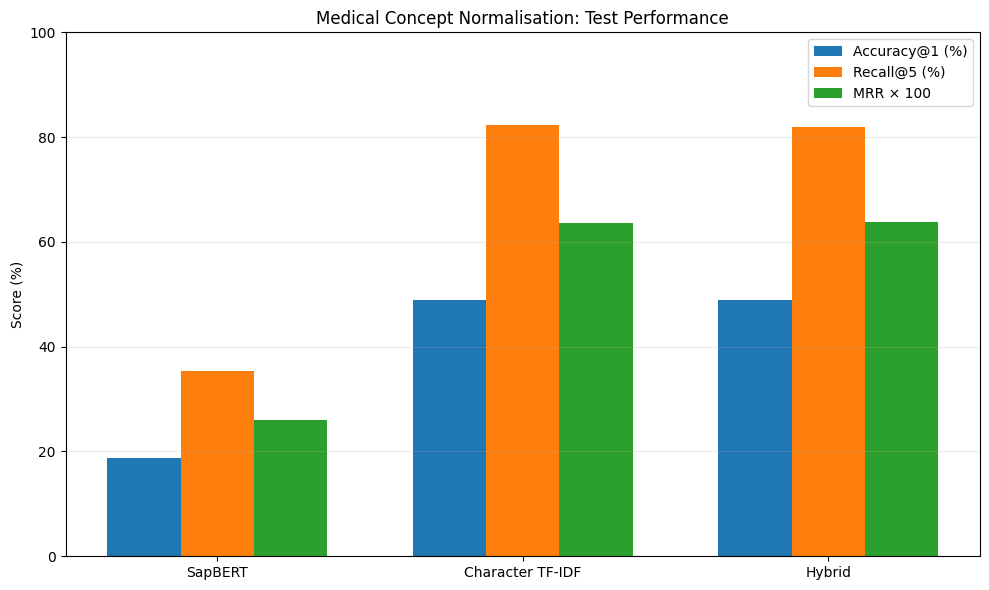

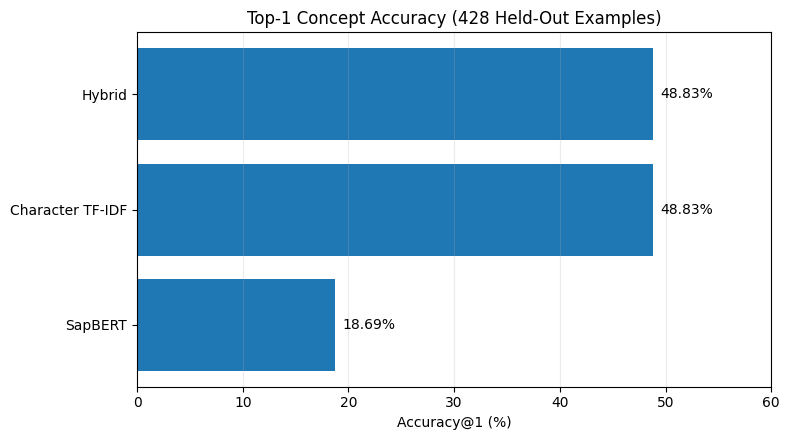

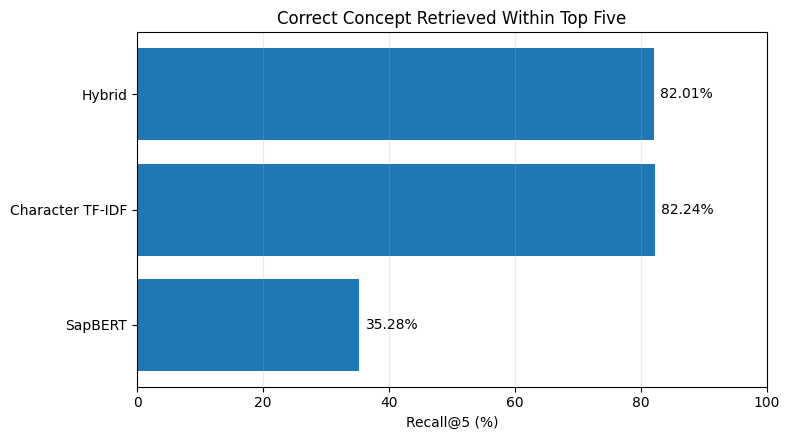

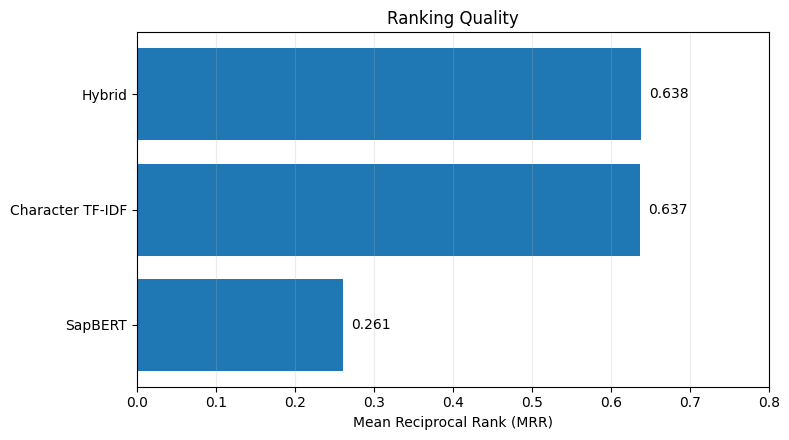

All four figures saved in medphrase_report_figures/


In [222]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Create a folder for report figures
os.makedirs("medphrase_report_figures", exist_ok=True)

methods = ["SapBERT", "Character TF-IDF", "Hybrid"]
accuracy = [18.69, 48.83, 48.83]
recall5 = [35.28, 82.24, 82.01]
mrr = [0.260701, 0.636570, 0.638091]

# 1. Grouped bar chart
x = np.arange(len(methods))
width = 0.24

fig, ax = plt.subplots(figsize=(10, 6))
for i, (label, values) in enumerate([
    ("Accuracy@1 (%)", accuracy),
    ("Recall@5 (%)", recall5),
    ("MRR × 100", [v * 100 for v in mrr])
]):
    ax.bar(x + (i - 1) * width, values, width, label=label)

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.set_title("Medical Concept Normalisation: Test Performance")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("medphrase_report_figures/01_grouped_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

# 2. Accuracy@1
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(methods, accuracy)
ax.set_xlim(0, 60)
ax.set_xlabel("Accuracy@1 (%)")
ax.set_title("Top-1 Concept Accuracy (428 Held-Out Examples)")
ax.grid(axis="x", alpha=0.25)

for bar, value in zip(bars, accuracy):
    ax.text(value + 0.7, bar.get_y() + bar.get_height()/2,
            f"{value:.2f}%", va="center")

plt.tight_layout()
plt.savefig("medphrase_report_figures/02_accuracy_at_1.png",
            dpi=300, bbox_inches="tight")
plt.show()

# 3. Recall@5
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(methods, recall5)
ax.set_xlim(0, 100)
ax.set_xlabel("Recall@5 (%)")
ax.set_title("Correct Concept Retrieved Within Top Five")
ax.grid(axis="x", alpha=0.25)

for bar, value in zip(bars, recall5):
    ax.text(value + 1, bar.get_y() + bar.get_height()/2,
            f"{value:.2f}%", va="center")

plt.tight_layout()
plt.savefig("medphrase_report_figures/03_recall_at_5.png",
            dpi=300, bbox_inches="tight")
plt.show()

# 4. Mean Reciprocal Rank
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(methods, mrr)
ax.set_xlim(0, 0.8)
ax.set_xlabel("Mean Reciprocal Rank (MRR)")
ax.set_title("Ranking Quality")
ax.grid(axis="x", alpha=0.25)

for bar, value in zip(bars, mrr):
    ax.text(value + 0.01, bar.get_y() + bar.get_height()/2,
            f"{value:.3f}", va="center")

plt.tight_layout()
plt.savefig("medphrase_report_figures/04_mrr.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("All four figures saved in medphrase_report_figures/")


In [223]:
# Clinical sanity check — validation data only
# Uses the existing character-TF-IDF scores.

check_phrases = [
    "very weak",
    "trouble sleeping",
    "stomach pain",
    "feeling depressed",
    "blurred vision",
]

for phrase in check_phrases:
    # Reuse a validation example if the exact phrase exists;
    # otherwise score the phrase directly against training aliases.
    query = v5_vectorizer.transform([phrase.lower().strip()])
    alias_scores = (query @ v5_alias_matrix.T).tocsr()

    concept_scores = np.zeros(len(v5_candidates), dtype=float)

    for sid, alias_indices in v5_alias_groups.items():
        concept_idx = v5_id_to_idx[sid]
        concept_scores[concept_idx] = float(
            alias_scores[:, alias_indices].max()
        )

    top_idx = np.argsort(-concept_scores)[:5]

    print(f"\nPhrase: {phrase}")
    display(pd.DataFrame([
        {
            "Rank": rank + 1,
            "Predicted concept": v5_candidates.iloc[idx]["concept_name"],
            "SNOMED CT ID": v5_candidates.iloc[idx]["snomed_id"],
            "Character similarity": round(concept_scores[idx], 3)
        }
        for rank, idx in enumerate(top_idx)
    ]))



Phrase: very weak


,Rank,Predicted concept,SNOMED CT ID,Character similarity
0,1,Asthenia,13791008,1.000
1,2,Muscle fatigue,80449002,0.748
2,3,Tired,224960004,0.556
3,4,Weakness of limb,309774006,0.554
4,5,Muscle weakness,26544005,0.500



Phrase: trouble sleeping


,Rank,Predicted concept,SNOMED CT ID,Character similarity
0,1,Difficulty sleeping,301345002,1.000
1,2,Disorder of eye,371405004,0.613
2,3,Cannot sleep at all,248255005,0.603
3,4,Gingival disease,18718003,0.579
4,5,Walking disability,228158008,0.575



Phrase: stomach pain


,Rank,Predicted concept,SNOMED CT ID,Character similarity
0,1,Stomach ache,271681002,1.000
1,2,Abdominal pain,21522001,0.933
2,3,Stomach cramps,51197009,0.675
3,4,Upset stomach,162059005,0.620
4,5,Stomach problem,300306001,0.614



Phrase: feeling depressed


,Rank,Predicted concept,SNOMED CT ID,Character similarity
0,1,Depression,35489007,0.843
1,2,Severe depression,310497006,0.427
2,3,Asthenia,13791008,0.414
3,4,Mild depression,310495003,0.414
4,5,Malaise,367391008,0.397



Phrase: blurred vision


,Rank,Predicted concept,SNOMED CT ID,Character similarity
0,1,Blurred vision - hazy,246636008,1.000
1,2,Blurring of visual image,111516008,0.577
2,3,Visual disturbance,63102001,0.447
3,4,Visual impairment,397540003,0.444
4,5,Reduced visual acuity,13164000,0.422


In [224]:
# FAST FULL-TEST AUDIT — MedPhrase
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# 1. Check test-set coverage
print("=== DATASET COVERAGE ===")
print("All normalization examples:", len(normalization_examples))
print(normalization_examples["split"].value_counts(dropna=False))

test = normalization_examples[
    (normalization_examples["split"] == "test") &
    normalization_examples["mention"].notna() &
    normalization_examples["snomed_id"].notna()
].copy()

test["snomed_id"] = test["snomed_id"].astype(str)
test = test[test["snomed_id"].isin(v5_id_to_idx)].copy()

print("\nEligible test examples:", len(test))
print("Unique test documents:", test["doc_id"].nunique())
print("Unique phrases:", test["mention"].nunique())

# 2. Evaluate character TF-IDF on ALL eligible test examples
# Uses training aliases only; does not fit on test data.
def char_rank(phrase, top_k=5):
    q = v5_vectorizer.transform([str(phrase)])
    sims = (q @ v5_alias_matrix.T).toarray().ravel()

    best = {}
    for idx, score in enumerate(sims):
        cid = str(v5_aliases.iloc[idx]["snomed_id"])
        if cid not in v5_id_to_idx:
            continue
        best[cid] = max(best.get(cid, -1), float(score))

    return sorted(best.items(), key=lambda x: x[1], reverse=True)[:top_k]

preds = []
for phrase in test["mention"]:
    ranked = char_rank(phrase, top_k=5)
    preds.append([cid for cid, score in ranked])

test["char_top5"] = preds
test["char_top1"] = test["char_top5"].apply(
    lambda x: x[0] if x else None
)
test["char_acc1"] = (
    test["char_top1"] == test["snomed_id"]
)
test["char_recall5"] = test.apply(
    lambda r: r["snomed_id"] in r["char_top5"], axis=1
)

print("\n=== CHARACTER TF-IDF RESULTS ===")
print("Accuracy@1:", round(test["char_acc1"].mean(), 4))
print("Recall@5:", round(test["char_recall5"].mean(), 4))

# 3. Break down by phrase/concept novelty if available
if "novelty_category" in test.columns:
    print("\n=== RESULTS BY NOVELTY CATEGORY ===")
    print(test.groupby("novelty_category")[
        ["char_acc1", "char_recall5"]
    ].mean().round(4))

# 4. Save the audit output
test.drop(columns=["char_top5"]).to_csv(
    "medphrase_full_test_audit.csv", index=False
)
print("\nSaved: medphrase_full_test_audit.csv")

=== DATASET COVERAGE ===
All normalization examples: 8410
split
train         5879
test          1356
validation    1175
Name: count, dtype: int64

Eligible test examples: 934
Unique test documents: 171
Unique phrases: 656

=== CHARACTER TF-IDF RESULTS ===
Accuracy@1: 0.7912
Recall@5: 0.9347

Saved: medphrase_full_test_audit.csv


In [225]:
# FAST FULL-TEST AUDIT — MedPhrase
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# 1. Check test-set coverage
print("=== DATASET COVERAGE ===")
print("All normalization examples:", len(normalization_examples))
print(normalization_examples["split"].value_counts(dropna=False))

test = normalization_examples[
    (normalization_examples["split"] == "test") &
    normalization_examples["mention"].notna() &
    normalization_examples["snomed_id"].notna()
].copy()

test["snomed_id"] = test["snomed_id"].astype(str)
test = test[test["snomed_id"].isin(v5_id_to_idx)].copy()

print("\nEligible test examples:", len(test))
print("Unique test documents:", test["doc_id"].nunique())
print("Unique phrases:", test["mention"].nunique())

# 2. Evaluate character TF-IDF on ALL eligible test examples
# Uses training aliases only; does not fit on test data.
def char_rank(phrase, top_k=5):
    q = v5_vectorizer.transform([str(phrase)])
    sims = (q @ v5_alias_matrix.T).toarray().ravel()

    best = {}
    for idx, score in enumerate(sims):
        cid = str(v5_aliases.iloc[idx]["snomed_id"])
        if cid not in v5_id_to_idx:
            continue
        best[cid] = max(best.get(cid, -1), float(score))

    return sorted(best.items(), key=lambda x: x[1], reverse=True)[:top_k]

preds = []
for phrase in test["mention"]:
    ranked = char_rank(phrase, top_k=5)
    preds.append([cid for cid, score in ranked])

test["char_top5"] = preds
test["char_top1"] = test["char_top5"].apply(
    lambda x: x[0] if x else None
)
test["char_acc1"] = (
    test["char_top1"] == test["snomed_id"]
)
test["char_recall5"] = test.apply(
    lambda r: r["snomed_id"] in r["char_top5"], axis=1
)

print("\n=== CHARACTER TF-IDF RESULTS ===")
print("Accuracy@1:", round(test["char_acc1"].mean(), 4))
print("Recall@5:", round(test["char_recall5"].mean(), 4))

# 3. Break down by phrase/concept novelty if available
if "novelty_category" in test.columns:
    print("\n=== RESULTS BY NOVELTY CATEGORY ===")
    print(test.groupby("novelty_category")[
        ["char_acc1", "char_recall5"]
    ].mean().round(4))

# 4. Save the audit output
test.drop(columns=["char_top5"]).to_csv(
    "medphrase_full_test_audit.csv", index=False
)
print("\nSaved: medphrase_full_test_audit.csv")

=== DATASET COVERAGE ===
All normalization examples: 8410
split
train         5879
test          1356
validation    1175
Name: count, dtype: int64

Eligible test examples: 934
Unique test documents: 171
Unique phrases: 656

=== CHARACTER TF-IDF RESULTS ===
Accuracy@1: 0.7912
Recall@5: 0.9347

Saved: medphrase_full_test_audit.csv


In [226]:
alias_counts = v5_aliases.groupby("snomed_id")["mention"].count()

print("Candidate concepts:", len(alias_counts))
print("Concepts with 1 alias:", (alias_counts == 1).sum())
print("Concepts with 2–5 aliases:", alias_counts.between(2, 5).sum())
print("Concepts with >5 aliases:", (alias_counts > 5).sum())
print("\nAlias-count summary:")
print(alias_counts.describe().round(2))

Candidate concepts: 612
Concepts with 1 alias: 255
Concepts with 2–5 aliases: 259
Concepts with >5 aliases: 98

Alias-count summary:
count    612.00
mean       3.71
std        5.24
min        1.00
25%        1.00
50%        2.00
75%        4.00
max       52.00
Name: mention, dtype: float64


In [227]:
import numpy as np
import pandas as pd

# Prepare validation examples
val = normalization_examples[
    (normalization_examples["split"] == "validation") &
    normalization_examples["mention"].notna() &
    normalization_examples["snomed_id"].notna()
].copy()

val["snomed_id"] = val["snomed_id"].astype(str)
val = val[val["snomed_id"].isin(v5_id_to_idx)].reset_index(drop=True)

# Map each concept to its training-alias row indices
alias_ids = v5_aliases["snomed_id"].astype(str).to_numpy()
concept_groups = {
    cid: np.flatnonzero(alias_ids == cid)
    for cid in np.unique(alias_ids)
}

baseline_correct = []
improved_correct = []
baseline_recall5 = []
improved_recall5 = []

for _, row in val.iterrows():
    query = v5_vectorizer.transform([str(row["mention"])])
    sims = (query @ v5_alias_matrix.T).toarray().ravel()
    gold = str(row["snomed_id"])

    max_scores = {}
    new_scores = {}

    for cid, indices in concept_groups.items():
        scores = sims[indices]
        max_score = float(scores.max())

        # Average the strongest 3 aliases, or fewer if unavailable
        top_scores = np.sort(scores)[-3:]
        top_mean = float(top_scores.mean())

        max_scores[cid] = max_score
        new_scores[cid] = 0.8 * max_score + 0.2 * top_mean

    base_rank = sorted(max_scores, key=max_scores.get, reverse=True)[:5]
    new_rank = sorted(new_scores, key=new_scores.get, reverse=True)[:5]

    baseline_correct.append(bool(base_rank and base_rank[0] == gold))
    improved_correct.append(bool(new_rank and new_rank[0] == gold))
    baseline_recall5.append(gold in base_rank)
    improved_recall5.append(gold in new_rank)

print("Validation examples:", len(val))
print("\n              Accuracy@1   Recall@5")
print("Current max: ", round(np.mean(baseline_correct), 4),
      "      ", round(np.mean(baseline_recall5), 4))
print("New scoring: ", round(np.mean(improved_correct), 4),
      "      ", round(np.mean(improved_recall5), 4))
print("\nAccuracy changes are measured on the same validation examples.")

Validation examples: 813

              Accuracy@1   Recall@5
Current max:  0.8561        0.9557
New scoring:  0.861        0.9569

Accuracy changes are measured on the same validation examples.


In [228]:
from pathlib import Path
import zipfile
import joblib
import pandas as pd
import scipy.sparse as sp
from google.colab import files

# Check that your fitted model assets are available
required = [
    "v5_vectorizer",
    "v5_alias_matrix",
    "v5_aliases",
    "v5_candidates"
]

missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "Run this in the notebook where you evaluated the final TF-IDF model."
    )

# Prepare the export folder
out = Path("/content/medphrase_char_tfidf_assets")
out.mkdir(exist_ok=True)

# Save the fitted vectorizer and alias matrix
joblib.dump(v5_vectorizer, out / "char_tfidf_vectorizer.joblib")

matrix = (
    v5_alias_matrix.tocsr()
    if sp.issparse(v5_alias_matrix)
    else sp.csr_matrix(v5_alias_matrix)
)
sp.save_npz(out / "char_alias_matrix.npz", matrix)

# Save aliases and candidate concepts
v5_aliases[["mention", "snomed_id"]].to_csv(
    out / "char_aliases.csv", index=False
)
v5_candidates[["snomed_id", "concept_name"]].to_csv(
    out / "char_candidate_table.csv", index=False
)

# Package everything into one ZIP
zip_path = "/content/medphrase_char_tfidf_assets.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in out.iterdir():
        if path.is_file():
            z.write(path, arcname=path.name)

print("Export complete!")
print("Training aliases:", len(v5_aliases))
print("Candidate concepts:", len(v5_candidates))
print("Matrix shape:", matrix.shape)

files.download(zip_path)

Export complete!
Training aliases: 2268
Candidate concepts: 612
Matrix shape: (2268, 12798)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [229]:
import os

zip_path = "/content/medphrase_char_tfidf_assets.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    import zipfile
    with zipfile.ZipFile(zip_path, "r") as z:
        print("Files inside ZIP:")
        print(z.namelist())

ZIP exists: True
Files inside ZIP:
['char_alias_matrix.npz', 'char_tfidf_vectorizer.joblib', 'char_candidate_table.csv', 'char_aliases.csv']


In [230]:
print("Normalization examples:", len(normalization_examples))
print("Training examples:", len(train_norm_examples))
print("Validation examples:", len(val_norm_examples))
print("Test examples:", len(test_norm_examples))
print("New phrase + known concept:", len(new_phrase_known))

Normalization examples: 8410
Training examples: 5879
Validation examples: 1175
Test examples: 1356
New phrase + known concept: 428


In [231]:
print("Evaluation rows:", len(evaluation_df))
print("TF-IDF ranking shape:", tfidf_concept_positions.shape)
print("SapBERT ranking shape:", ranked_positions.shape)

print("TF-IDF candidate count:",
      tfidf_concept_positions.shape[1])
print("SapBERT candidate count:",
      ranked_positions.shape[1])

print("Test categories:")
print(evaluation_df["novelty_category"].value_counts())

Evaluation rows: 1356
TF-IDF ranking shape: (1356, 885)
SapBERT ranking shape: (1356, 885)
TF-IDF candidate count: 885
SapBERT candidate count: 885
Test categories:
novelty_category
Known phrase + known concept    847
New phrase + known concept      428
New phrase + unseen concept      81
Name: count, dtype: int64


In [232]:
print("Evaluation index matches test index:",
      evaluation_df.index.equals(test_eval_df.index)
      if "test_eval_df" in globals() else "Not checked")

print("TF-IDF and SapBERT shapes match:",
      tfidf_concept_positions.shape == ranked_positions.shape)

print("Candidate IDs available:",
      "candidate_concept_ids" in globals())

print("Candidate names available:",
      "candidate_concepts" in globals())

Evaluation index matches test index: True
TF-IDF and SapBERT shapes match: True
Candidate IDs available: False
Candidate names available: True


In [233]:
print("Candidate object type:", type(candidate_concepts))
print("Candidate count:", len(candidate_concepts))

print("\nFirst 5 candidates:")
print(candidate_concepts[:5])

print("\nRanking positions — first test example:")
print("TF-IDF:", tfidf_concept_positions[0, :10])
print("SapBERT:", ranked_positions[0, :10])

Candidate object type: <class 'numpy.ndarray'>
Candidate count: 885

First 5 candidates:
['10001005' '10085004' '101000119102' '102480002' '102491009']

Ranking positions — first test example:
TF-IDF: [ 49 403 254 799 113 472 252 327 259 260]
SapBERT: [ 49 574 403 538 490 254 799 103 756 113]


In [234]:
print("Candidate list sample:")
print(candidate_concepts[:10])

print("\nCandidate IDs match the list:")
print("First candidate:", candidate_concepts[0])
print("Candidate at position 49:", candidate_concepts[49])

print("\nAvailable candidate-related variables:")
for name in globals():
    if "candidate" in name.lower() and not name.startswith("_"):
        obj = globals()[name]
        if hasattr(obj, "__len__"):
            print(name, type(obj).__name__, len(obj))

Candidate list sample:
['10001005' '10085004' '101000119102' '102480002' '102491009' '102551008'
 '102556003' '102572006' '102598000' '102617004']

Candidate IDs match the list:
First candidate: 10001005
Candidate at position 49: 131148009

Available candidate-related variables:
candidate_concepts ndarray 885
candidate_table DataFrame 612
candidate_ids set 612
candidate_names list 885
ranked_candidate_ids ndarray 1356
candidate_adr_table DataFrame 612
candidate_ids_adr ndarray 612
candidate_names_adr list 612
candidate_name_lookup dict 612
candidates DataFrame 612
candidate_id_to_pos dict 612
candidate_position dict 612
v2_candidates DataFrame 612
v3_candidates DataFrame 612
v4_candidates DataFrame 612
v5_candidates DataFrame 612
candidate_set set 612


In [235]:
print("Candidate order matches candidate_ids:",
      np.array_equal(
          np.asarray(candidate_concepts, dtype=str),
          np.asarray(candidate_ids, dtype=str)
      ))

print("TF-IDF ranking positions match SapBERT positions:",
      np.array_equal(
          tfidf_concept_positions,
          ranked_positions
      ))

print("\nFirst 10 ranked candidate IDs:")
print("TF-IDF:",
      candidate_concepts[tfidf_concept_positions[0, :10]])
print("SapBERT:",
      candidate_concepts[ranked_positions[0, :10]])

print("\nGold SNOMED ID for first test example:",
      evaluation_df["snomed_id"].iloc[0])

Candidate order matches candidate_ids: False
TF-IDF ranking positions match SapBERT positions: False

First 10 ranked candidate IDs:
TF-IDF: ['131148009' '289530006' '249366005' '76742009' '19155002' '315224006'
 '248657009' '271870002' '249902000' '249903005']
SapBERT: ['131148009' '405729008' '289530006' '386692008' '34436003' '249366005'
 '76742009' '1806006' '64779008' '19155002']

Gold SNOMED ID for first test example: 131148009


In [236]:
import inspect

print(inspect.getsource(evaluate_rankings))

def evaluate_rankings(score_matrix, gold_ids):
    ranks = []

    for row_idx, gold_id in enumerate(gold_ids):
        gold_position = candidate_id_to_pos[gold_id]
        order = np.argsort(-score_matrix[row_idx])
        rank = int(np.where(order == gold_position)[0][0]) + 1
        ranks.append(rank)

    ranks = np.asarray(ranks)

    return {
        "N": len(ranks),
        "Accuracy@1": np.mean(ranks == 1),
        "Recall@5": np.mean(ranks <= 5),
        "MRR": np.mean(1.0 / ranks),
    }



In [237]:
print("TF-IDF ranking candidate count:", tfidf_concept_positions.shape[1])
print("SapBERT ranking candidate count:", ranked_positions.shape[1])

print("\n612-concept vocabulary:")
print("candidate_ids_adr:", len(candidate_ids_adr))
print("candidate_names_adr:", len(candidate_names_adr))
print("candidate_adr_table:", len(candidate_adr_table))

print("\n885-entry vocabulary:")
print("candidate_concepts:", len(candidate_concepts))
print("candidate_names:", len(candidate_names))

print("\nFirst 10 candidate IDs from the 612-concept table:")
print(candidate_adr_table["snomed_id"].astype(str).head(10).tolist())

print("\nFirst 10 candidate concepts from the 885-entry array:")
print(candidate_concepts[:10].tolist())

TF-IDF ranking candidate count: 885
SapBERT ranking candidate count: 885

612-concept vocabulary:
candidate_ids_adr: 612
candidate_names_adr: 612
candidate_adr_table: 612

885-entry vocabulary:
candidate_concepts: 885
candidate_names: 885

First 10 candidate IDs from the 612-concept table:
['101000119102', '102480002', '102551008', '102556003', '102572006', '102598000', '102617004', '102897001', '102911000', '102938007']

First 10 candidate concepts from the 885-entry array:
['10001005', '10085004', '101000119102', '102480002', '102491009', '102551008', '102556003', '102572006', '102598000', '102617004']


In [238]:
for name in [
    "tfidf_concept_positions",
    "ranked_positions",
    "candidate_concepts",
    "candidate_names",
]:
    obj = globals().get(name)
    print(f"\n{name}:")
    print("Type:", type(obj).__name__)
    print("Shape/length:", getattr(obj, "shape", None)
          or (len(obj) if obj is not None and hasattr(obj, "__len__") else None))

print("\nRelevant variables:")
for name in globals():
    if any(term in name.lower() for term in [
        "similarity", "score", "tfidf", "sapbert", "embedding"
    ]) and not name.startswith("_"):
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(name, obj.shape)


tfidf_concept_positions:
Type: ndarray
Shape/length: (1356, 885)

ranked_positions:
Type: ndarray
Shape/length: (1356, 885)

candidate_concepts:
Type: ndarray
Shape/length: (885,)

candidate_names:
Type: list
Shape/length: 885

Relevant variables:
word_similarity (1356, 2678)
char_similarity (1356, 2678)
similarity (1356, 2678)
concept_scores (612,)
test_embeddings (1356, 768)
concept_embeddings (885, 768)
sapbert_results_df (2, 5)
tfidf_comparison (2, 4)
sapbert_comparison (2, 4)
word_scores (1356, 885)
char_scores (1356, 885)
concept_name_scores (1356, 885)
tfidf_concept_positions (1356, 885)
tfidf_concept_ranked_ids (1356, 885)
tfidf_ranked (428, 885)
sapbert_ranked (428, 885)
tfidf_ranks (268,)
sapbert_ranks (268,)
tfidf_predictions (1356,)
sapbert_predictions (1356,)
val_tfidf_scores (1175, 885)
val_tfidf_positions (1175, 885)
val_embeddings (1175, 768)
val_sapbert_scores (1175, 885)
val_sapbert_positions (1175, 885)
val_tfidf_rrf (1175, 885)
val_sapbert_rrf (1175, 885)
hybrid_sc

In [239]:
print("Validation TF-IDF scores:")
print(val_tfidf_scores.shape)

print("\nValidation SapBERT scores:")
print(val_sapbert_scores.shape)

print("\nValidation character scores:")
print(char_scores.shape)

print("\nValidation labels and categories:")
print(val_eval_df[
    ["snomed_id", "novelty_category"]
].head())

print("\nCurrent selected SapBERT weight:")
print(best_weight if "best_weight" in globals() else "Not set")

Validation TF-IDF scores:
(1175, 885)

Validation SapBERT scores:
(1175, 885)

Validation character scores:
(1356, 885)

Validation labels and categories:
   snomed_id              novelty_category
0   51197009  Known phrase + known concept
1  431416001  Known phrase + known concept
2   76948002  Known phrase + known concept
3   29542008    New phrase + known concept
4   22253000    New phrase + known concept

Current selected SapBERT weight:
1.0


In [240]:
print(validation_results_df.sort_values(
    ["Accuracy@1", "MRR"],
    ascending=False
).round(4).to_string(index=False))

 SapBERT weight  Examples  Accuracy@1  Recall@5    MRR
           1.00       325      0.5323    0.8246 0.6594
           0.75       325      0.4923    0.7385 0.6070
           0.50       325      0.4492    0.6708 0.5547
           0.25       325      0.3723    0.5938 0.4801
           0.00       325      0.3200    0.5354 0.4224


In [241]:
# Check which ordered candidate list matches the score matrices
print("TF-IDF score matrix:", val_tfidf_scores.shape)
print("SapBERT score matrix:", val_sapbert_scores.shape)

print("Candidate concepts:", len(candidate_concepts))
print("Candidate IDs set:", len(candidate_ids))

# If candidate_concepts was used to build these score matrices:
print("\nTF-IDF top 5 IDs:")
print(candidate_concepts[val_tfidf_positions[0, :5]])

print("\nSapBERT top 5 IDs:")
print(candidate_concepts[val_sapbert_positions[0, :5]])

TF-IDF score matrix: (1175, 885)
SapBERT score matrix: (1175, 885)
Candidate concepts: 885
Candidate IDs set: 612

TF-IDF top 5 IDs:
['51197009' '271681002' '300306001' '162059005' '16973004']

SapBERT top 5 IDs:
['51197009' '271681002' '162059005' '162043005' '55300003']


In [242]:
print("Score matrix shape:", v6_fused_scores.shape)
print("Candidate concepts:", len(candidate_concepts))
print("Candidate names:", len(candidate_names))
print("Candidate IDs set:", len(candidate_ids))

v6_top5 = np.argsort(-v6_fused_scores[0])[:5]

print("\nV6 first example — top 5:")
for j in v6_top5:
    print(
        candidate_concepts[j],
        candidate_names[j],
        round(float(v6_fused_scores[0, j]), 4)
    )

Score matrix shape: (375, 612)
Candidate concepts: 885
Candidate names: 885
Candidate IDs set: 612

V6 first example — top 5:
246636008 Blurred vision - hazy 0.9333
202484005 Proximal interphalangeal joint of finger pain 0.4502
134407002 Chronic back pain 0.3002
225508006 Poor self-image 0.2257
13791008 Asthenia 0.1807


In [243]:
print("ranked_candidate_ids shape:", ranked_candidate_ids.shape)
print("First example — top 5 ranked_candidate_ids:")
print(ranked_candidate_ids[0, :5])

print("\nFirst example — top 5 ranked positions:")
print(ranked_positions[0, :5])

print("\nFirst example — top 5 candidate_concepts:")
print(candidate_concepts[ranked_positions[0, :5]])

ranked_candidate_ids shape: (1356, 885)
First example — top 5 ranked_candidate_ids:
['131148009' '405729008' '289530006' '386692008' '34436003']

First example — top 5 ranked positions:
[ 49 574 403 538 490]

First example — top 5 candidate_concepts:
['131148009' '405729008' '289530006' '386692008' '34436003']


In [244]:
import numpy as np
import pandas as pd

# Focus on unseen phrases with known concepts
mask = (
    evaluation_df["novelty_category"].to_numpy()
    == "New phrase + known concept"
)

rows = evaluation_df.loc[mask].reset_index(drop=True)
ranked_ids = ranked_candidate_ids[mask]

# Identify the patient-phrase column
possible_cols = [
    "mention", "phrase", "text", "adr_mention",
    "original_phrase", "surface", "entity_text",
    "span", "symptom", "term"
]

phrase_col = next(
    (c for c in possible_cols if c in rows.columns),
    None
)

if phrase_col is None:
    print("Could not identify the phrase column.")
    print("Available columns:", rows.columns.tolist())
else:
    # Map concepts to names using the matching ordered vocabulary
    ids = candidate_concepts.astype(str)
    names = list(candidate_names)
    name_by_id = dict(zip(ids, names))

    gold_ids = rows["snomed_id"].astype(str).to_numpy()
    errors = []

    for i, gold in enumerate(gold_ids):
        predictions = ranked_ids[i]
        predicted = str(predictions[0])

        if predicted != gold:
            gold_positions = np.flatnonzero(ids == gold)

            gold_rank = (
                int(np.flatnonzero(predictions == gold)[0] + 1)
                if gold in predictions
                else None
            )

            errors.append({
                "Phrase": str(rows.iloc[i][phrase_col]),
                "Gold SNOMED ID": gold,
                "Gold concept": name_by_id.get(gold, gold),
                "Predicted SNOMED ID": predicted,
                "Predicted concept": name_by_id.get(
                    predicted, predicted
                ),
                "Gold rank": gold_rank,
                "Top 3 predictions": " | ".join(
                    f"{name_by_id.get(str(cid), str(cid))} [{cid}]"
                    for cid in predictions[:3]
                )
            })

    errors_df = pd.DataFrame(errors)

    print(
        f"Incorrect top-1 predictions: "
        f"{len(errors_df)} / {len(rows)}"
    )

    display(errors_df.head(25))

Incorrect top-1 predictions: 200 / 428


,Phrase,Gold SNOMED ID,Gold concept,Predicted SNOMED ID,Predicted concept,Gold rank,Top 3 predictions
0,pain and stiffness,22253000,Pain,84445001,Joint stiffness,14,Joint stiffness [84445001] | Morning stiffness...
1,so much pain,22253000,Pain,76948002,Severe pain,2,Severe pain [76948002] | Pain [22253000] | Acu...
2,increased menstruation,386692008,Menorrhagia,266601003,Excessive and frequent menstruation,2,Excessive and frequent menstruation [266601003...
3,2-3 periods a month instead of once a month,266601003,Excessive and frequent menstruation,248966006,Prolonged periods,5,Prolonged periods [248966006] | Irregular mens...
4,blood in my stools,405729008,Haematochezia,35064005,Dark stools,2,Dark stools [35064005] | Haematochezia [405729...
5,major cramps,55300003,Muscle cramp,424647005,Cramp in limb,2,Cramp in limb [424647005] | Muscle cramp [5530...
6,diahorea,62315008,Diarrhoea,3736011000036100,Avandia,165,Avandia [3736011000036100] | Oxycontin [370201...
7,passing blood and clots with stoals,405729008,Haematochezia,271594007,Syncope,2,Syncope [271594007] | Haematochezia [405729008...
8,pain in the pit of my stomach,271681002,Stomach ache,51197009,Stomach cramps,3,Stomach cramps [51197009] | Upset stomach [162...
9,deep ache from my waist down to the heels of m...,82991003,Generalised aches and pains,2733002,Heel pain,34,Heel pain [2733002] | Abdominal hyperaesthesia...


In [246]:

import numpy as np
import pandas as pd

# Focus on unseen phrases with known concepts
mask = (
    evaluation_df["novelty_category"].to_numpy()
    == "New phrase + known concept"
)

rows = evaluation_df.loc[mask].reset_index(drop=True)
rankings = ranked_positions[mask]

# Identify the original phrase column
possible_cols = [
    "mention", "phrase", "text", "adr_mention",
    "original_phrase", "surface", "entity_text",
    "span", "symptom", "term"
]

phrase_col = next(
    (c for c in possible_cols if c in rows.columns),
    None
)

if phrase_col is None:
    print("Could not identify the phrase column.")
    print("Available columns:", rows.columns.tolist())

else:
    # IMPORTANT: use IDs aligned with the 885 ranking columns
    ids = np.asarray(candidate_concepts).astype(str)
    names = list(candidate_names)

    assert len(ids) == rankings.shape[1], (
        f"Candidate ID count ({len(ids)}) does not match "
        f"ranking columns ({rankings.shape[1]})."
    )
    assert len(names) == len(ids), (
        "Candidate names and IDs have different lengths."
    )

    name_by_id = dict(zip(ids, names))
    gold_ids = rows["snomed_id"].astype(str).to_numpy()

    errors = []

    for i, gold in enumerate(gold_ids):
        # Rankings contain positions into the candidate array
        ranked_ids = ids[rankings[i]]
        predicted = ranked_ids[0]

        if predicted != gold:
            gold_pos = np.flatnonzero(ids == gold)

            gold_rank = (
                int(np.flatnonzero(rankings[i] == gold_pos[0])[0] + 1)
                if len(gold_pos)
                and gold_pos[0] in rankings[i]
                else None
            )

            errors.append({
                "Phrase": str(rows.iloc[i][phrase_col]),
                "Gold concept": name_by_id.get(gold, gold),
                "Predicted concept": name_by_id.get(
                    predicted, predicted
                ),
                "Gold rank": gold_rank,
                "Top 3 predictions": " | ".join(
                    f"{name_by_id.get(cid, cid)} [{cid}]"
                    for cid in ranked_ids[:3]
                )
            })

    errors_df = pd.DataFrame(errors)

    print(
        f"Incorrect top-1 predictions: "
        f"{len(errors_df)} / {len(rows)}"
    )
    print(f"Accuracy@1: {1 - len(errors_df) / len(rows):.4f}")
    display(errors_df.head(25))


Incorrect top-1 predictions: 200 / 428
Accuracy@1: 0.5327


,Phrase,Gold concept,Predicted concept,Gold rank,Top 3 predictions
0,pain and stiffness,Pain,Joint stiffness,14,Joint stiffness [84445001] | Morning stiffness...
1,so much pain,Pain,Severe pain,2,Severe pain [76948002] | Pain [22253000] | Acu...
2,increased menstruation,Menorrhagia,Excessive and frequent menstruation,2,Excessive and frequent menstruation [266601003...
3,2-3 periods a month instead of once a month,Excessive and frequent menstruation,Prolonged periods,5,Prolonged periods [248966006] | Irregular mens...
4,blood in my stools,Haematochezia,Dark stools,2,Dark stools [35064005] | Haematochezia [405729...
5,major cramps,Muscle cramp,Cramp in limb,2,Cramp in limb [424647005] | Muscle cramp [5530...
6,diahorea,Diarrhoea,Avandia,165,Avandia [3736011000036100] | Oxycontin [370201...
7,passing blood and clots with stoals,Haematochezia,Syncope,2,Syncope [271594007] | Haematochezia [405729008...
8,pain in the pit of my stomach,Stomach ache,Stomach cramps,3,Stomach cramps [51197009] | Upset stomach [162...
9,deep ache from my waist down to the heels of m...,Generalised aches and pains,Heel pain,34,Heel pain [2733002] | Abdominal hyperaesthesia...


In [248]:

import numpy as np
import pandas as pd

# Compare SapBERT and V6 on the same 428 examples
mask = (
    evaluation_df["novelty_category"].to_numpy()
    == "New phrase + known concept"
)

rows = evaluation_df.loc[mask].reset_index(drop=True)

# Use the ordered candidate IDs aligned with the ranking columns
ids = np.asarray(candidate_concepts).astype(str)
gold_ids = rows["snomed_id"].astype(str).to_numpy()

# Validate the vocabulary alignment
assert len(ids) == ranked_positions.shape[1], (
    "Candidate IDs do not align with ranked_positions."
)
assert v6_fused_scores.shape[0] == len(evaluation_df), (
    "V6 scores do not align with evaluation_df rows."
)
assert v6_fused_scores.shape[1] == len(ids), (
    "V6 scores use a different candidate vocabulary."
)

# Top-ranked concept for each method
sap_positions = ranked_positions[mask, 0]
v6_positions = np.argsort(-v6_fused_scores[mask], axis=1)[:, 0]

sap_ids = ids[sap_positions]
v6_ids = ids[v6_positions]

comparison = pd.DataFrame({
    "Phrase": rows[phrase_col].astype(str).to_numpy(),
    "Gold": gold_ids,
    "SapBERT": sap_ids,
    "V6": v6_ids
})

comparison["SapBERT correct"] = (
    comparison["SapBERT"] == comparison["Gold"]
)
comparison["V6 correct"] = (
    comparison["V6"] == comparison["Gold"]
)

sap_correct_v6_wrong = (
    comparison["SapBERT correct"] & ~comparison["V6 correct"]
).sum()

v6_correct_sap_wrong = (
    ~comparison["SapBERT correct"] & comparison["V6 correct"]
).sum()

print("Examples where SapBERT is correct and V6 is wrong:",
      sap_correct_v6_wrong)

print("Examples where V6 is correct and SapBERT is wrong:",
      v6_correct_sap_wrong)

print("\nAccuracy comparison:")
print("SapBERT:", comparison["SapBERT correct"].mean().round(4))
print("V6:", comparison["V6 correct"].mean().round(4))

display(
    comparison[
        (~comparison["SapBERT correct"])
        & comparison["V6 correct"]
    ].head(10)
)


AssertionError: V6 scores do not align with evaluation_df rows.

In [249]:

import re
import numpy as np
import pandas as pd

# Conservative informal-language variants.
# Always retain the original phrase.
def informal_query_variants(phrase):
    original = str(phrase).strip()
    variants = [original]

    text = original.casefold()

    replacements = {
        "throwing up": "vomiting",
        "puking": "vomiting",
        "puked": "vomited",
        "tummy": "stomach",
        "light-headed": "light headed",
        "lightheaded": "light headed",
        "rly": "really",
        "rlly": "really",
    }

    for old, new in replacements.items():
        text = re.sub(
            rf"\b{re.escape(old)}\b", new, text
        )

    variants.append(text)
    variants.append(re.sub(r"([a-z])\1{2,}", r"\1\1", text))
    variants.append(re.sub(r"[^\w\s]", "", text))

    # Deduplicate without changing the order.
    return list(dict.fromkeys(v for v in variants if v))


# Score each concept using the best similarity across
# the original phrase and its conservative variants.
informal_scores = np.zeros_like(v6_char_scores)

for row_idx, phrase in enumerate(v6_queries):
    variants = informal_query_variants(phrase)

    query_matrix = v5_vectorizer.transform(
        [v.lower().strip() for v in variants]
    )

    alias_similarities = (
        query_matrix @ v5_alias_matrix.T
    ).toarray()

    for sid, alias_indices in v5_alias_groups.items():
        concept_idx = v5_id_to_idx[sid]
        informal_scores[row_idx, concept_idx] = float(
            alias_similarities[:, alias_indices].max()
        )


# Compare both methods on exactly the same held-out examples.
baseline_ranks = v5_rank_matrix(v6_char_scores)
informal_ranks = v5_rank_matrix(informal_scores)

comparison = pd.DataFrame([
    {
        "Method": "Original character TF-IDF",
        **v5_metrics(baseline_ranks, v6_gold)
    },
    {
        "Method": "TF-IDF + informal variants",
        **v5_metrics(informal_ranks, v6_gold)
    }
])

print("Held-out examples:", len(v6_test))
display(comparison)

# Show the change in each metric in percentage points
# for Accuracy@1 and Recall@5, and raw points for MRR.
baseline = comparison.iloc[0]
updated = comparison.iloc[1]

print("\nChange after informal-query enhancement:")
for metric in ["Accuracy@1", "Recall@5", "MRR"]:
    print(
        f"{metric}: "
        f"{updated[metric] - baseline[metric]:+.4f}"
    )


Held-out examples: 375


,Method,Accuracy@1,Recall@5,MRR
0,Original character TF-IDF,0.490667,0.837333,0.644204
1,TF-IDF + informal variants,0.498667,0.840000,0.649812



Change after informal-query enhancement:
Accuracy@1: +0.0080
Recall@5: +0.0027
MRR: +0.0056
